# SafeInvest：从风险预算到三产品菜单的开发研究

**阶段：模型开发与反方核查；2026-10-17。不是提交论文，也不是最终参数批准。**

这份笔记回答三个具体问题：不使用缺乏偏好依据的 $\lambda=10/4/1$ 后，如何定义目标；同样的目标如何产生三个候选产品；哪些结果足够稳定、哪些仍然需要审核。

主要进展：232个放宽规格组合完成9个政策情形、完整情景五折验证及1,000次完整重选bootstrap；另对172个严格正权重组合执行相同内外层学习。较早的有限期限执行原型、费用观测和年份顺序压力检查保留放宽菜单作为对照；严格菜单的新执行研究见10.5–10.9。主要风险发现：原经验规则的B/C/E分配均贴在训练超限边界；A的可行性结论会随重抽样翻转；只按增长决定是否交易，会明显增加原分配的回撤超限。内层选择训练余量提供了新的严格三资产候选，仍需后续审定。

执行阶段进一步比较首次超限后持仓等待、两类局部门槛、逐路径保护、训练选择的风险调整交易规则和三目标更新规则。逐路径保护在五档费用下没有增加持仓不动的决定；风险调整门槛改善了增长和费用，但C的折外超限为14/120，仍未保持10%参考频率。允许目标更新的18个候选中，六个训练环境均选择不更新的简单控制器。下文同时保存这些负面结果，不能把训练通过替代为未来安全证明。

**数据历史必须保留。** 本轮只使用开发情景 1–120。V1 曾读过 121–180 的评估结果，故本轮不能声称有一个尚未看过的最终测试集。新实验流程在本轮选型前写入协议，但开发数据此前已被使用；“事先规定流程”不等于“数据未见”。没有重新生成 V1 论文、没有上传 CMT。

**题面规格也需要区分。** 题面写每个产品使用三类资产；以下232候选允许零权重，是放宽该规格的研究对照，不能直接视为最终三资产产品。三类资产均为正权重的补充诊断另列，保持同一内外层选择流程；当前网格最小正点5%来自分辨率，不是从问卷识别的资产下限。

In [1]:
from pathlib import Path
import hashlib
import base64
import html
import json
import sys
import numpy as np
import pandas as pd
from IPython.display import display, HTML

ROOT = Path.cwd().resolve()
if not (ROOT / 'docs/risk_menu_development_protocol.json').exists():
    ROOT = ROOT.parent
assert (ROOT / 'docs/risk_menu_development_protocol.json').exists()
R = ROOT / 'results/model_review/risk_menu_v1'
S = ROOT / 'results/model_review/simultaneous_static_risk_v1'
sys.path.insert(0, str(ROOT / 'research'))
from safeinvest_research.metrics import discrete_cvar
def readj(path):
    return json.loads(Path(path).read_text())
def sha(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()
def show(df, formats=None):
    selected = {}
    for name in df.select_dtypes(include='number'):
        values = df[name].dropna().to_numpy()
        if len(values) and np.all(np.abs(values - np.rint(values)) < 1e-12):
            selected[name] = '{:,.0f}'
    selected.update(formats or {})
    display(df.style.format(selected, na_rep='—').hide(axis='index'))
def figure(path, alt):
    encoded = base64.b64encode(Path(path).read_bytes()).decode('ascii')
    display(HTML('<img alt="' + html.escape(alt, quote=True) + '" src="data:image/png;base64,'
                 + encoded + '" style="max-width:100%;height:auto">'))
protocol = readj(ROOT / 'docs/risk_menu_development_protocol.json')
full = readj(R / 'full_development_menus.json')
primary = full['alpha_10__risk_only']
grid = pd.read_csv(R / 'grid_by_client.csv')
oof = pd.read_csv(R / 'validation_oof_summary.csv').rename(columns={
    'assigned_test_paths': 'assigned_paths', 'review_test_paths': 'review_paths',
    'total_test_paths': 'total_paths'})
oof_paths = pd.read_csv(R / 'validation_oof_paths.csv')
tail = [{'case': case, 'client': client, 'cvar90_mdd': float(discrete_cvar(g['mdd'].to_numpy()))}
        for (case, client), g in oof_paths[oof_paths['assigned']].groupby(['case', 'client'])]
oof = oof.merge(pd.DataFrame(tail), on=['case', 'client'], how='left', validate='one_to_one')
boot = readj(R / 'bootstrap/alpha_10__risk_only/summary.json')
structure = readj(ROOT / 'results/model_review/development_structure.json')
audit = readj(R / 'independent_audit.json')
assert primary['n_training'] == 120
assert grid['candidate_index'].nunique() == 232
assert audit['passed'] and audit['final_scenarios_loaded'] is False
assert boot['replicates'] == 1000
print('仅开发集：120情景；232候选；5个给定客户事件；未载入最终集。')
print('独立检查次数：', audit['total_check_invocations'])

仅开发集：120情景；232候选；5个给定客户事件；未载入最终集。
独立检查次数： 79206


## 1. 数学目标与各参数的身份

名义资产持仓扣除实际转移费用后取得当年收益，再除以累计价格指数，得到实际财富 $R_t$。保留扣费前的起点 $R_0=100$，初次配置费计入随后路径；无新增投入和退出现金流。

$$G_H(\pi)=\frac1H\mathbb E\!\left[\log\frac{R_H^\pi}{100}\right],\qquad
D_H^\pi=\max_{0\le s\le t\le H}\left(1-\frac{R_t^\pi}{R_s^\pi}\right).$$

以年化期望对数净实际增长为目标，在完整客户期限内约束 $\Pr(D_H^\pi>L)\le\alpha$。$L$ 和 $H$ 来自问卷；$\alpha$ 是我们明确提出的服务政策。对数目标本身也含偏好选择，不能称为完全没有风险偏好。它便于复利、费用和不同期限的解释，但不等于最大化平均财富或保证个人损失上限。$\exp(G_H)-1$ 也不是平均CAGR或中位CAGR；题目要求的中位和P10增长另从各条路径的实际CAGR统计。

旧 $\lambda$ 没有问卷校准依据，并会与期限产生不同的经济交换率，故退出本轮主目标。$\alpha=10\%$ 保留为参考政策，同时比较 5% 和 20%；不是从收益最大的结果倒推出“正确”风险偏好。

频率之外同时报告 $\mathbb E[(D_H-L)_+]$ 和最差 10% 概率质量的平均回撤 CVaR90。它们揭示超限严重度，本轮没有给严重度再加一个未经校准的硬门槛。只按年观察的最大回撤会漏掉年内低谷，这是数据分辨率的限制。

普通波动用每条路径年度净实际收益的样本标准差 $\sigma_H$ 描述，并报告跨情景中位数；最大回撤和其P90/CVaR90另刻画路径中的较大损失。标准差不记录收益发生顺序，也不是损失上限，不能替代回撤指标。

## 2. 固定流程：能重现什么，不能推断什么

放宽规格的候选是三资产单纯形上的5个百分点网格，加精确等权，共232个。它允许零权重；各资产都正权重的规格在后续对照中单列。每年初恢复固定目标，实际转移一次收费0.25%。当前结果只适用于该执行政策。未来加入不交易、费用门槛或目标更新，必须重新验证完整政策，不能继承这里的风险结论。

菜单先最大化五个给定客户中可自动分配的人数，再最小化已覆盖客户相对其可行网格最优组合的最大增长损失，再最小化平均损失。五个客户只是题目中的五个设计案例；没有假设他们代表真实客户比例。这是一个显式的规范性设计选择。

这里的公平尺度是每年的log增长差；相同年化差值对30年和6年的终值影响不同。覆盖优先也意味着愿意为增加一个可服务案例牺牲其他案例的增长。不能把它称为问卷唯一推导出的“公平最优”。

若一个或两个产品已达到同样的全局目标，额外产品按事先规定的H=15增长—CVaR90前沿补充，并标注不是由客户需求识别。本轮参考情形恰好需要三个。名称按H=15的CVaR90排序，另检查其它给定期限是否颠倒。

五折每次96条完整路径训练、24条路径评估；**整套菜单与客户分配均只在训练部分重选**。对被转介的客户，结果留空，不虚构顾问收益或第四个兜底产品。折外结果来自不同训练菜单，训练集重叠；不对合并超限数套用一个独立二项式风险证书。

P10/P90用经验分布的广义逆（`inverted_cdf`），中位数用两个中间值平均；CVaR正确处理分数尾部样本。损失与L相差不超过1e−12视为浮点相等，不是额外经济损失额度。

In [2]:
clients = pd.DataFrame(protocol['clients'])
show(clients, {'loss_tolerance': '{:.0%}'})
print('折叠和重抽样种子、选择优先级、费用与量化规则均在 docs/risk_menu_development_protocol.json。')

name,horizon,loss_tolerance,liquidity
A,5,10%,high
B,15,25%,medium
C,30,40%,low
D,25,15%,medium
E,6,35%,high


折叠和重抽样种子、选择优先级、费用与量化规则均在 docs/risk_menu_development_protocol.json。


## 3. 资产与流动性：先检验标签是否有经济依据

“票据代理”不是无风险现金。开发情景中的名义负收益和实际购买力损失都需要保留。年度描述混合了同一路径的30年，不能把3,600个年度记录当作3,600条独立路径。以下频率只是该混合分布的描述。

题目没有提款金额、提款日期、资产结算延迟或紧急变现折价。因此，“high=30%票据”并没有可识别的标定依据。主风险前沿不附加票据下限；另列30%/10%/0和50%/20%/0两个政策对照。**主风险前沿尚不能完成流动性维度的客户适配。** 面向实际服务，需要先问提款金额/日期及账户外备用金，信息不全时转介确认。

asset,mean annual real return,nominal negative annual share,real negative annual share
equity,8.28%,24.22%,29.92%
government_bond,2.06%,26.83%,41.25%
bill_proxy,1.29%,4.58%,31.92%



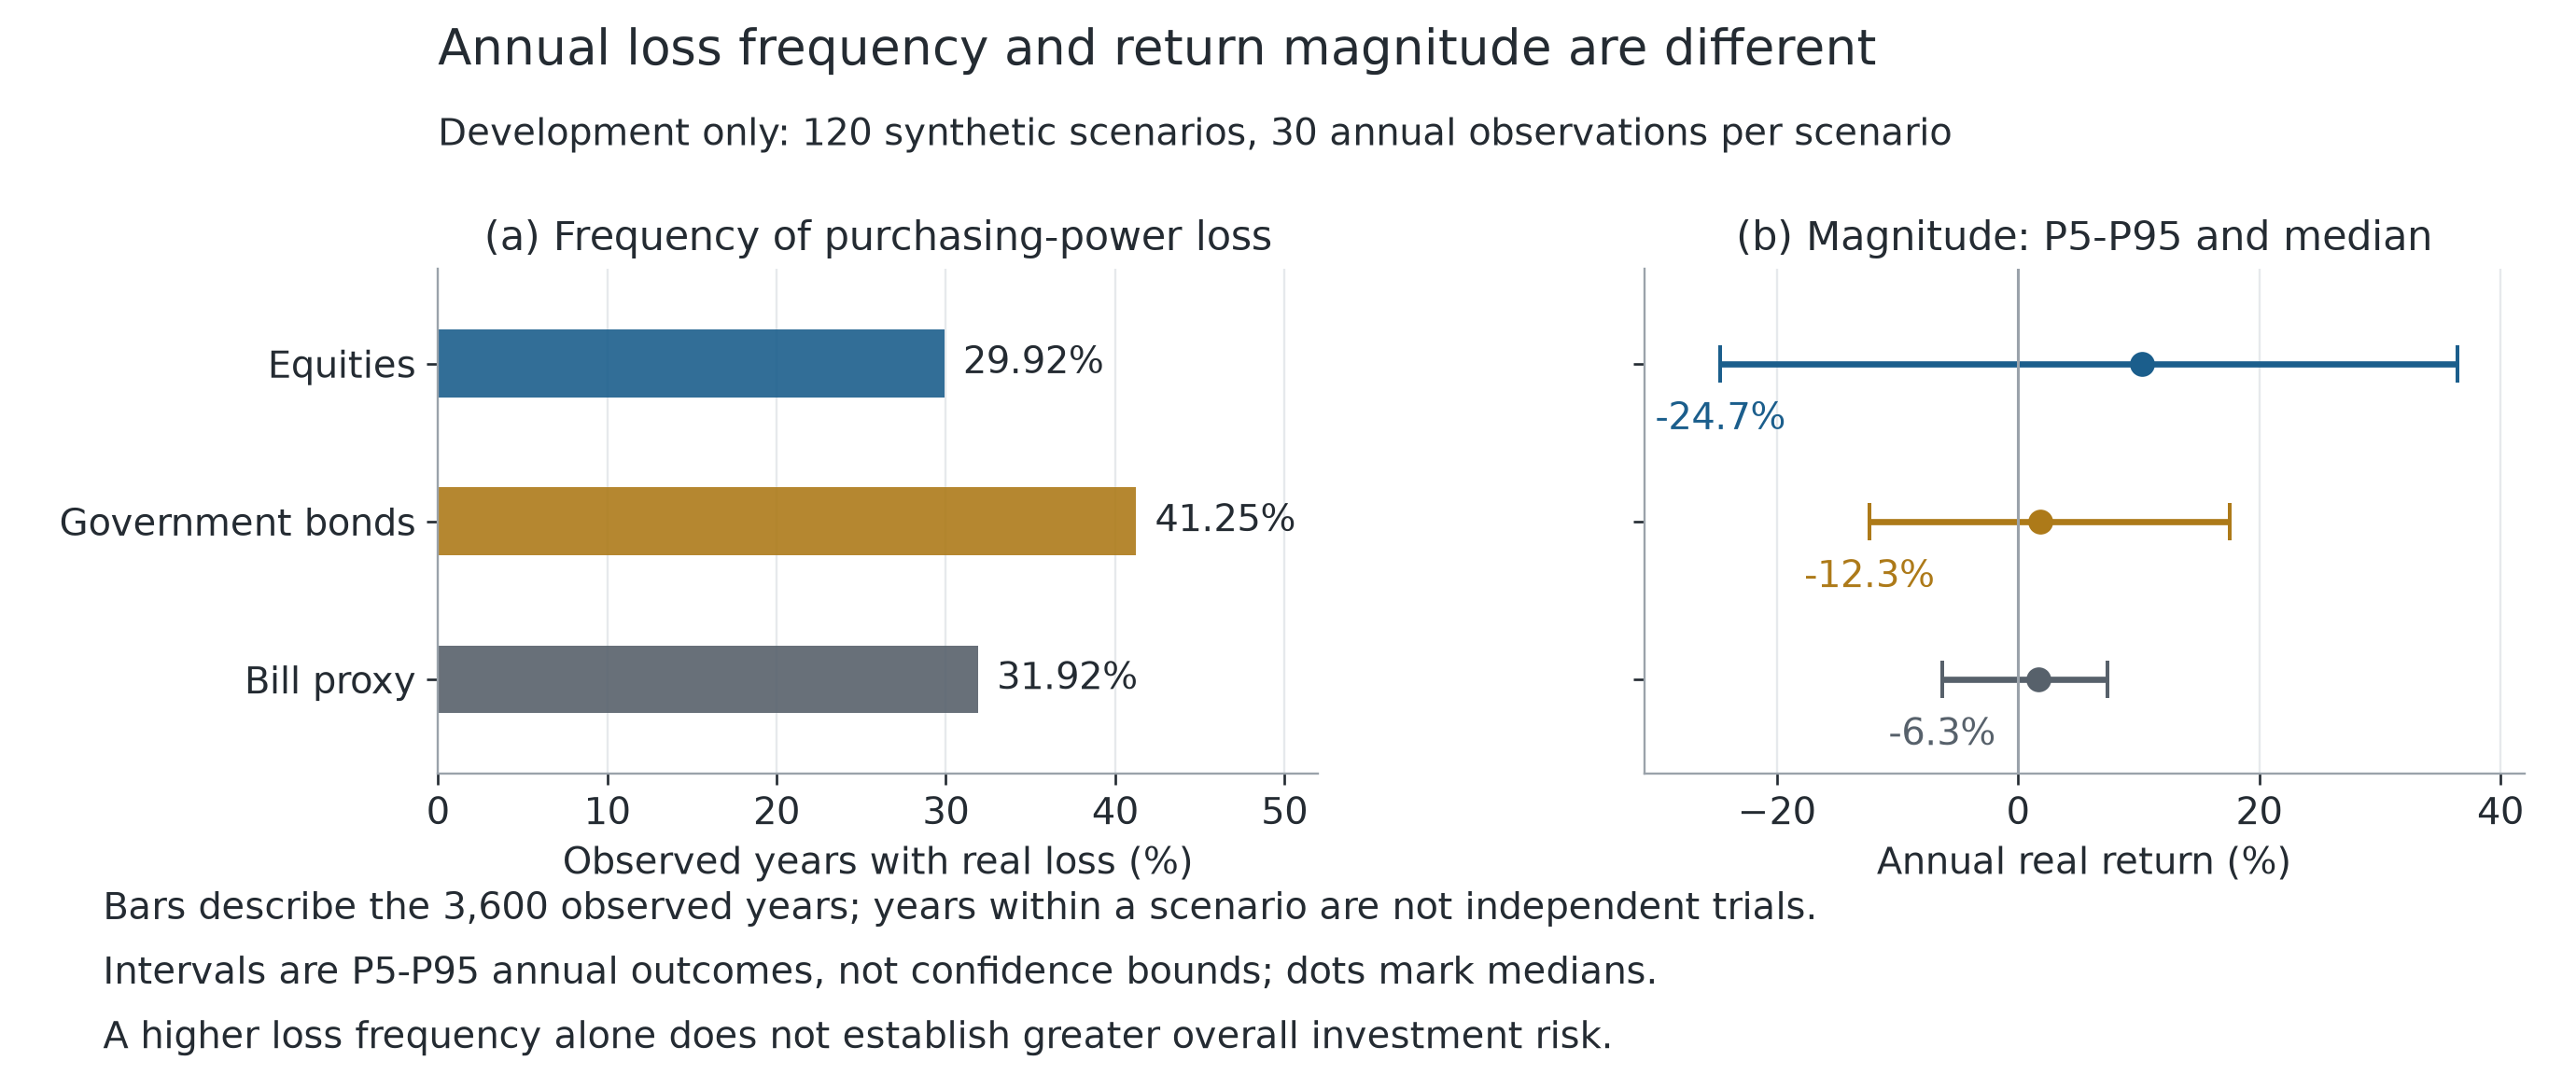


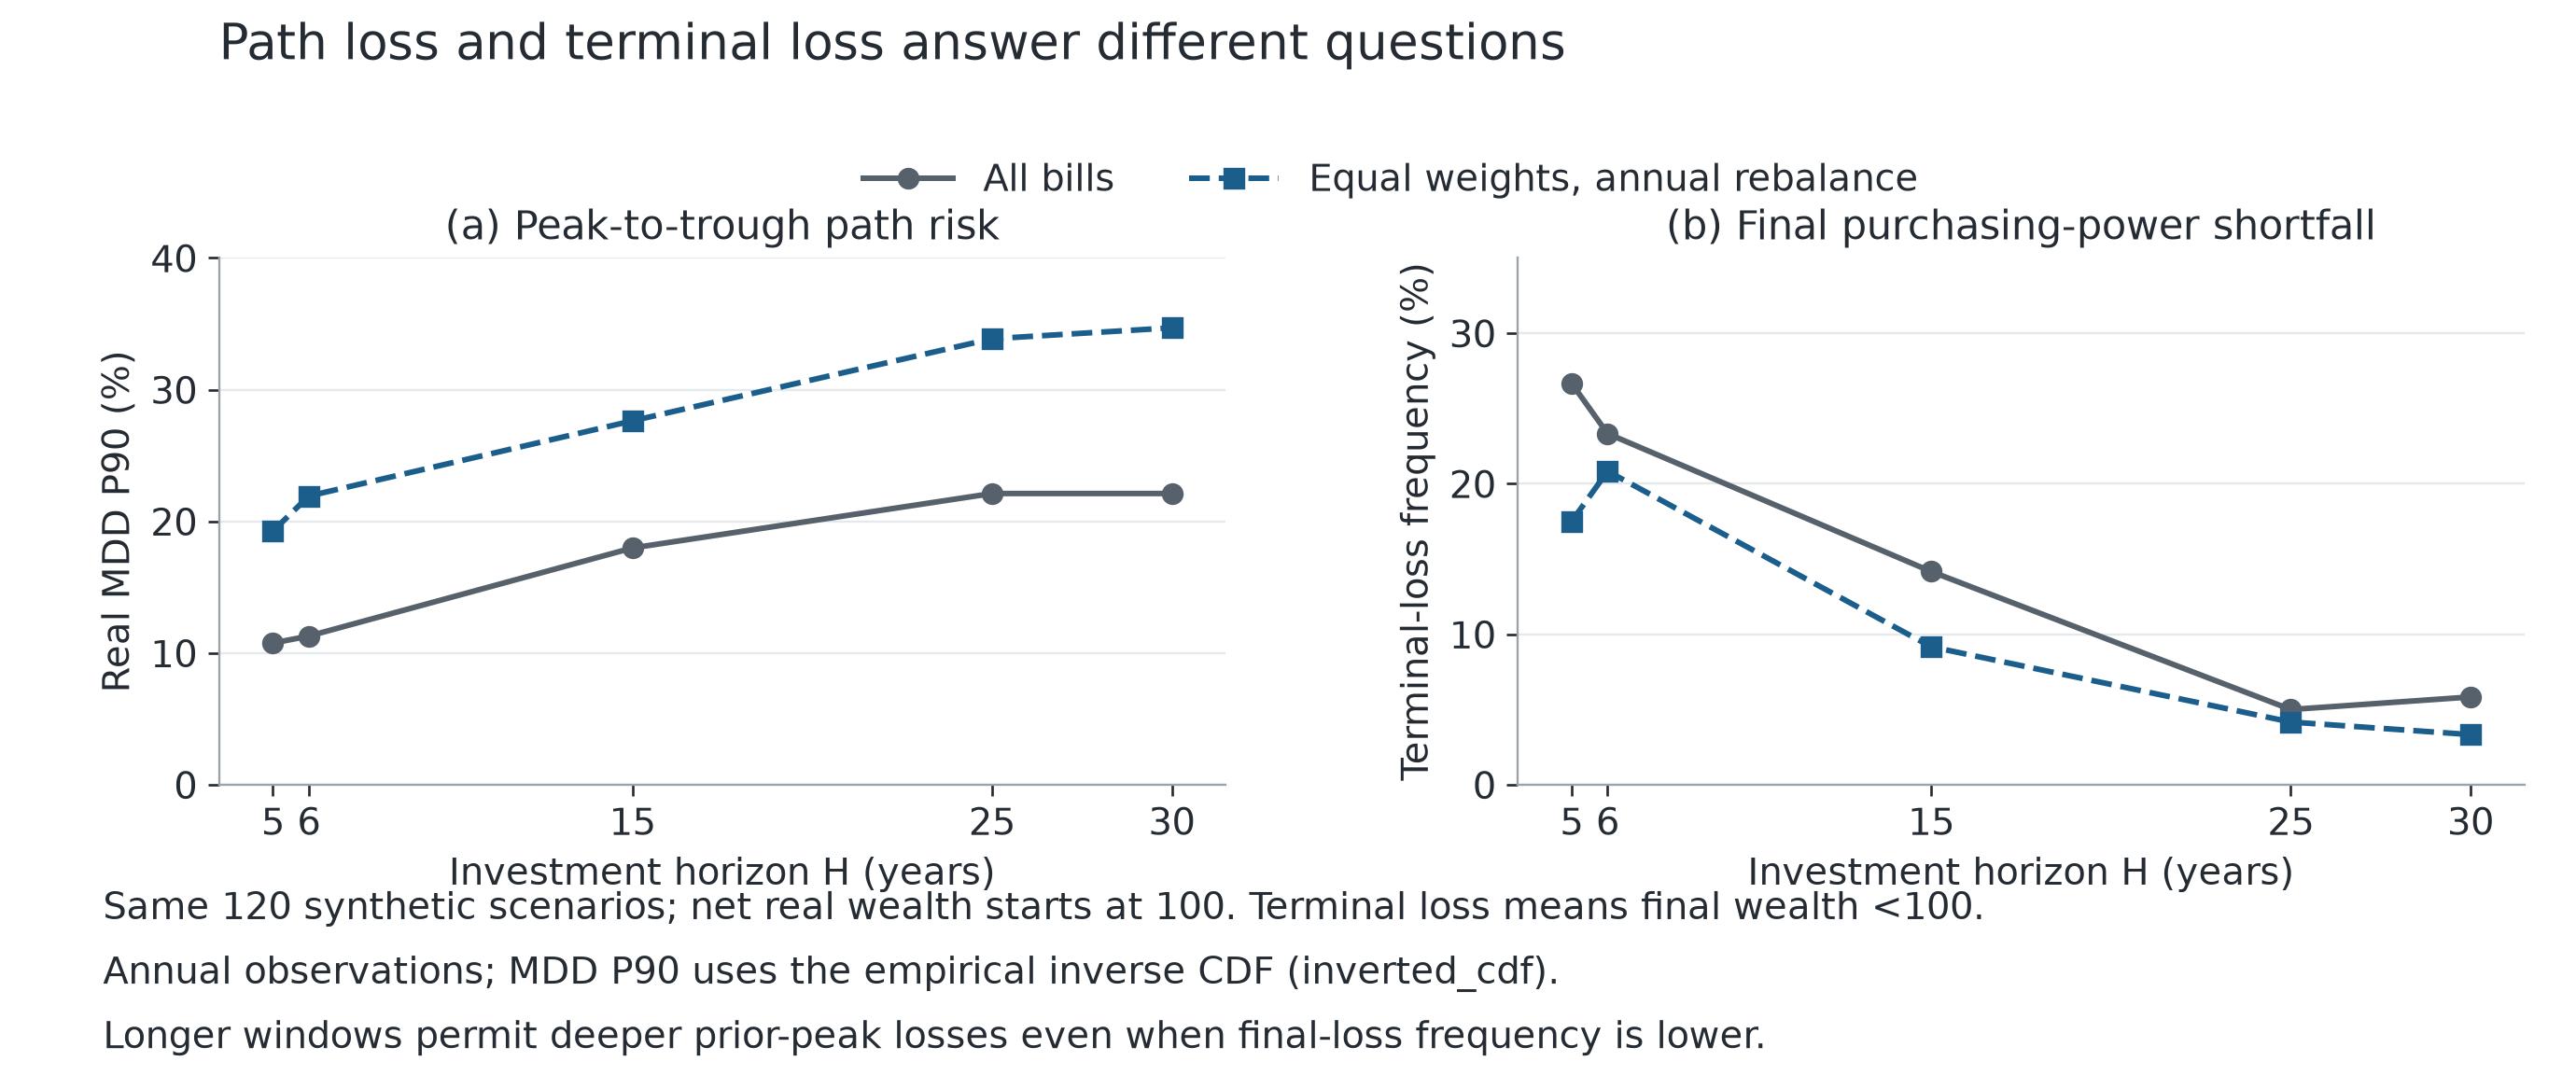

In [3]:
rows = []
for asset, item in structure['market']['assets'].items():
    rows.append({'asset': asset,
                 'mean annual real return': item['mean_annual_real_return_scenario_equal'],
                 'nominal negative annual share': item['nominal_annual_loss_share_scenario_equal'],
                 'real negative annual share': item['real_annual_loss_share_scenario_equal']})
show(pd.DataFrame(rows), {k: '{:.2%}' for k in rows[0] if k != 'asset'})
for name in ['01_annual_frequency_and_magnitude.png', '02_horizon_path_and_terminal_risk.png']:
    figure(ROOT / 'research/figures/development_structure' / name,
           '开发集年度损失频率、收益幅度及期限下的回撤与终值风险；详见相邻解释和来源表。')

### 3.1 哪些损失连理想的年度配置也无法避免

对每条路径，设 $m_t=\max_a\{(1+r_{a,t})/(1+\iota_t)\}$ 为当年三个资产中最好的实际财富因子。在当前年度决策模型中，若只在年初交易、年内持仓不变、无做空杠杆或外部注资，扣费后权重 $v_t$ 在单纯形内，非负费用比例为 $\rho_t$，则
$$R_t/R_{t-1}=(1-\rho_t)\sum_a v_{a,t}(1+r_{a,t})/(1+\iota_t)\le m_t.$$
对任意两个年度末点 $s<t$，乘积也满足 $R_t/R_s\le\prod_{k=s+1}^t m_k$，所以任何上述策略的年度MDD至少为
$$D_H^{\rm lb}=\max\!\left(0,\max_{0\le s<t\le H}\left[1-\prod_{k=s+1}^t m_k\right]\right).$$

这等于“零费用、每年事先知道哪种资产最好”的理想路径MDD，只是扩大策略范围后的乐观下界，不能作为可实施投资方案。证明依赖**每个区间的收益比**，不是通常并不成立的“某条财富曲线处处更高，因此回撤更小”。

若这个下界已大于某客户L，该路径在上述年度模型下必然超限；若这样的路径比例超过α，才能断言这批经验路径上整个年度策略类都不可能通过。下界未超限只表示没有排除可行性，不能证明存在一个因果策略满足预算。允许年内换仓、加入第四种可投资现金、外部现金流或杠杆时，必须重新检查前提。当前所有计算仍只使用各客户H内的开发路径。

In [4]:
bound_root = ROOT / 'results/model_review/policy_independent_drawdown_bound_v1'
bound_counts = pd.read_csv(bound_root / 'client_counts.csv')
show(bound_counts[['client', 'horizon', 'n_original_paths', 'forced_breach_count',
                   'grid_min_breach_count', 'allowed_breach_count',
                   'empirical_budget_impossible_for_entire_declared_class']], {})
bound_audit = readj(bound_root / 'independent_audit.json')
print('下界独立逐区间核查通过；不重新拟合或选策略。')

client,horizon,n_original_paths,forced_breach_count,grid_min_breach_count,allowed_breach_count,empirical_budget_impossible_for_entire_declared_class
A,5,120,3,16,12,False
B,15,120,0,1,12,False
C,30,120,0,0,12,False
D,25,120,6,33,12,False
E,6,120,0,0,12,False


下界独立逐区间核查通过；不重新拟合或选策略。


全120开发路径中，A/D分别有3/6条在理想下界下仍超限，均未超过10%预算对应的12条。原232固定年度目标族的最少超限数却分别为16/33，所以目前能证明的是该固定族内找不到通过经验筛选的目标，**不能升级为整个动态年度策略类都无解**。下界也没有找出可实施的安全策略；A、D在当前已研究菜单中继续转介，有明确的模型范围理由。

## 4. 经验菜单：训练结果与折外表现

参考情形是10%经验超限预算、无额外票据下限。下表是候选权重，资产顺序为股票、政府债、票据。B、C、E的各自可行网格最优解恰能装入三个位置，因此训练增长损失为零；这不证明市场中存在唯一或普适的三种风险偏好，也不证明精确权重已被识别。

In [5]:
show(pd.DataFrame([{'product': p['name'], 'equity': p['weights'][0],
                   'bond': p['weights'][1], 'bill': p['weights'][2],
                   'identified by given profiles': p['identified_by_profiles']}
                  for p in primary['menu']]),
     {x: '{:.0%}' for x in ['equity', 'bond', 'bill']})
reference = grid[grid.client.eq('B') & grid.candidate_index.isin([p['candidate_index'] for p in primary['menu']])].copy()
reference['product'] = reference.candidate_index.map({p['candidate_index']: p['name'] for p in primary['menu']})
show(reference[['product', 'horizon', 'median_volatility', 'median_mdd', 'p90_mdd', 'cvar90_mdd']],
     {x: '{:.2%}' for x in ['median_volatility', 'median_mdd', 'p90_mdd', 'cvar90_mdd']})
print('分配：', primary['assignments'])
chosen = pd.DataFrame([d for d in primary['client_product_details'] if d['chosen']])
chosen['training count'] = chosen['breach_count'].astype(str) + '/120'
chosen['exp(G)-1'] = np.expm1(chosen['mean_log_growth'])
show(chosen[['client', 'horizon', 'loss_tolerance', 'portfolio', 'training count',
             'exp(G)-1', 'expected_excess', 'cvar90_mdd']],
     {x: '{:.2%}' for x in ['loss_tolerance', 'exp(G)-1', 'expected_excess', 'cvar90_mdd']})
poof = oof[oof['case'].eq('alpha_10__risk_only')].copy()
show(poof[['client', 'assigned_paths', 'review_paths', 'breach_count', 'breach_probability',
           'mean_log_growth', 'median_cagr', 'p10_cagr', 'p90_mdd', 'cvar90_mdd']],
     {x: '{:.2%}' for x in ['breach_probability', 'mean_log_growth', 'median_cagr',
                            'p10_cagr', 'p90_mdd', 'cvar90_mdd']})

product,equity,bond,bill,identified by given profiles
Conservative,30%,20%,50%,True
Balanced,50%,0%,50%,True
Growth,75%,0%,25%,True


product,horizon,median_volatility,median_mdd,p90_mdd,cvar90_mdd
Conservative,15,6.95%,14.32%,24.94%,29.90%
Balanced,15,9.89%,18.56%,35.23%,41.70%
Growth,15,13.97%,26.21%,46.41%,56.80%


分配： {'A': 'Review', 'B': 'Conservative', 'C': 'Balanced', 'D': 'Review', 'E': 'Growth'}


client,horizon,loss_tolerance,portfolio,training count,exp(G)-1,expected_excess,cvar90_mdd
B,15,25.00%,Conservative,12/120,3.16%,0.49%,29.90%
C,30,40.00%,Balanced,12/120,4.28%,0.69%,46.91%
E,6,35.00%,Growth,12/120,4.88%,0.81%,43.14%


client,assigned_paths,review_paths,breach_count,breach_probability,mean_log_growth,median_cagr,p10_cagr,p90_mdd,cvar90_mdd
A,0,120,—,—,—,—,—,—,—
B,120,0,12,10.00%,3.09%,3.33%,0.28%,24.78%,29.83%
C,120,0,13,10.83%,4.09%,4.12%,1.50%,40.17%,46.11%
D,0,120,—,—,—,—,—,—,—
E,120,0,11,9.17%,4.64%,5.42%,-3.81%,33.66%,42.74%


B/C/E全开发训练都是12/120，恰好用满经验额度。B和E的折外计数为12/120、11/120；C为13/120，超过参考预算一个情景，是内部校准警报。单个情景占0.833个百分点，贴边意味着不能把微小数字差异当作强结论；13与12也不构成对真实超限概率的显著性判决。

A和D的全开发、五折分配都是Review。原因需要区分“菜单里没有”与“整个当前候选族不可行”。下表检查后者；这仍不证明所有可能的动态投资政策都无法服务他们。

client,horizon,loss_tolerance,minimum breach count,breach_probability,w_equity,w_bond,w_bill
A,5,10.00%,16,13.33%,0.00%,0.00%,100.00%
B,15,25.00%,1,0.83%,5.00%,0.00%,95.00%
C,30,40.00%,0,0.00%,0.00%,0.00%,100.00%
D,25,15.00%,33,27.50%,5.00%,0.00%,95.00%
E,6,35.00%,0,0.00%,0.00%,0.00%,100.00%



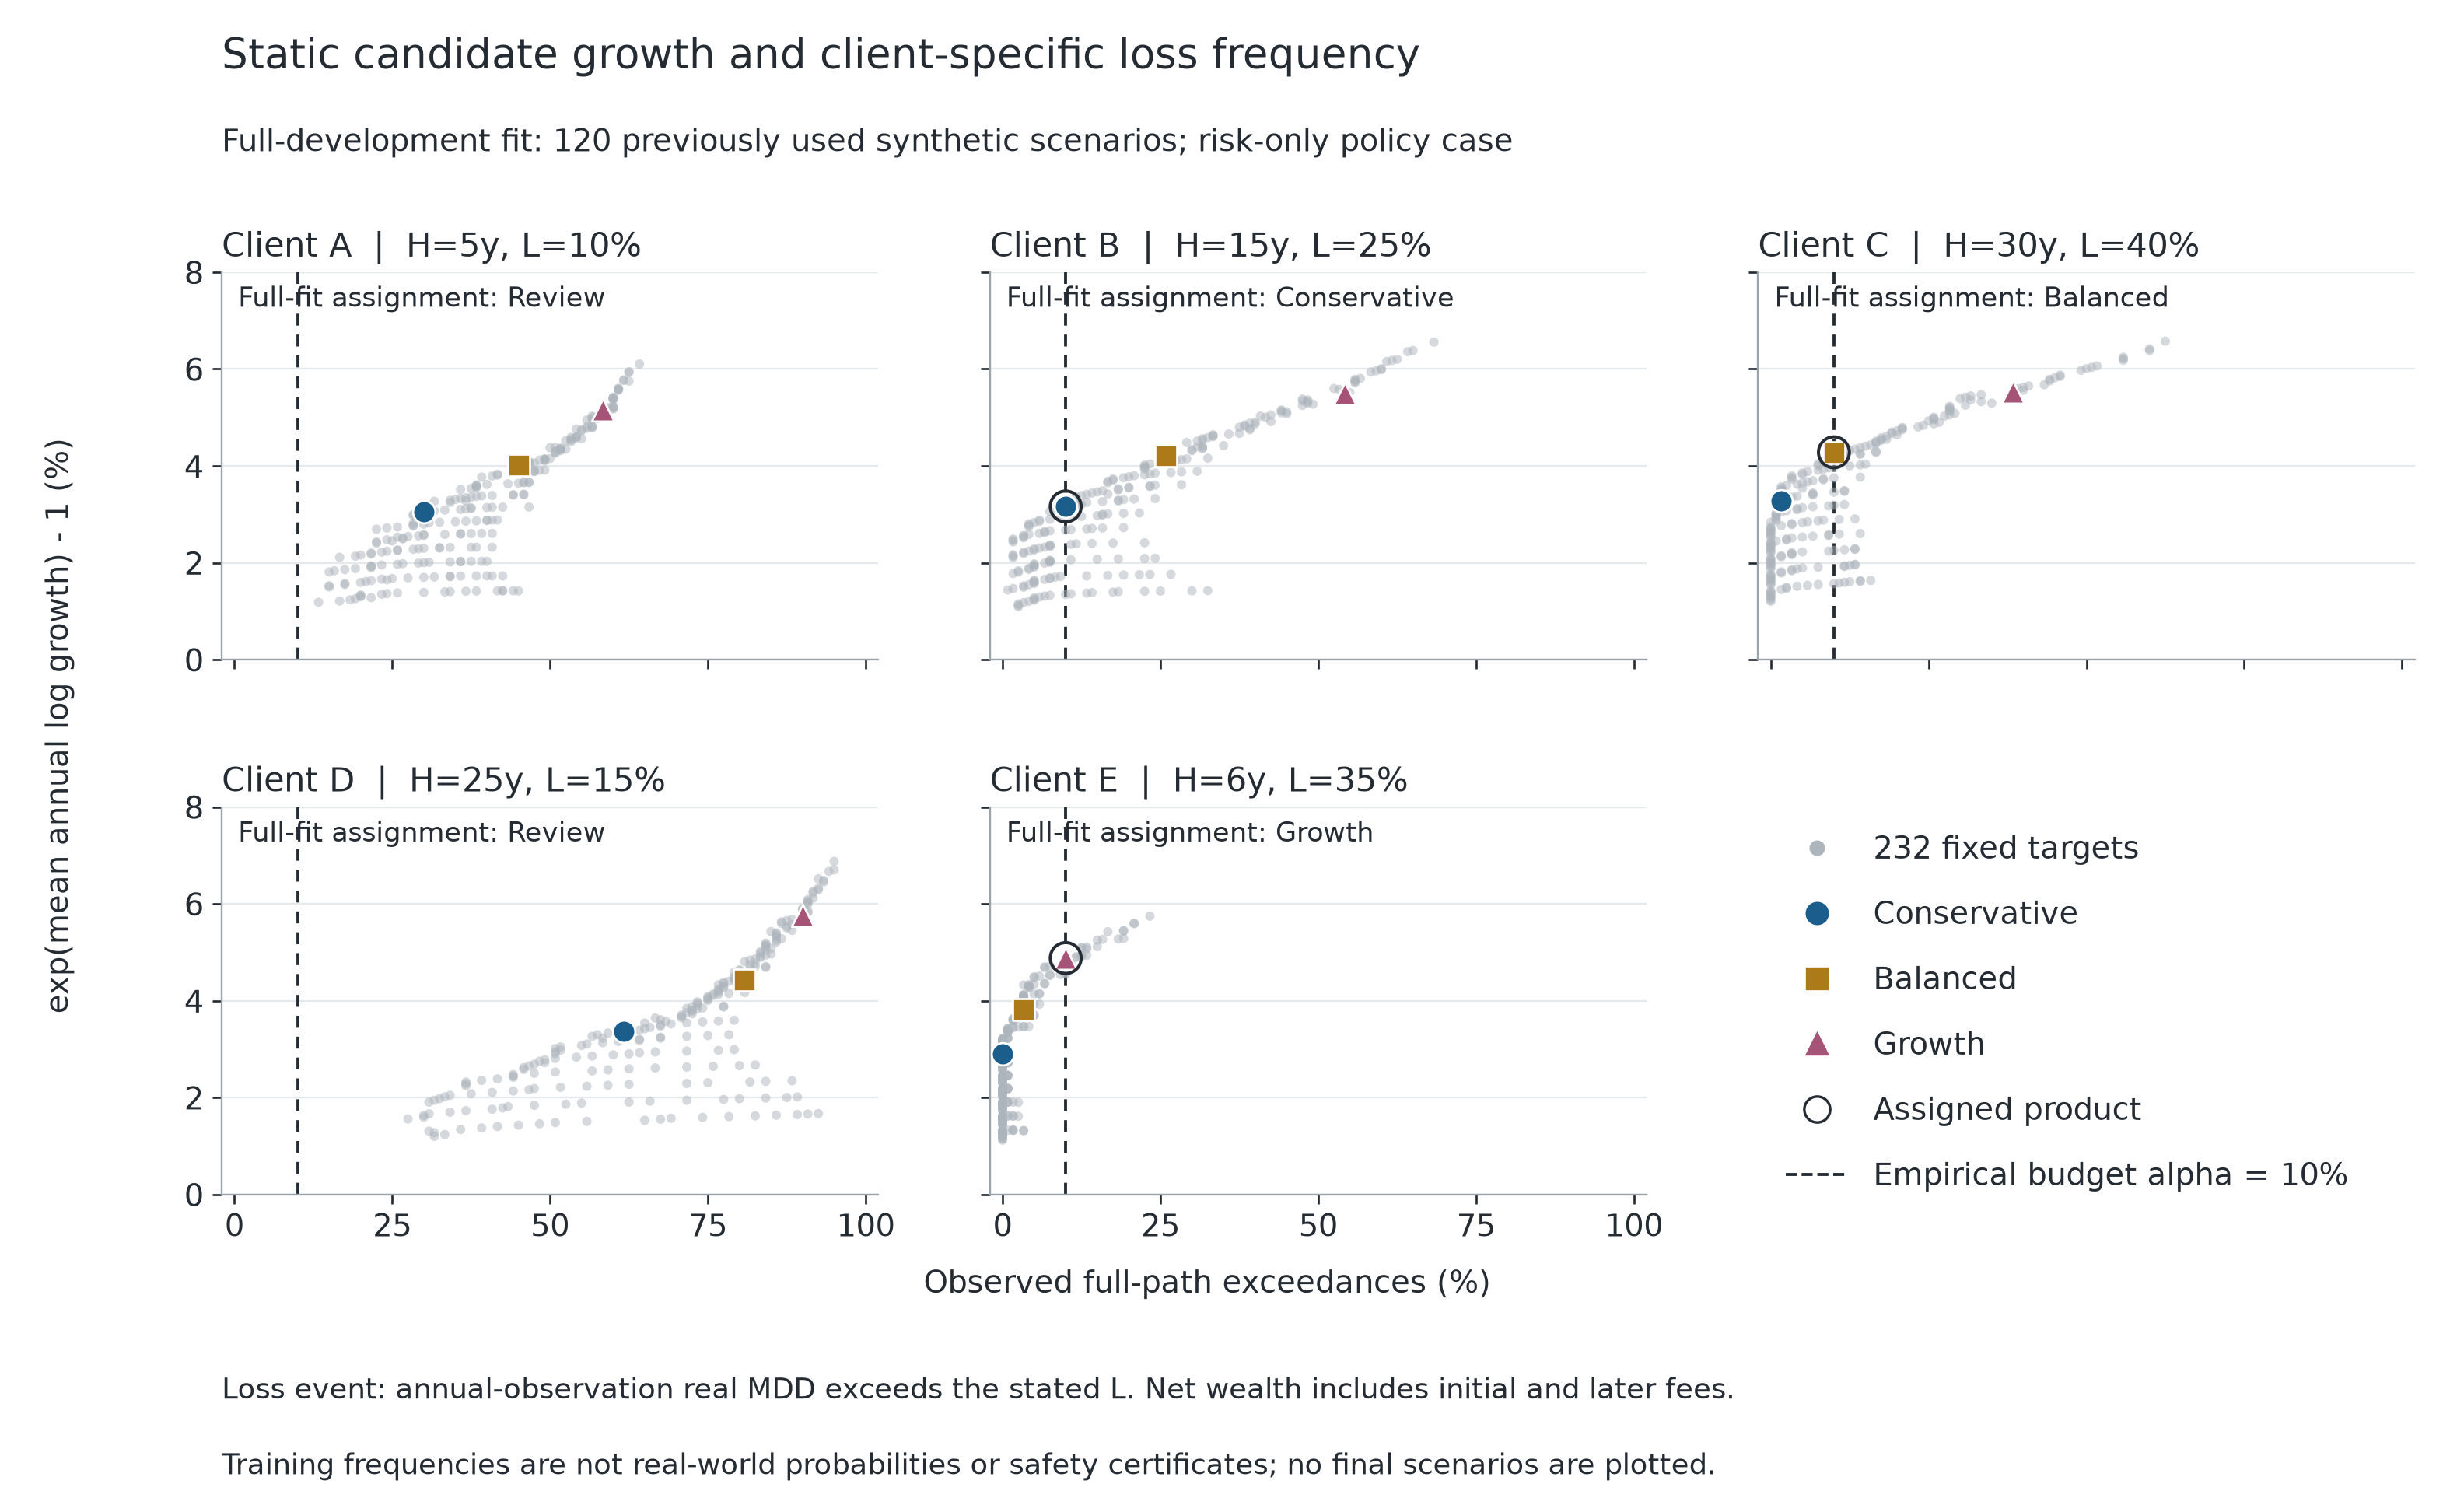

In [6]:
minimum = grid.sort_values(['client', 'breach_probability', 'candidate_index']).groupby('client', sort=True).head(1).copy()
minimum['minimum breach count'] = np.rint(minimum['breach_probability'] * 120).astype(int)
show(minimum[['client', 'horizon', 'loss_tolerance', 'minimum breach count',
              'breach_probability', 'w_equity', 'w_bond', 'w_bill']],
     {x: '{:.2%}' for x in ['loss_tolerance', 'breach_probability', 'w_equity', 'w_bond', 'w_bill']})
figure(ROOT / 'research/figures/risk_menu/01_client_growth_risk.png',
       '五个客户期限下，232候选的训练超限频率与年化几何增长；参考10%风险预算及候选菜单。')

## 5. 重抽样：功能分配稳定不等于精确参数稳定

每次从120条完整开发路径有放回抽120条，重新拟合整个菜单和分配，共1,000次。B/C/E都能获得自动分配，D均Review；A有21.9%的重抽样获得自动分配。**这是经验分布重抽样下的算法翻转频率，既不是A适合投资的概率，也不是风险安全置信度。** A的全开发最低超限率为16/120，bootstrap改变了路径质量，偶尔让经验可行性成立。

权重按与全开发菜单的最小总L1距离对齐后，每个坐标的分位数范围仍较宽。这支持继续研究菜单的功能，而不支持把30/20/50、50/0/50、75/0/25宣布为已确定的最终参数。坐标的分位数组合不必和为1，不能作为实际投资组合；这些范围也不是未来风险区间。

client,automatic frequency
A,21.9%
B,100.0%
C,100.0%
D,0.0%
E,100.0%


覆盖客户数的重抽样次数： {'3': 781, '4': 219}
三产品同基数对齐次数： 1000



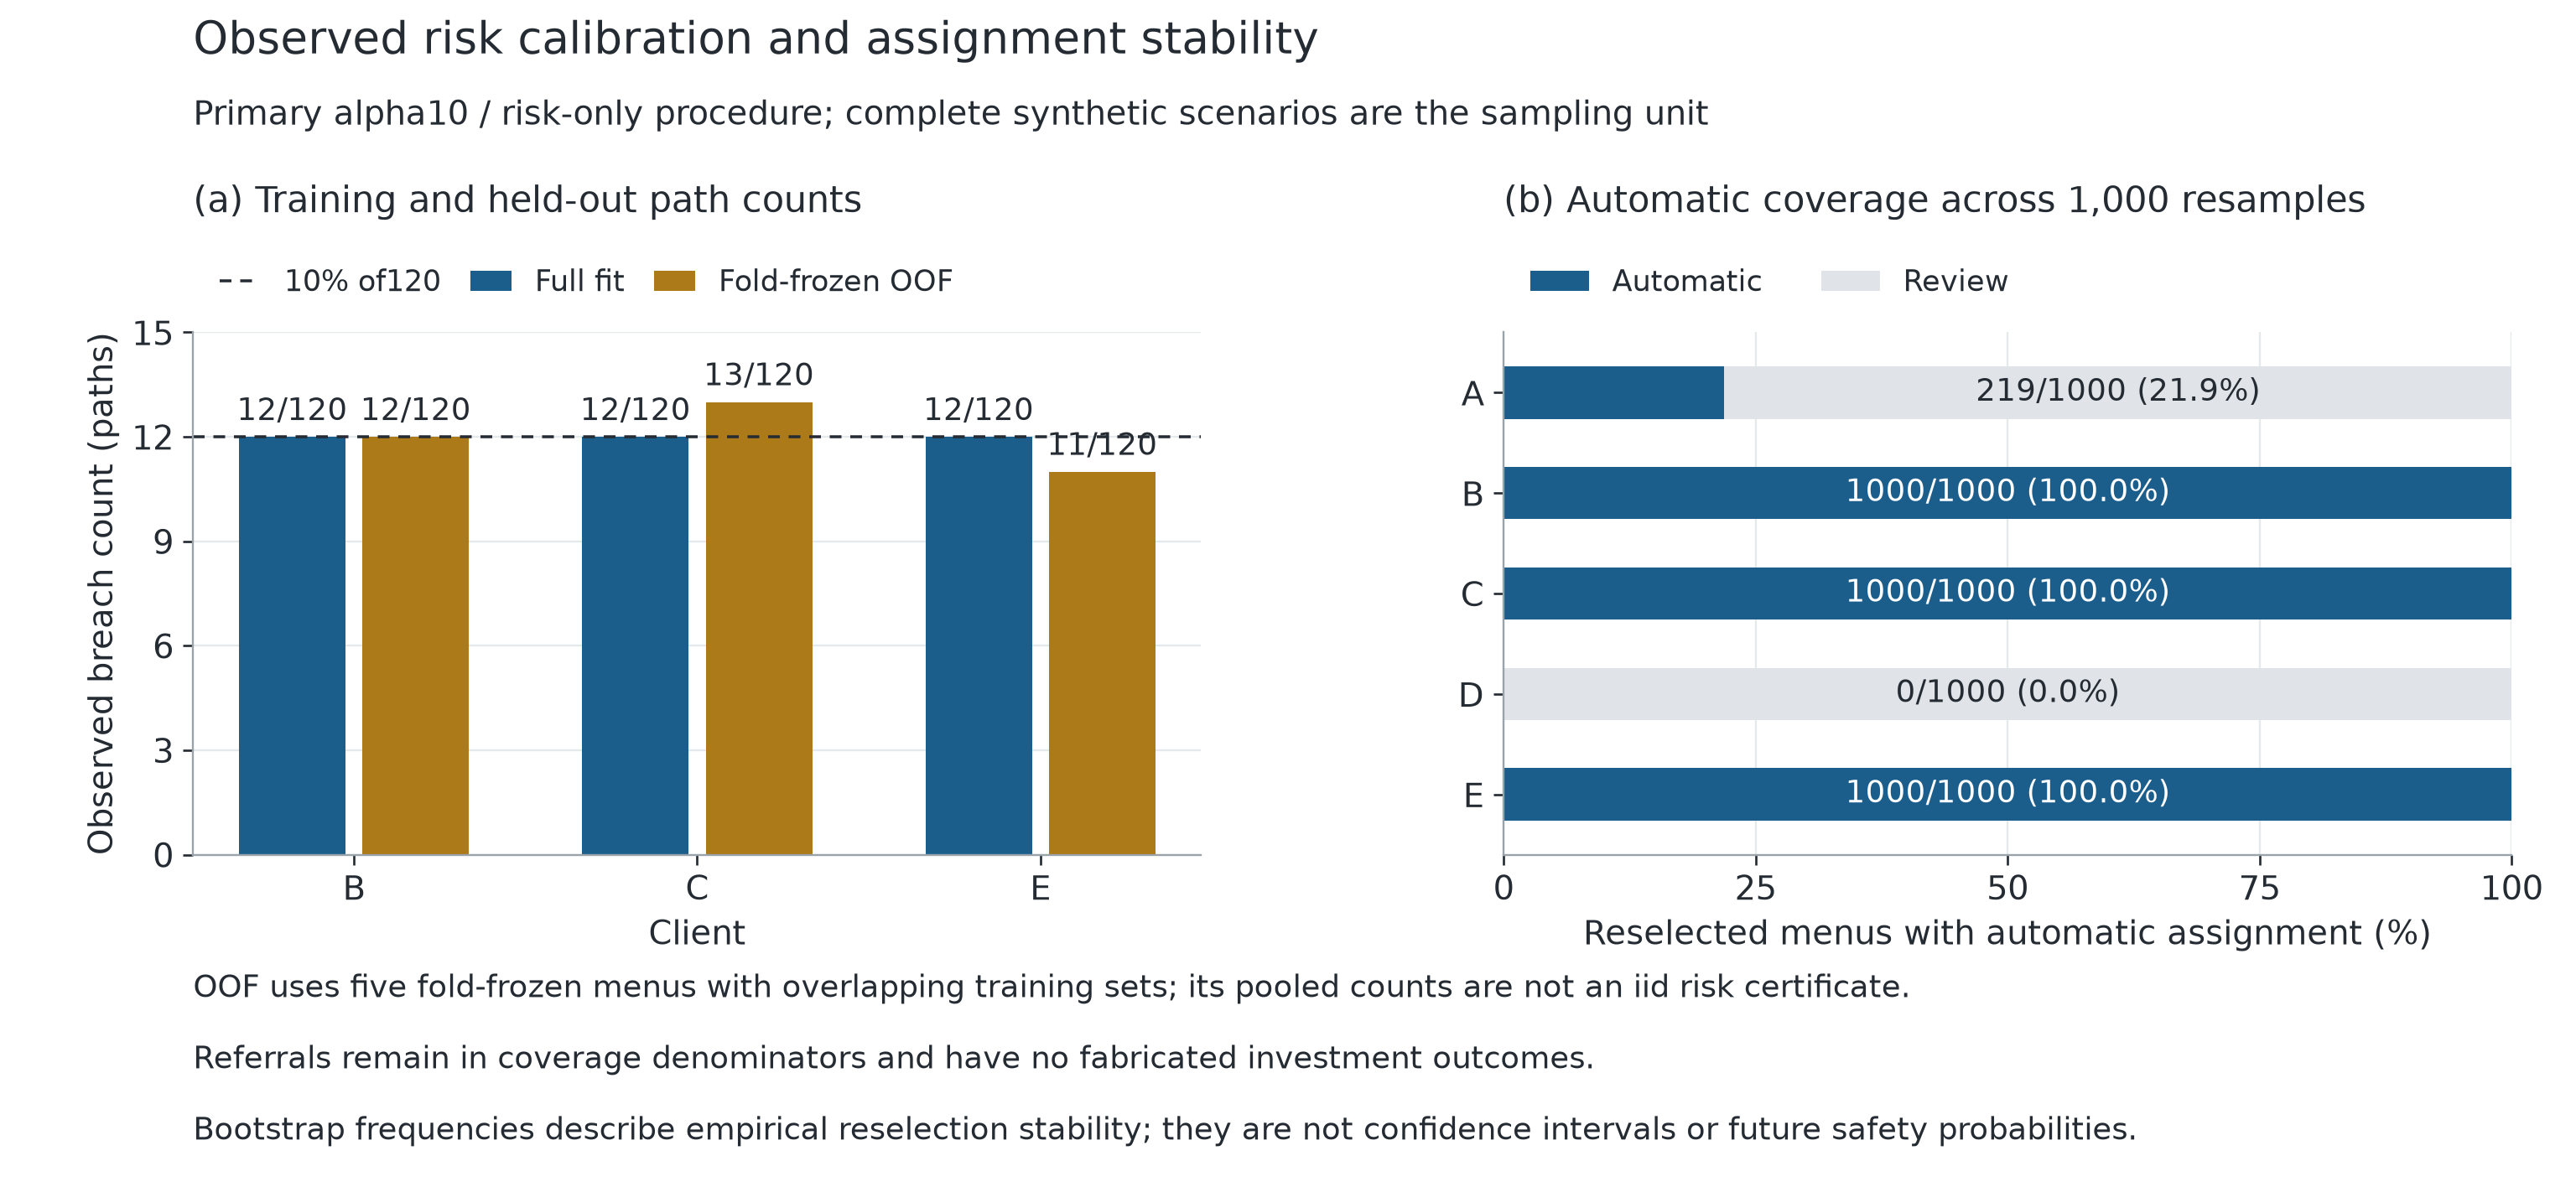


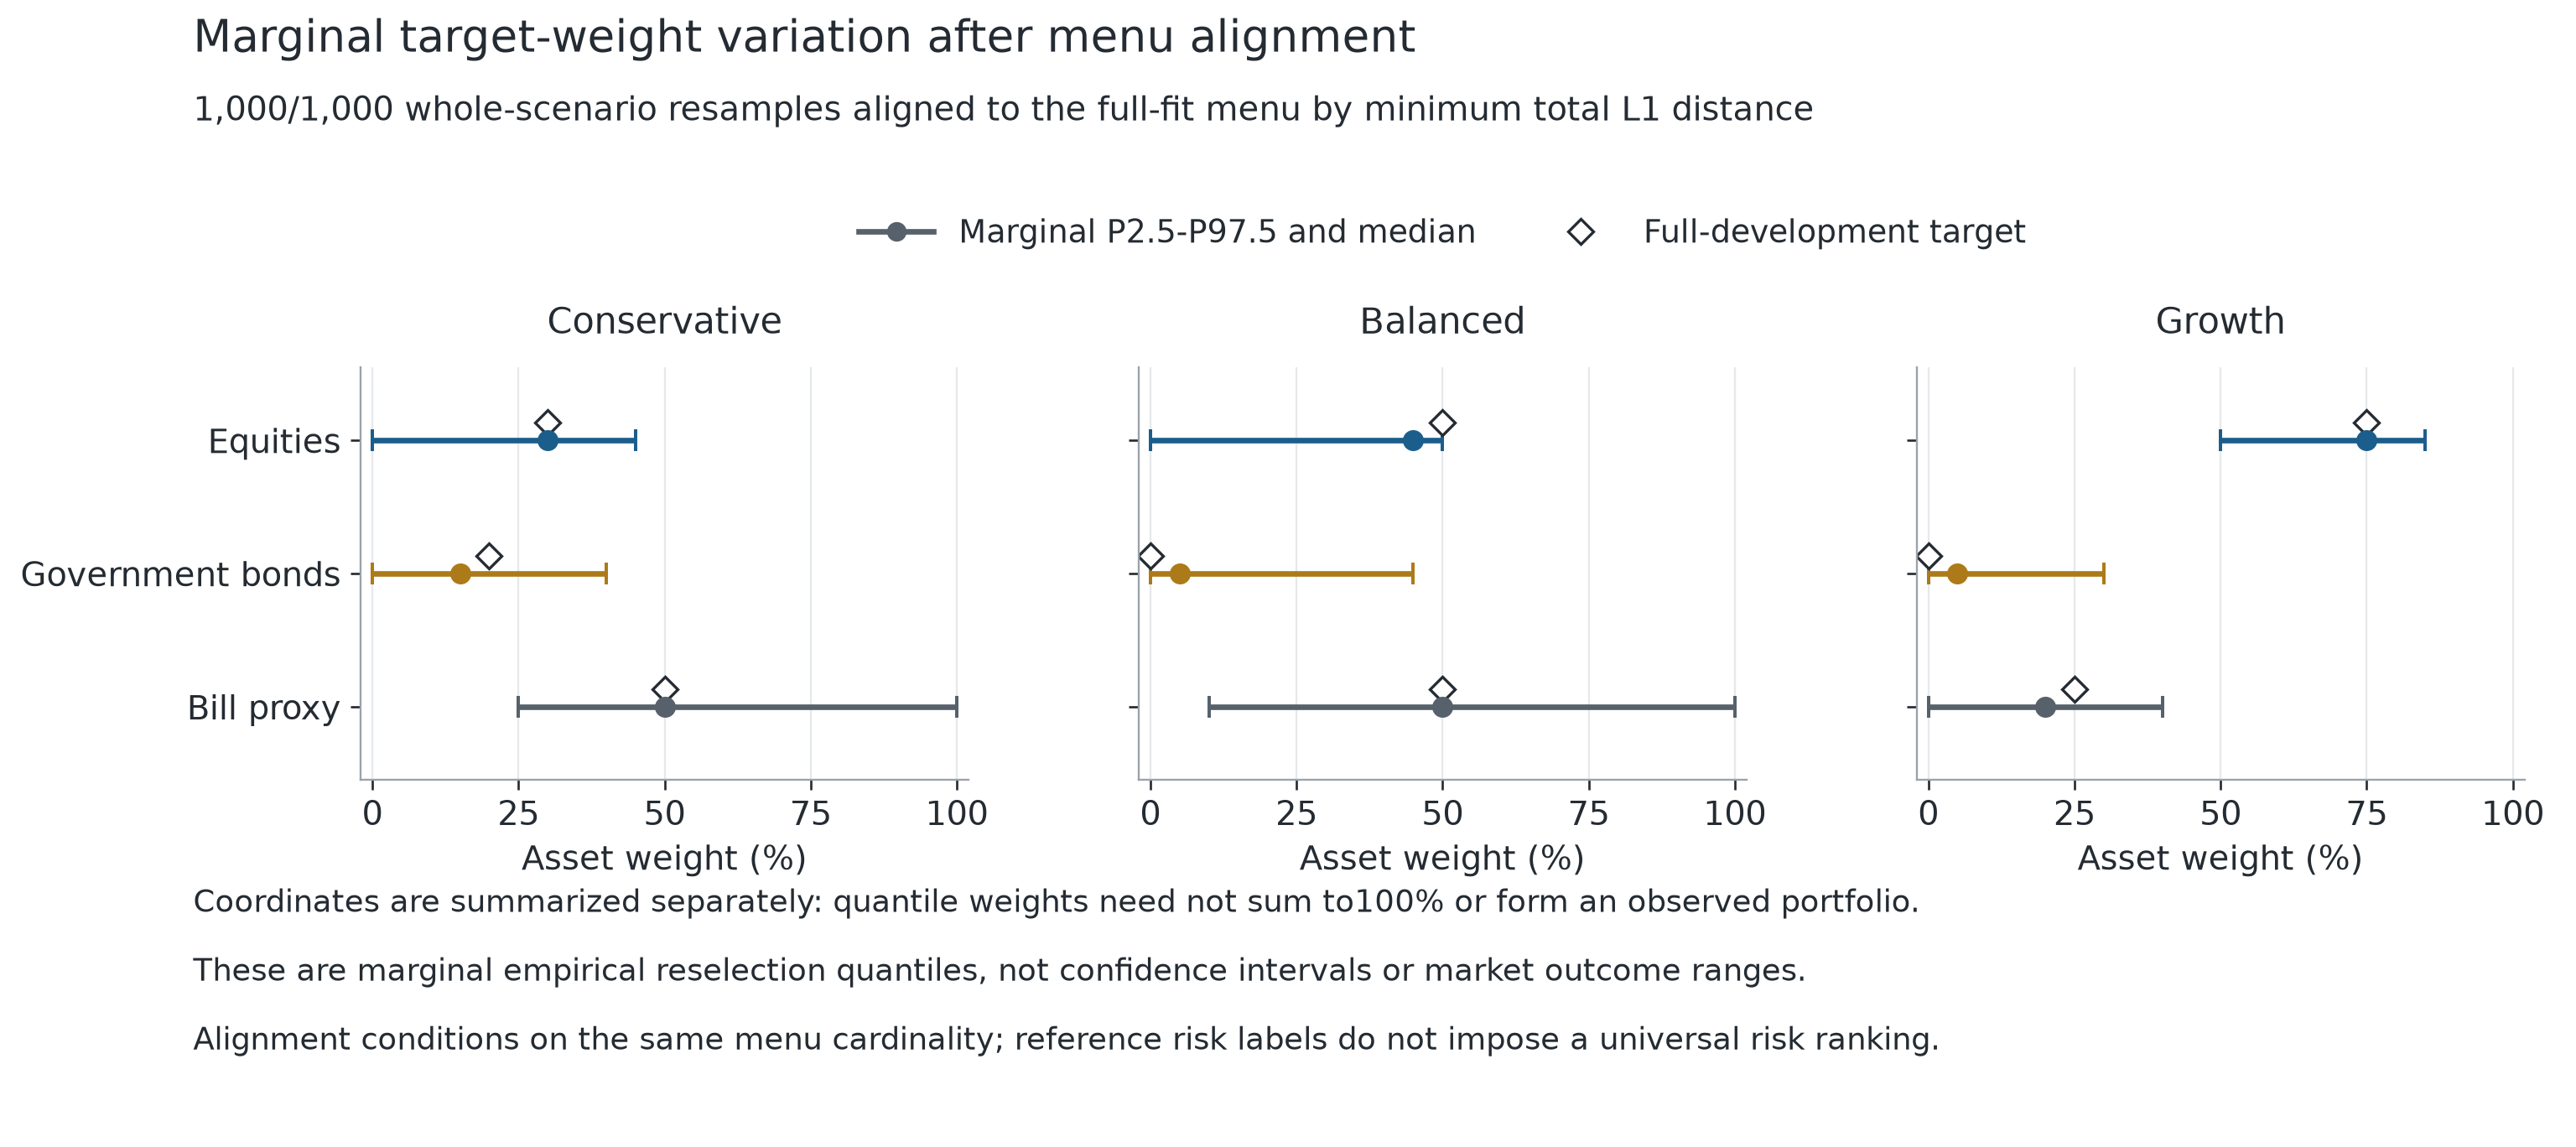

In [7]:
show(pd.DataFrame([{'client': k, 'automatic frequency': v}
                   for k, v in boot['automatic_frequency'].items()]),
     {'automatic frequency': '{:.1%}'})
print('覆盖客户数的重抽样次数：', boot['coverage_counts'])
print('三产品同基数对齐次数：', boot['aligned_replicates'])
for name in ['02_risk_and_assignment_stability.png', '03_aligned_weight_variation.png']:
    figure(ROOT / 'research/figures/risk_menu' / name,
           '经验训练与折外超限、完整重抽样的自动服务频率和菜单对齐后边际资产权重变动；不是置信区间。')

重抽样自动服务次数还不足以判断可靠性，因此另外登记了**事后OOB诊断**：对每次bootstrap，取未被该次抽中的原路径，执行该次冻结的客户—目标分配。下表按自动分配的replicate等权平均，每次OOB样本32–55条，中位44。训练实际只含约76条不同原路径并以重复次数加权，这不同于用完整120条不同路径训练。

A的219次自动分配，OOB超限比例均超过10%；平均由inbag的9.42%升到OOB的20.60%。这对“可行性偶尔翻转即可自动配置”的解释构成反证。20.60%只条件于这些自动分配反事实，不能称原规则对A的风险；原规则本来Review。不同replicate重复使用路径，不能把OOB记录合并作独立试验或计算简单二项安全证书。

In [8]:
oob_summary = readj(R / 'bootstrap/alpha_10__risk_only/oob/summary.json')
rows = []
for client, item in oob_summary['by_client'].items():
    if not item['automatic_replicates']:
        rows.append({'client': client, 'auto replicates': 0, 'inbag mean breach': None,
                     'OOB mean breach': None})
        continue
    rows.append({'client': client, 'auto replicates': item['automatic_replicates'],
                 'inbag mean breach': item['sample_metrics']['inbag']['breach_probability']['mean'],
                 'OOB mean breach': item['sample_metrics']['oob']['breach_probability']['mean']})
show(pd.DataFrame(rows), {x: '{:.2%}' for x in ['inbag mean breach', 'OOB mean breach']})
recurrence = oob_summary['recurrence_and_role_movement']
print('原三目标菜单完全复现：', recurrence['exact_ordered_menu_count'], '/', recurrence['replicates'])
show(pd.DataFrame([{'client': client, 'original target recurrence': item['original_target_frequency_all_replicates']}
                   for client, item in recurrence['by_client'].items()]),
     {'original target recurrence': '{:.1%}'})
print('角色名称也会随目录组成移动；不应将名称移动解释为客户偏好发生改变。')

client,auto replicates,inbag mean breach,OOB mean breach
A,219,9.42%,20.60%
B,"1,000",9.43%,12.27%
C,"1,000",8.26%,10.28%
D,0,—,—
E,"1,000",8.96%,11.12%


原三目标菜单完全复现： 5 / 1000


client,original target recurrence
A,—
B,12.2%
C,24.7%
D,—
E,24.4%


角色名称也会随目录组成移动；不应将名称移动解释为客户偏好发生改变。


## 6. 风险预算与票据下限：政策会改变结论

这些比较检验假设的影响，不据此选择收益最高的α。5%/10%都不能让A在全开发候选族中自动分配，20%可以；D在三种预算下均Review。加入票据下限可能改变客户得到的产品，也可能让第三个产品只剩产品目录的补充角色。

In [9]:
rows = []
for case, fit in full.items():
    rows.append({'case': case, 'covered': fit['selection']['objective'][0],
                 'max annual log-growth regret': fit['selection']['objective'][1],
                 'identified product count': len(fit['selection']['identified_indices']),
                 **fit['assignments']})
show(pd.DataFrame(rows), {'max annual log-growth regret': '{:.3%}'})

case,covered,max annual log-growth regret,identified product count,A,B,C,D,E
alpha_05__risk_only,3,0.000%,3,Review,Conservative,Balanced,Review,Growth
alpha_05__reference_reserve,3,0.000%,3,Review,Conservative,Balanced,Review,Growth
alpha_05__larger_reserve,3,0.000%,3,Review,Conservative,Balanced,Review,Growth
alpha_10__risk_only,3,0.000%,3,Review,Conservative,Balanced,Review,Growth
alpha_10__reference_reserve,3,0.000%,3,Review,Conservative,Balanced,Review,Growth
alpha_10__larger_reserve,3,0.000%,2,Review,Conservative,Balanced,Review,Balanced
alpha_20__risk_only,4,0.807%,3,Conservative,Balanced,Balanced,Review,Growth
alpha_20__reference_reserve,4,0.565%,3,Conservative,Balanced,Growth,Review,Growth
alpha_20__larger_reserve,4,0.425%,3,Conservative,Balanced,Growth,Review,Growth


## 7. 对照、交易费和网格分辨率

另一个事先规定的H=15前沿端点/风险中点目录，并非根据客户样本优化，也能覆盖B/C/E，且折外超限较少，但增长较低。不能只看风险降低就称它优于主菜单，也不能只看主菜单增长较高就忽略风险代价。

费用敏感性必须分开看：冻结原分配，观察同一客户—产品在费用变化后的结果；以及保持三目标不变，按新费用重新检查适配。第二种可能发生转介或换产品，不能混作第一种的绩效。

局部2.5个百分点网格是原三个目标各L1距离≤0.10的43点并集，**不是对整个2.5个百分点网格进行新的全局选型**。本轮局部复核保持同样菜单和分配；它只支持这一邻域内的数值分辨率稳定性。

In [10]:
ref_oof = pd.read_csv(R / 'analysis/comparator/oof_summary.csv')
ref_oof = ref_oof[ref_oof['case'].eq('alpha_10__risk_only')]
compare = pd.concat([poof.assign(method='client-derived empirical menu'),
                     ref_oof.assign(method='fixed reference-frontier menu')], ignore_index=True)
show(compare[compare.client.isin(['B', 'C', 'E'])][
    ['method', 'client', 'assigned_paths', 'breach_count', 'breach_probability', 'mean_log_growth', 'cvar90_mdd']],
    {x: '{:.2%}' for x in ['breach_probability', 'mean_log_growth', 'cvar90_mdd']})
fees = pd.read_csv(R / 'analysis/costs/frozen_assignment_summary.csv')
print('以下费用表：冻结原客户分配，在完整120开发情景上计算，包含拟合样本。')
show(fees[fees.client.isin(['B', 'C', 'E'])][
    ['cost_rate', 'client', 'assigned_paths', 'breach_count', 'breach_probability', 'mean_log_growth']],
    {x: '{:.2%}' for x in ['cost_rate', 'breach_probability', 'mean_log_growth']})
rescreened = readj(R / 'analysis/costs/fixed_menu_rescreened.json')
for cost, fit in rescreened.items():
    print('固定菜单按新费用重筛', cost, fit['assignments'])
resolution = readj(R / 'analysis/resolution/diagnostics.json')
print('局部细网格点数：', resolution['local_candidate_count'])
print('原菜单与细网格局部菜单分配：', resolution['primary_original_assignments'],
      resolution['fine_local_fit']['assignments'])

method,client,assigned_paths,breach_count,breach_probability,mean_log_growth,cvar90_mdd
client-derived empirical menu,B,120,12,10.00%,3.09%,29.83%
client-derived empirical menu,C,120,13,10.83%,4.09%,46.11%
client-derived empirical menu,E,120,11,9.17%,4.64%,42.74%
fixed reference-frontier menu,B,120,1,0.83%,1.63%,21.87%
fixed reference-frontier menu,C,120,0,0.00%,1.73%,26.43%
fixed reference-frontier menu,E,120,5,4.17%,3.93%,35.62%


以下费用表：冻结原客户分配，在完整120开发情景上计算，包含拟合样本。


cost_rate,client,assigned_paths,breach_count,breach_probability,mean_log_growth
0.00%,B,120,12,10.00%,3.13%
0.00%,C,120,12,10.00%,4.20%
0.00%,E,120,12,10.00%,4.80%
0.25%,B,120,12,10.00%,3.11%
0.25%,C,120,12,10.00%,4.19%
0.25%,E,120,12,10.00%,4.77%
0.50%,B,120,13,10.83%,3.10%
0.50%,C,120,13,10.83%,4.18%
0.50%,E,120,12,10.00%,4.73%


固定菜单按新费用重筛 0.0 {'A': 'Review', 'B': 'Conservative', 'C': 'Balanced', 'D': 'Review', 'E': 'Growth'}
固定菜单按新费用重筛 0.0025 {'A': 'Review', 'B': 'Conservative', 'C': 'Balanced', 'D': 'Review', 'E': 'Growth'}
固定菜单按新费用重筛 0.005 {'A': 'Review', 'B': 'Review', 'C': 'Conservative', 'D': 'Review', 'E': 'Growth'}
局部细网格点数： 43
原菜单与细网格局部菜单分配： {'A': 'Review', 'B': 'Conservative', 'C': 'Balanced', 'D': 'Review', 'E': 'Growth'} {'A': 'Review', 'B': 'Conservative', 'C': 'Balanced', 'D': 'Review', 'E': 'Growth'}


## 8. 选择之后，还能对风险说多少：有限候选族的保守对照

主经验频率没有纠正从许多候选中挑选造成的乐观偏差。第二条研究线路在**额外假设：各情景独立且同分布，来自同一合成路径生成机制**下，对232个固定策略×5个给定客户事件，共1160个事件同时建立单侧上界。题目给出的“独立”本身不自动保证“同分布”。

若样本超限数为 $k<n$，则
$$U(k,n)=\operatorname{Beta}^{-1}\left(1-\frac{0.05}{1160};k+1,n-k\right),$$
$k=n$ 时取1。单个Clopper–Pearson上界与并集界使全部1160个真实合成分布超限概率同时被覆盖的概率至少95%，因而可在这个固定族内再选菜单。跨候选相关性不破坏并集界。它不覆盖新增动态策略、细网格或其它费用，也不为增长、严重度或真实市场提供保证。

120条路径零次超限的同时上界约8.04%；一次约10.06%。因此10%政策下只能接受训练零超限的候选；5%政策连零次也证据不足，至少需要196条同分布独立路径才可能在同样族大小/置信标准下支持零超限候选。**证据不足不等于已证明危险。** 五折分别重新应用该算法，但不声称五个训练集的证书又同时具有95%联合覆盖。

In [11]:
secondary = readj(S / 'full_development_menus.json')
rows = []
for case, fit in secondary.items():
    rows.append({'case': case, 'requested alpha': fit['requested_alpha'],
                 'supported training breach count': fit['supported_max_breach_count'],
                 **fit['assignments']})
show(pd.DataFrame(rows), {'requested alpha': '{:.0%}'})
supported = secondary['alpha_10__risk_only']
show(pd.DataFrame([{'client': d['client'], 'product': d['portfolio'],
                   'training breach count': d['breach_count'],
                   'simultaneous upper': d['simultaneous_risk_upper']}
                  for d in supported['client_product_details'] if d['chosen']]),
     {'simultaneous upper': '{:.4%}'})
soof = pd.read_csv(S / 'validation_oof_summary.csv').rename(columns={
    'assigned_test_paths': 'assigned_paths', 'review_test_paths': 'review_paths'})
soof = soof[soof['case'].eq('alpha_10__risk_only')]
show(pd.concat([poof.assign(screen='empirical frequency'),
                soof.assign(screen='simultaneous finite-family bound')], ignore_index=True)[
    ['screen', 'client', 'assigned_paths', 'review_paths', 'breach_count',
     'breach_probability', 'mean_log_growth']],
    {x: '{:.2%}' for x in ['breach_probability', 'mean_log_growth']})

case,requested alpha,supported training breach count,A,B,C,D,E
alpha_05__risk_only,5%,-1,Review,Review,Review,Review,Review
alpha_05__reference_reserve,5%,-1,Review,Review,Review,Review,Review
alpha_05__larger_reserve,5%,-1,Review,Review,Review,Review,Review
alpha_10__risk_only,10%,0,Review,Review,Conservative,Review,Balanced
alpha_10__reference_reserve,10%,0,Review,Review,Conservative,Review,Balanced
alpha_10__larger_reserve,10%,0,Review,Review,Conservative,Review,Balanced
alpha_20__risk_only,20%,8,Review,Conservative,Balanced,Review,Growth
alpha_20__reference_reserve,20%,8,Review,Conservative,Balanced,Review,Growth
alpha_20__larger_reserve,20%,8,Review,Conservative,Balanced,Review,Growth


client,product,training breach count,simultaneous upper
C,Conservative,0,8.0353%
E,Balanced,0,8.0353%


screen,client,assigned_paths,review_paths,breach_count,breach_probability,mean_log_growth
empirical frequency,A,0,120,—,—,—
empirical frequency,B,120,0,12,10.00%,3.09%
empirical frequency,C,120,0,13,10.83%,4.09%
empirical frequency,D,0,120,—,—,—
empirical frequency,E,120,0,11,9.17%,4.64%
simultaneous finite-family bound,A,0,120,—,—,—
simultaneous finite-family bound,B,24,96,1,4.17%,1.13%
simultaneous finite-family bound,C,120,0,1,0.83%,2.83%
simultaneous finite-family bound,D,0,120,—,—,—
simultaneous finite-family bound,E,120,0,2,1.67%,3.23%


参考10%政策下，保守证据线路全开发只分配C、E；B因最低1/120的上界约10.0579%而未获支持。保留更多小数是为了诚实展示边界，不能通过四舍五入或调δ使其过线。该线路第三个100%股票产品仅按原目录补充规则加入，无客户被分配给它，不能称整个目录都获得适配认证。

C/E的折外超限为1/120、2/120，低于主经验规则的13/120、11/120，同时年化平均log增长分别减少约1.26和1.42个百分点。B只在一个训练折获自动分配，折外覆盖24/120，风险分母是24，不可与主规则的全120直接比较并声称全体改善。这个对照揭示证据标准、服务覆盖与增长的取舍；不能仅因结果更保守就把未明示的同分布假设当作已证实事实。

### 8.1 用内层验证选择训练余量：服务α与算法γ分开

接下来研究一个预先写明的替代学习流程：服务政策固定为 $\alpha=10\%$，训练可接受的经验超限频率 $\gamma$ 从 $\{0,2.5\%,5\%,7.5\%,10\%\}$ 选择。$\gamma$ 是技术参数，不是重新估计客户风险偏好，也不是把服务政策改成7.5%。每个外层96条训练路径再划成四个72/24内层折；全开发描述拟合使用四个90/30内层折。各γ的整个菜单与分配都在内层训练重选，外层24条不参与γ选择。

若某γ有至少一个自动分配记录，且每个曾获自动分配的客户在内层折外条件超限比例均不超过10%，它才进入候选；再先比较覆盖量、后比较自动记录的平均年化log增长。没有自动记录的客户风险留空，不能算零风险。选定γ并全训练重拟合后，若某客户没有任何对应内层自动记录，额外转人工，保留原始菜单与分配以便核查。**一条或一折记录也不构成充分统计证据**；这个准则只是启发式筛选，不是风险认证。

全开发与五个外层训练上下文都选中7.5%；这是有限五点候选中的一致选择，不是连续最优参数或精确估计。六次拟合中风险维度下的候选分配均为B/C/E，额外转介规则本次没有触发。B/C/E折外超限为10/9/9，原γ=10%为12/13/11，分母相同且均120；对应平均年化log增长下降约0.163/0.203/0.0168个百分点。这是小样本、复用开发数据下观察到的取舍，不宣称统计显著、总体概率保证或最终胜出。

内层γ评分评估的是原始菜单流程，外层结果评估另加转介规则后的有效流程；不把原始菜单的最优性延伸到转介后的服务。流动性维度也仍未获得提款资料。协议见 `docs/nested_static_calibration_protocol.json`。

context,selected solver gamma,service alpha,raw covered profiles,effective covered profiles
full_development,7.5%,10%,3,3
outer_fold_1,7.5%,10%,3,3
outer_fold_2,7.5%,10%,3,3
outer_fold_3,7.5%,10%,3,3
outer_fold_4,7.5%,10%,3,3
outer_fold_5,7.5%,10%,3,3


product,equity,bond,bill
Conservative,30%,0%,70%
Balanced,45%,5%,50%
Growth,70%,10%,20%


client,raw_assignment,effective_assignment,inner_auto_n,inner_auto_folds,inner_breach_count,inner_conditional_breach_probability
A,Review,Review,0,0,—,—
B,Conservative,Conservative,120,4,11,9.17%
C,Balanced,Balanced,120,4,10,8.33%
D,Review,Review,0,0,—,—
E,Growth,Growth,120,4,8,6.67%


view,client,total_paths,auto_n,review_n,breach_count,breach_probability,mean_log_growth,p90_mdd,cvar90_mdd
effective,A,120,0,120,—,—,—,—,—
effective,B,120,120,0,10,8.33%,2.92%,23.25%,28.74%
effective,C,120,120,0,9,7.50%,3.89%,38.20%,43.82%
effective,D,120,0,120,—,—,—,—,—
effective,E,120,120,0,9,7.50%,4.62%,33.27%,41.98%
primary_gamma10,A,120,0,120,—,—,—,—,—
primary_gamma10,B,120,120,0,12,10.00%,3.09%,24.78%,29.83%
primary_gamma10,C,120,120,0,13,10.83%,4.09%,40.17%,46.11%
primary_gamma10,D,120,0,120,—,—,—,—,—
primary_gamma10,E,120,120,0,11,9.17%,4.64%,33.66%,42.74%


client,portfolio,breach_count,n,postfit_static_family_risk_upper,postfit_bound_within_service_alpha
B,Conservative,9,120,21.16%,False
C,Balanced,9,120,21.16%,False
E,Growth,9,120,21.16%,False


最后一表仅是另列的固定1160事件族证据诊断，未参与γ选择。需额外iid合成路径假设。
9/120训练超限的同时上界约21.16%，仍高于服务10%；经验余量不能替代概率证据。



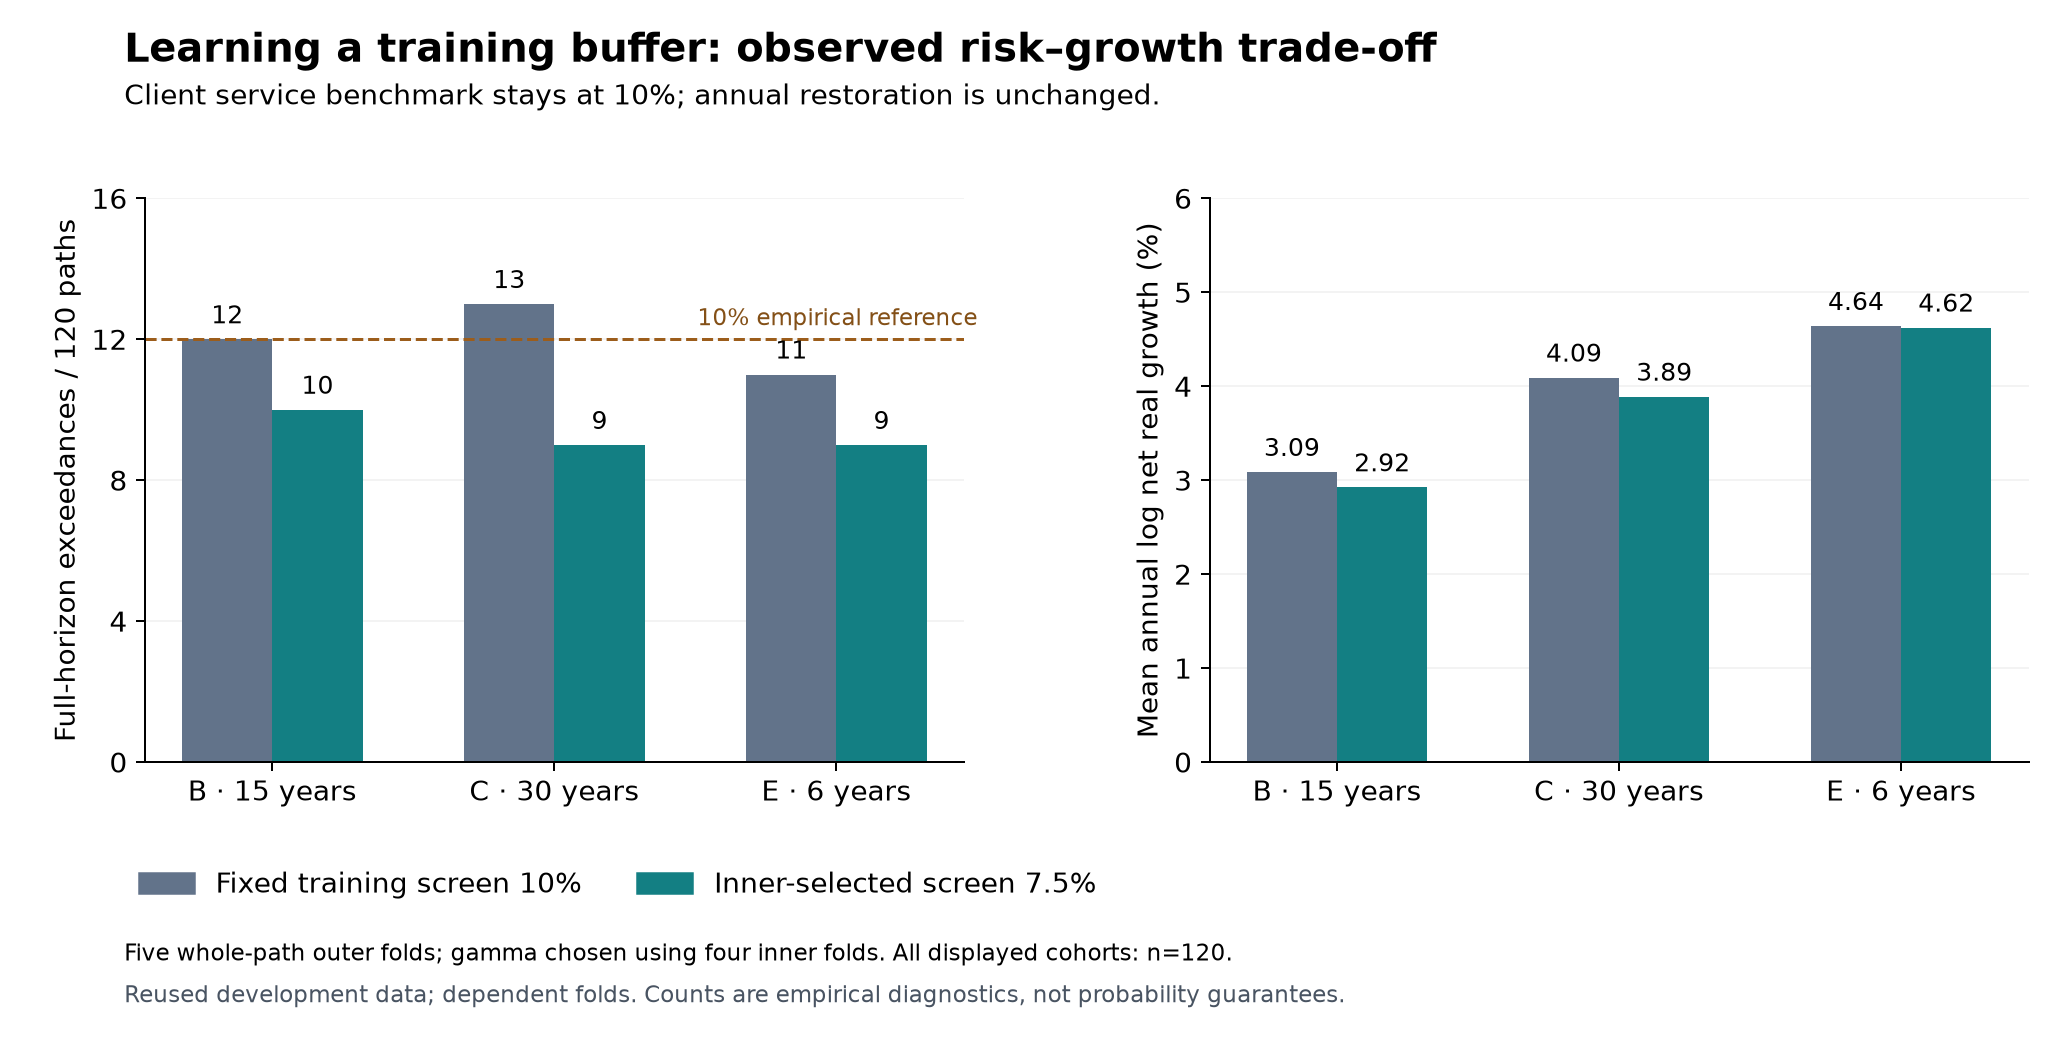

In [12]:
nested_root = ROOT / 'results/model_review/nested_static_calibration_v1'
nested_contexts = readj(nested_root / 'context_refits_raw_effective.json')
nested_inner = readj(nested_root / 'inner_gamma_diagnostics.json')
show(pd.DataFrame([{'context': name, 'selected solver gamma': fit['selection']['selected_gamma'],
                   'service alpha': .10, 'raw covered profiles': fit['raw_covered_profiles'],
                   'effective covered profiles': fit['effective_covered_profiles']}
                  for name, fit in nested_contexts.items()]),
     {'selected solver gamma': '{:.1%}', 'service alpha': '{:.0%}'})
nested_full = nested_contexts['full_development']
show(pd.DataFrame([{'product': row['name'], **dict(zip(['equity', 'bond', 'bill'], row['weights']))}
                  for row in nested_full['raw_fit']['menu']]),
     {x: '{:.0%}' for x in ['equity', 'bond', 'bill']})
show(pd.DataFrame(nested_full['admission_details'])[
     ['client', 'raw_assignment', 'effective_assignment', 'inner_auto_n', 'inner_auto_folds',
      'inner_breach_count', 'inner_conditional_breach_probability']],
     {'inner_conditional_breach_probability': '{:.2%}'})
nested_oof = pd.read_csv(nested_root / 'outer_vs_primary_summary.csv')
show(nested_oof[nested_oof.view.isin(['effective', 'primary_gamma10'])][
     ['view', 'client', 'total_paths', 'auto_n', 'review_n', 'breach_count',
      'breach_probability', 'mean_log_growth', 'p90_mdd', 'cvar90_mdd']],
     {x: '{:.2%}' for x in ['breach_probability', 'mean_log_growth', 'p90_mdd', 'cvar90_mdd']})
chosen_details = [row for row in nested_full['raw_fit']['client_product_details'] if row['chosen']]
show(pd.DataFrame(chosen_details)[['client', 'portfolio', 'breach_count', 'n',
     'postfit_static_family_risk_upper', 'postfit_bound_within_service_alpha']],
     {'postfit_static_family_risk_upper': '{:.2%}'})
print('最后一表仅是另列的固定1160事件族证据诊断，未参与γ选择。需额外iid合成路径假设。')
print('9/120训练超限的同时上界约21.16%，仍高于服务10%；经验余量不能替代概率证据。')
figure(ROOT / 'research/figures/nested_calibration/01_oof_risk_growth_tradeoff.png',
       '固定10%训练筛选与内层选择7.5%训练余量的B/C/E完整路径折外超限次数和平均年化对数增长，所有分母120。')

### 8.2 每个产品都使用三类资产：严格正权重规格对照

题面明确每个产品使用股票、政府债和短期资产。因而将前述允许零权重的232候选保留为放宽规格对照，另预先固定三项权重均不少于5%的网格子集，加精确等权，共172个。5%是既定5个百分点网格的最小正点；“每种资产都使用”本身不能识别这个精确下限，也没有证明连续正权重空间的最优性。

严格子集沿用原六个上下文、同一内层划分、γ候选、选择次序和转介规则；不因为新结果而改准则。所有指标沿候选轴切片，明确保存172本地索引与原232索引的映射，再逐项反查原缓存，避免把局部编号误当原组合。旧研究保持不变。

六个上下文仍都选中γ=7.5%，当前全开发候选为25/30/45、45/5/50、70/10/20，依次为Conservative、Balanced、Growth，资产顺序股票/政府债/票据。在风险维度下B/C/E依次对应这三个产品，A/D转介。严格固定γ=10%的折外B/C/E超限为12/14/11；严格内层选择后为9/9/9，分母均120。这是相同三资产规格下的程序对照，不能与允许零权重的结果混在一起解释为同一变更的效果。

γ一致也不代表精确权重稳定。五个外层训练菜单的Balanced股票为40%–45%、政府债15%–25%、票据35%–40%；全120拟合的45/5/50并未在任何外层训练菜单中出现。这个描述性折间差异提醒我们不要过早冻结权重；它不是置信区间，五个训练样本也相互重叠。

严格nested相对放宽nested的B/C/E年化平均log增长又分别减少约0.068/0/0.038个百分点；不能只因一次超限数更少就宣布总体更优。本轮把严格三资产候选作为后续模型讨论的对象，**尚未冻结最终服务政策**：5%分辨率、流动性适配、严重度及动态执行仍需明确。

In [13]:
positive_root = ROOT / 'results/model_review/positive_asset_specification_v1'
positive = readj(positive_root / 'nested_context_refits.json')
positive_full = positive['full_development']
show(pd.DataFrame([{'product': row['name'], **dict(zip(['equity', 'bond', 'bill'], row['weights'])),
                   'local id': row['candidate_local_index'],
                   'original232 id': row['candidate_original232_index']}
                  for row in positive_full['raw_fit']['menu']]),
     {x: '{:.0%}' for x in ['equity', 'bond', 'bill']})
assert all(min(row['weights']) >= .05 - 1e-12 for row in positive_full['raw_fit']['menu'])
positive_oof = pd.read_csv(positive_root / 'outer_strict_vs_relaxed_summary.csv')
matches = (positive_oof.specification.eq('strict172') & positive_oof.client.isin(['B', 'C', 'E']) &
           ((positive_oof.procedure.eq('nested') & positive_oof.view.eq('effective')) |
            (positive_oof.procedure.eq('fixed_gamma10') & positive_oof.view.eq('raw'))))
show(positive_oof[matches][['procedure', 'view', 'client', 'auto_n', 'review_n', 'breach_count',
                           'breach_probability', 'mean_log_growth', 'p90_mdd', 'cvar90_mdd']],
     {x: '{:.2%}' for x in ['breach_probability', 'mean_log_growth', 'p90_mdd', 'cvar90_mdd']})
print('每个全开发/外层训练上下文的选择：',
      {name: fit['selection']['selected_gamma'] for name, fit in positive.items()})
print('这里只验证年度恢复固定目标。其它执行方式不能继承这些风险表现。')
positive_names = pd.DataFrame([{'candidate_index': row['candidate_original232_index'], 'product': row['name']}
                               for row in positive_full['raw_fit']['menu']])
positive_metrics = grid.merge(positive_names, on='candidate_index', validate='many_to_one')
show(positive_metrics[positive_metrics.horizon.eq(15)][
     ['product', 'median_volatility', 'p90_mdd', 'cvar90_mdd']],
     {x: '{:.2%}' for x in ['median_volatility', 'p90_mdd', 'cvar90_mdd']})
print('上表为全120开发数据、H=15的普通波动与大损失描述，不能替代各客户自身H的适配。')
show(pd.DataFrame([{'context': name,
                   **{row['name']: '/'.join(f'{100*w:.0f}' for w in row['weights'])
                      for row in fit['raw_fit']['menu']}}
                  for name, fit in positive.items()]))
print('配置顺序为股票/政府债/票据，单位%；折间范围不是参数置信区间。')

product,equity,bond,bill,local id,original232 id
Conservative,25%,30%,45%,71,101
Balanced,45%,5%,50%,117,155
Growth,70%,10%,20%,158,206


procedure,view,client,auto_n,review_n,breach_count,breach_probability,mean_log_growth,p90_mdd,cvar90_mdd
nested,effective,B,120,0,9,7.50%,2.86%,24.22%,28.29%
nested,effective,C,120,0,9,7.50%,3.89%,38.20%,43.82%
nested,effective,E,120,0,9,7.50%,4.59%,33.27%,41.50%
fixed_gamma10,raw,B,120,0,12,10.00%,3.05%,24.23%,29.33%
fixed_gamma10,raw,C,120,0,14,11.67%,4.07%,40.45%,47.44%
fixed_gamma10,raw,E,120,0,11,9.17%,4.64%,33.66%,42.74%


每个全开发/外层训练上下文的选择： {'full_development': 0.075, 'outer_fold_1': 0.075, 'outer_fold_2': 0.075, 'outer_fold_3': 0.075, 'outer_fold_4': 0.075, 'outer_fold_5': 0.075}
这里只验证年度恢复固定目标。其它执行方式不能继承这些风险表现。


product,median_volatility,p90_mdd,cvar90_mdd
Conservative,6.70%,24.22%,28.27%
Balanced,9.07%,32.65%,38.67%
Growth,13.25%,44.39%,54.39%


上表为全120开发数据、H=15的普通波动与大损失描述，不能替代各客户自身H的适配。


context,Conservative,Balanced,Growth
full_development,25/30/45,45/5/50,70/10/20
outer_fold_1,25/30/45,40/25/35,70/5/25
outer_fold_2,25/25/50,40/25/35,70/5/25
outer_fold_3,25/30/45,45/15/40,70/5/25
outer_fold_4,25/30/45,45/15/40,70/5/25
outer_fold_5,25/30/45,40/25/35,70/15/15


配置顺序为股票/政府债/票据，单位%；折间范围不是参数置信区间。


## 9. 固定目标执行对照：省费用并不意味着风险更低

本节较早的执行实验保留放宽规格研究的原目标与分配，便于隔离执行规则的作用；严格正权重菜单的新执行研究见10.5–10.9。

在另一份新实验协议中，只改变执行方式：每年恢复同一目标，或初次购买同一目标后始终持有。每折目标来自该折96条训练路径，原客户分配冻结，测试路径24条不参与目标选择。这是同目标的执行消融，**没有针对买入持有重新优化目标或选择赢家**。初次配置两边都收费、后续hold不转移、不收终端清算费。

B/C/E的折外超限次数从12/13/11变为23/34/13。尽管交易更少、费用更低且增长稍高，股票比重会在上涨后累积，尤其改变长期风险。不能将这一结果包装成“低频交易支配年度再平衡”。它说明执行规则是风险模型的一部分，后续门槛策略必须重新验证。

In [14]:
execution_root = ROOT / 'results/model_review/fixed_execution_ablation_v1'
execution = pd.read_csv(execution_root / 'client_summary.csv')
show(execution[execution.scope.eq('oof')][
    ['client', 'policy', 'assigned_paths', 'review_paths', 'breach_count',
     'mean_log_growth', 'p90_mdd', 'mean_trade_fraction', 'mean_nominal_fees', 'mean_terminal_equity']],
    {**{x: '{:.2%}' for x in ['mean_log_growth', 'p90_mdd', 'mean_trade_fraction', 'mean_terminal_equity']},
     'mean_nominal_fees': '{:.4f} units'})
paired = pd.read_csv(execution_root / 'paired_client_summary.csv')
show(paired[paired.scope.eq('oof') & paired.client.isin(['B', 'C', 'E'])][
    ['client', 'assigned_pairs', 'mean_delta_log_growth', 'mean_delta_mdd',
     'new_breach_count', 'averted_breach_count']],
    {x: '{:.3%}' for x in ['mean_delta_log_growth', 'mean_delta_mdd']})
print('配对差先按同一路径计算；mean_delta_mdd不是两个P90之差。')
print('累计名义费用为金额，不是回报百分点；Review成果为空，未假设顾问解决后的收益。')

client,policy,assigned_paths,review_paths,breach_count,mean_log_growth,p90_mdd,mean_trade_fraction,mean_nominal_fees,mean_terminal_equity
A,annual_restore,0,120,—,—,—,—,—,—
B,annual_restore,120,0,12,3.09%,24.78%,100.00%,0.3038 units,30.66%
C,annual_restore,120,0,13,4.09%,40.17%,100.00%,1.1247 units,47.48%
D,annual_restore,0,120,—,—,—,—,—,—
E,annual_restore,120,0,11,4.64%,33.66%,100.00%,0.2552 units,71.49%
A,initial_then_hold,0,120,—,—,—,—,—,—
B,initial_then_hold,120,0,23,3.61%,27.52%,6.67%,0.1099 units,48.49%
C,initial_then_hold,120,0,34,4.92%,48.79%,3.33%,0.1423 units,75.54%
D,initial_then_hold,0,120,—,—,—,—,—,—
E,initial_then_hold,120,0,13,4.75%,35.05%,16.67%,0.2071 units,75.18%


client,assigned_pairs,mean_delta_log_growth,mean_delta_mdd,new_breach_count,averted_breach_count
B,120,0.520%,2.744%,14,3
C,120,0.827%,7.446%,23,2
E,120,0.104%,0.439%,2,0


配对差先按同一路径计算；mean_delta_mdd不是两个P90之差。
累计名义费用为金额，不是回报百分点；Review成果为空，未假设顾问解决后的收益。


### 9.1 扣费时点也观察风险：检查年度口径遗漏了多少

初始配置和后续交易都在当年收益之前扣费。年度末财富已经包含这笔费，但若随后上涨，年度末回撤会掩盖刚扣费时的短暂购买力下降。因此补充一个固定目标的观测诊断：在每个年初扣费后、当年回报实现前，额外观察一次实际财富，使用上一年末的物价指数。只增加观测点，不再扣一次费用，也不改变交易、收益或原筛选结果。

整个232候选×5客户事件中，有11个“组合—客户—路径”单元新增超限；每个受影响组合的超限数只增加1。5%/10%/20%的筛选通过与否均未翻转，九个全开发菜单的固定配对也没有翻转。主规则折外B/C/E仍是12/13/11次。观测遗漏在本例中没有改变这套固定年度策略的经验筛选与原配对；不能据此推广至其它执行方式或所有风险结论。额外观测仍不能恢复未知的年内市场低谷，不是连续时间MDD。

In [15]:
feeobs = readj(ROOT / 'results/model_review/fee_checkpoint_v1/primary_oof_summary.json')
fee_rows = [{'client': row['client'], 'assigned_paths': row['assigned_test_paths'],
             'review_paths': row['review_test_paths'],
             **(row['diagnostic'] or {})} for row in feeobs]
show(pd.DataFrame(fee_rows)[['client', 'assigned_paths', 'review_paths',
     'annual_breach_count', 'feeobs_breach_count', 'annual_p90_mdd', 'feeobs_p90_mdd',
     'mean_mdd_increment']],
     {x: '{:.4%}' for x in ['annual_p90_mdd', 'feeobs_p90_mdd', 'mean_mdd_increment']})
print('新增观测诊断；原年度末定义保留。Review不模拟顾问收益。')

client,assigned_paths,review_paths,annual_breach_count,feeobs_breach_count,annual_p90_mdd,feeobs_p90_mdd,mean_mdd_increment
A,0,120,—,—,—,—,—
B,120,0,12,12,24.7774%,24.7827%,0.0078%
C,120,0,13,13,40.1744%,40.1835%,0.0081%
D,0,120,—,—,—,—,—
E,120,0,11,11,33.6592%,33.6669%,0.0335%


新增观测诊断；原年度末定义保留。Review不模拟顾问收益。


## 10. 有限期限费用门槛原型：费用一致，但尚未约束动态风险

单期“恢复目标”相对“继续持有”净对数差为
$$\Delta=\log\frac{w^\top g}{u^\top g}+\log(1-C/V)
=\log\frac{x_{\rm after}^\top g}{x^\top g}.$$
如果已用扣费后的持仓计算，不能再次减费。共同的一期通胀因子在配对差中抵消，但完整路径风险仍用实际财富计算。

另一项重要限制是短视：一次配置费可能需要多年增益才能覆盖。构造例中，股票每年确定增长0.15%、配置费0.25%，买入并持有的一年净对数差为负，而两年为正。如果每年都只问“下一年值不值”，从全票据出发可能永远拒绝一个两年有益的配置。预期增长改善也不自动维持完整期限的回撤约束。

为解决这个短视例子，我们实现了一个**固定目标、只允许持有或恢复目标**的有限期限原型。比例费用与对数目标使财富规模可以提出状态，状态为实际权重 $u$ 和剩余期限 $h$。目标不随时间更新。令 $\Phi(u,g)=u\odot g/(u^\top g)$，近似递推为

$$Q_h^{\rm hold}(u)=\mathbb E[\log(u^\top g)+I V_{h-1}(\Phi(u,g))].$$
$$Q_h^{\rm trade}(u)=\log(1-\rho(u,w))+\mathbb E[\log(w^\top g)+I V_{h-1}(\Phi(w,g))].$$
$$V_h(u)=\max\{Q_h^{\rm hold}(u),Q_h^{\rm trade}(u)\},\qquad V_0=0.$$

其中 $g$ 是名义收益因子，$I V$ 是对未来价值表的重心插值，$\rho=C/V$ 是本次恢复目标实际支付的财富比例。这里的 $V/Q$ 省略了各动作共同的期望通胀常数，只用于动作比较；固定IID预测下，真实价值另减 $h\,\mathbb E[\log(1+\iota)]$。实际路径绩效与风险始终保留通胀。

预测只来自各自训练集的联合年度机会经验混合，并假设未来机会稳定、逐年独立。年度记录是积分支持，不是新增独立路径。未来价值用单纯形重心插值；当前收益与费用直接计算，以避免插值低估持有价值而误触发交易。每个客户H从初始100重新模拟，不能拿30年策略的前5年当作5年策略。初次交易也由门槛判断；本轮所测目标实际均选择初次投资。

该原型在两期摊费用例中修正了单期门槛，但**没有将回撤约束放入递推**。因此实际实验得到的不是可直接部署的风险受控策略，而是一个检验“经济增长门槛是否足以维持原适配”的消融对照。两种网格的折外B/C/E超限都是26/40/14次，远高于原年度规则12/13/11；更高增长和更低交易频率并未补足适配条件。有限期限与单期门槛在本数据中的差异很小，不能据此声称所有长期考虑都无价值。

client,horizon,policy,assigned_paths,breach_count,mean_log_growth,median_cagr,p10_cagr,median_mdd,p90_mdd
E,6,annual_restore,120,11,4.64%,5.42%,-3.81%,15.22%,33.66%
B,15,annual_restore,120,12,3.09%,3.33%,0.28%,14.06%,24.78%
C,30,annual_restore,120,13,4.09%,4.12%,1.50%,24.06%,40.17%
E,6,initial_then_hold,120,13,4.75%,5.51%,-4.07%,16.08%,35.05%
B,15,initial_then_hold,120,23,3.61%,3.51%,0.20%,17.25%,27.52%
C,30,initial_then_hold,120,34,4.92%,4.62%,1.22%,32.86%,48.79%
E,6,myopic_gate,120,14,4.79%,5.59%,-4.02%,16.14%,35.24%
E,6,finite_horizon_gate,120,14,4.79%,5.59%,-4.02%,16.14%,35.24%
B,15,myopic_gate,120,26,3.77%,3.75%,0.06%,17.80%,27.86%
B,15,finite_horizon_gate,120,26,3.77%,3.75%,0.06%,17.80%,27.86%


client,policy,mean_trade_fraction,mean_nominal_fees,initial_trade_fraction
E,annual_restore,100.00%,0.2552 units,100%
B,annual_restore,100.00%,0.3038 units,100%
C,annual_restore,100.00%,1.1247 units,100%
E,initial_then_hold,16.67%,0.2071 units,100%
B,initial_then_hold,6.67%,0.1099 units,100%
C,initial_then_hold,3.33%,0.1423 units,100%
E,myopic_gate,31.25%,0.2137 units,100%
E,finite_horizon_gate,31.53%,0.2137 units,100%
B,myopic_gate,15.72%,0.1231 units,100%
B,finite_horizon_gate,15.72%,0.1231 units,100%



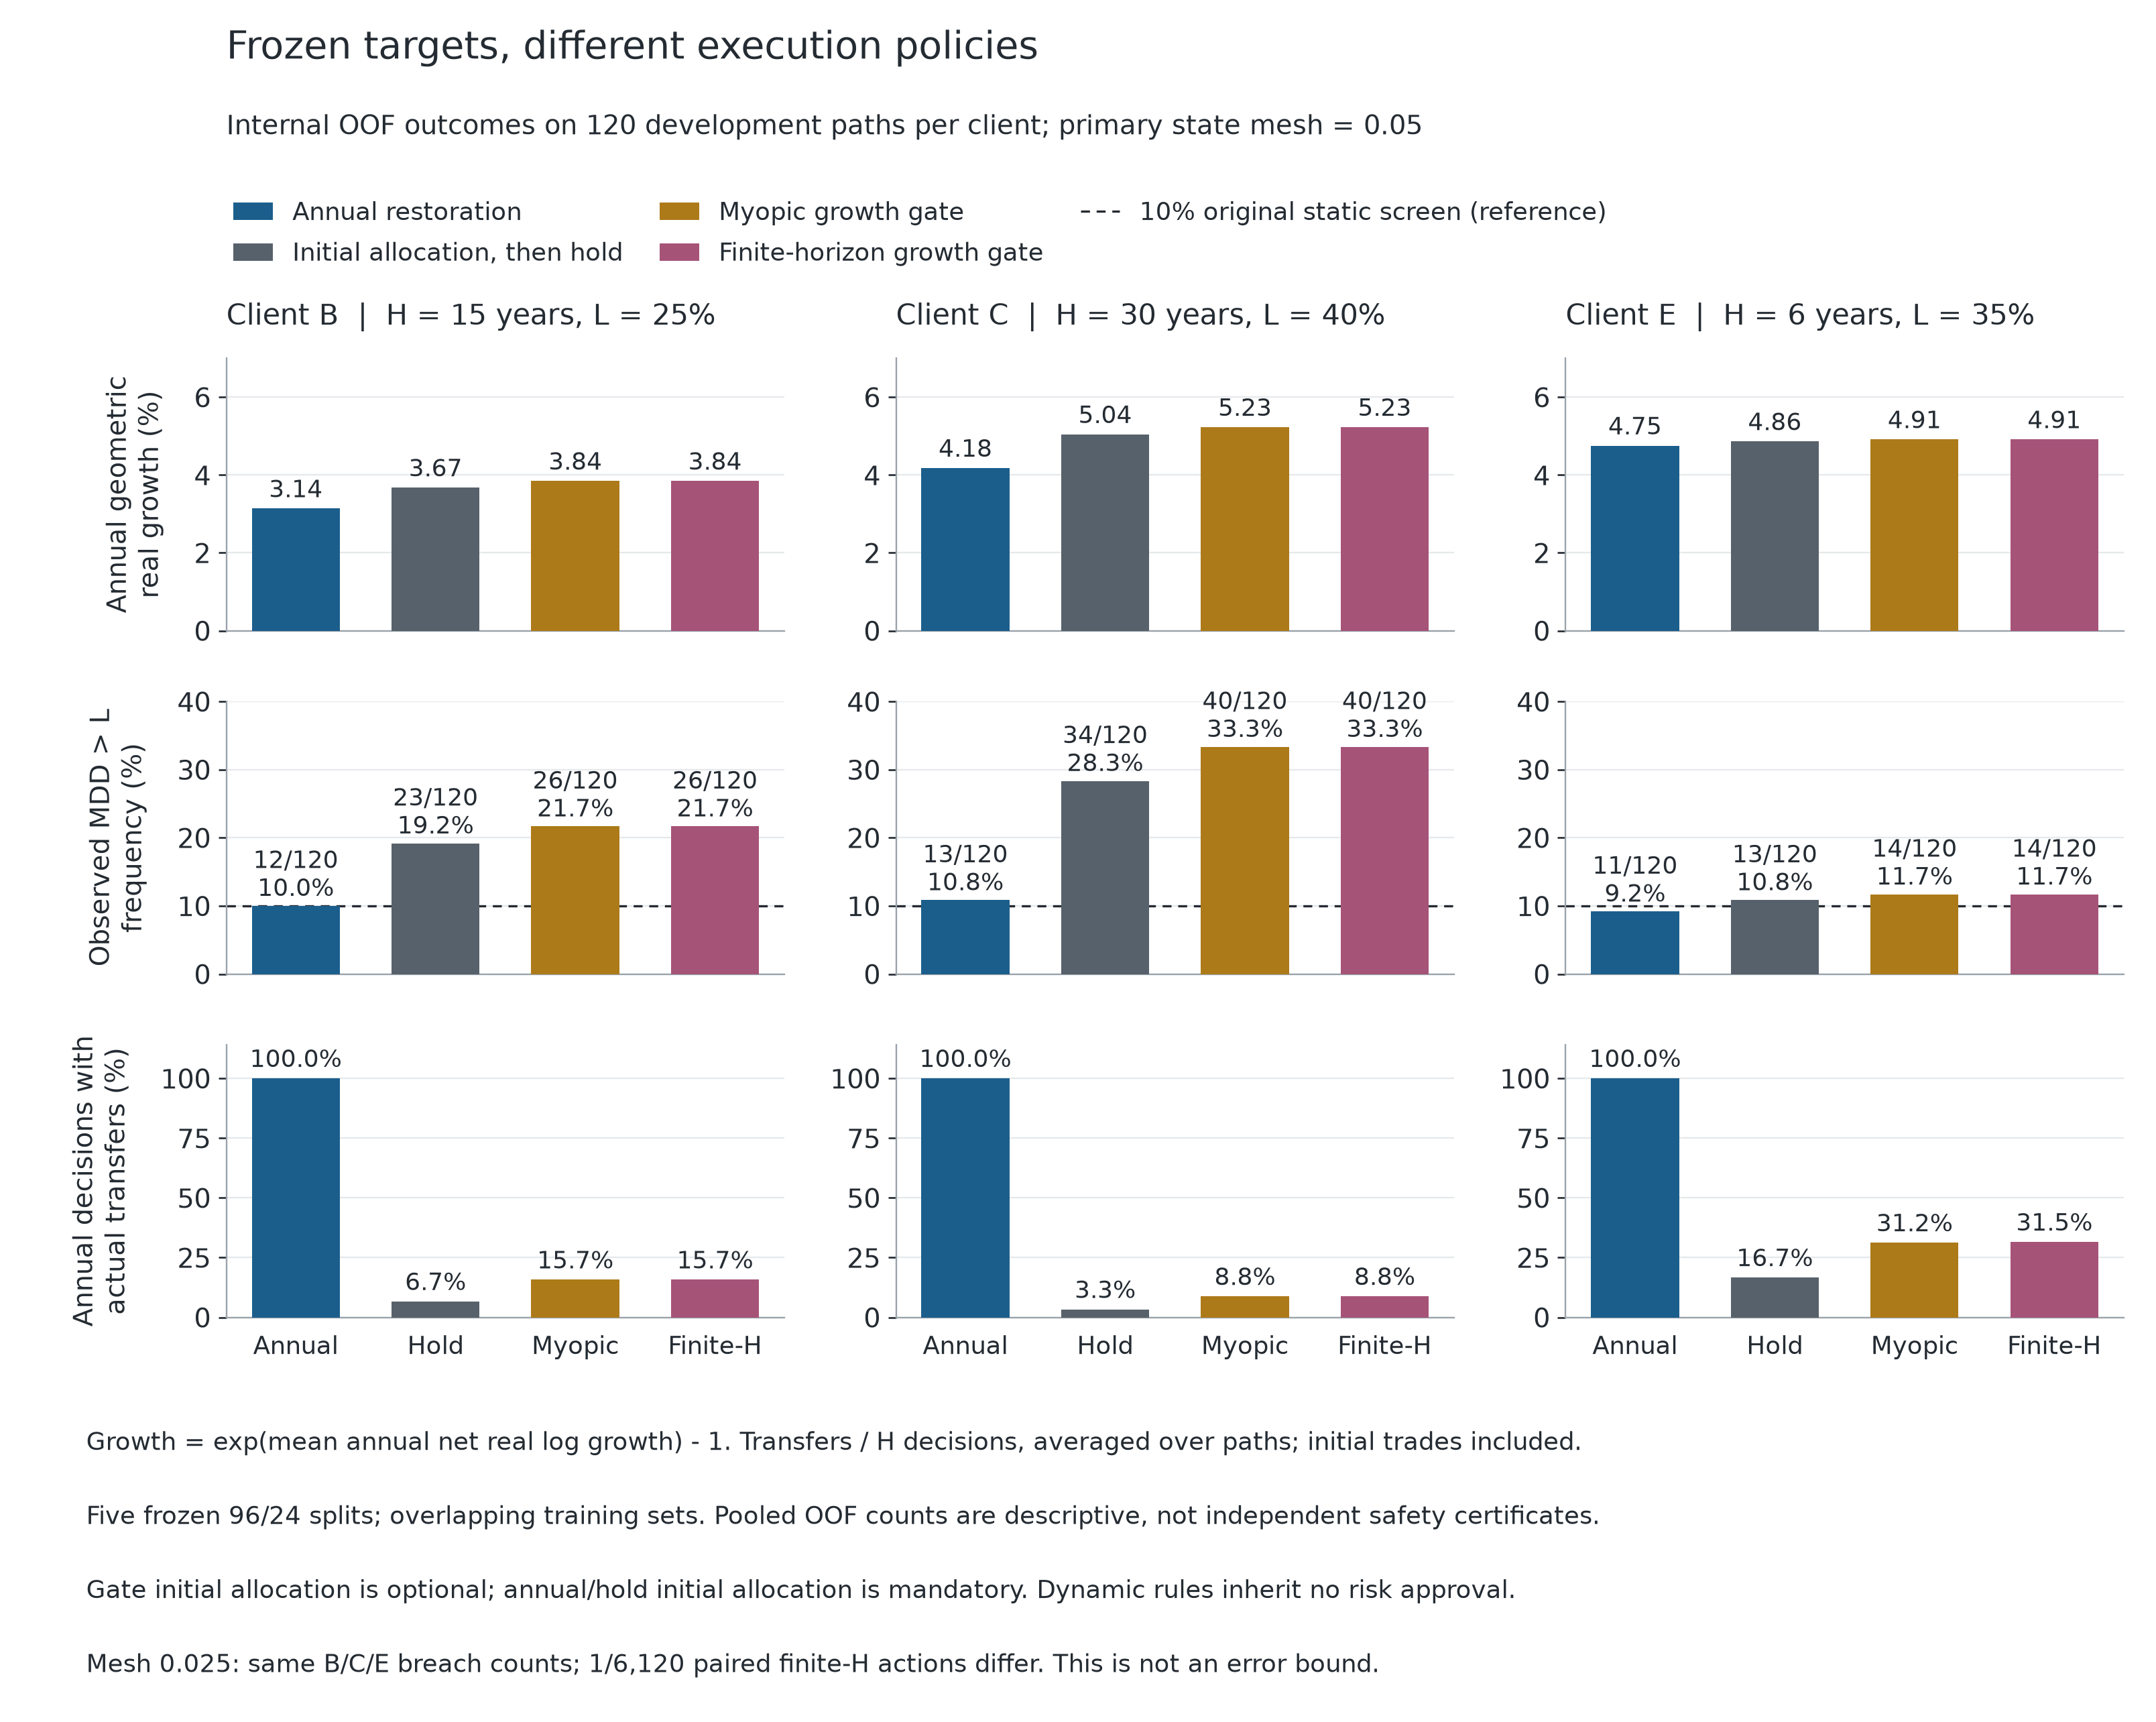

In [16]:
finite_root = ROOT / 'results/model_review/finite_horizon_execution_v1'
finite = pd.read_csv(finite_root / 'client_summary.csv')
finite_oof = finite[finite.scope.eq('oof') & finite.client.isin(['B', 'C', 'E'])
                    & (finite.mesh_step.isna() | np.isclose(finite.mesh_step, .05))].copy()
show(finite_oof[['client', 'horizon', 'policy', 'assigned_paths', 'breach_count',
                 'mean_log_growth', 'median_cagr', 'p10_cagr', 'median_mdd', 'p90_mdd']],
     {x: '{:.2%}' for x in ['mean_log_growth', 'median_cagr', 'p10_cagr', 'median_mdd', 'p90_mdd']})
show(finite_oof[['client', 'policy', 'mean_trade_fraction', 'mean_nominal_fees', 'initial_trade_fraction']],
     {'mean_trade_fraction': '{:.2%}', 'mean_nominal_fees': '{:.4f} units', 'initial_trade_fraction': '{:.0%}'})
figure(ROOT / 'research/figures/execution/01_oof_growth_risk_and_trading.png',
       '同一训练目标的年度再平衡、买入持有、单期与有限期限增长门槛：折外增长、回撤超限及交易频率。')

独立小树审计采用8个预定合成案例、两种费率、H1/2/3和两种网格，96组对照、495项核查通过。这里动作碰巧达到小树最优，但粗网格表值仍能比实际策略的模型内收益高约 $9.82\times10^{-4}$，所以 $V/Q$ 只能称近似预测价值。真实路径绩效来自逐年执行回放，不取自价值表。网格0.025与0.05在B/C/E折外6,120个对应决策中仅1个不同，超限计数不变；这不是一般误差界。

下一步需要把原始期限内的风险放入执行设计。对年度观测的MDD，至少要保留 $z=R/\text{running peak}$ 和是否曾超限的标志 $b$；不能每年重新给一次10%预算。给定风险约束的拉格朗日影子价与任意客户偏好λ是不同概念，但确定策略可能存在对偶间隙，不能说“调出一个系数便保证10%”。已经实现并核查下面的短期合成树参考；尚未实现或选定长期风险约束求解器。该较早的有限期限原型未启用目标更新；后续三目标研究见10.8，训练选中的模式仍为不更新。

设计与核查见 `docs/finite_horizon_execution_design_review.json`、`docs/dynamic_risk_state_design_review.json` 和 `results/model_review/finite_horizon_execution_v1/synthetic_tree_audit.json`。有限期限递推的一般背景可参阅 [MIT动态规划课程材料](https://ocw.mit.edu/courses/6-231-dynamic-programming-and-stochastic-control-fall-2015/pages/related-video-lectures/)；本研究的费用模型、限制和结果以仓库中的推导与独立核查为准。

### 10.1 年份顺序：相同年度机会不等于相同路径风险

额外固定一个H=30的压力诊断：每条开发路径中的三资产收益和通胀向量始终成组移动，分别使用原顺序、完全倒序、固定种子的随机排列。目标、分配、原训练预测混合和执行参数均冻结，不再选型。这是反事实顺序压力，不是新增独立市场路径，也不用于寻找表现最好的排列。

C的折外超限，年度恢复目标在三种顺序下为13/13/9；初次配置后持有为34/27/22；有限期限增长门槛为40/38/25，分母均120。持有终值在排列下保持不变，但MDD会变化；年度恢复在比例费用下还会因最后一年的位置产生很小的终值差异。这个对照说明，仅用一个无序年度收益混合来积分，并不等于已经验证了真实路径的时间结构。

压力诊断保留原顺序为参考，不据此重排数据或选择新策略。下一轮动态模型应明确时间平稳性与独立性是计算假设，另验证对顺序、持续低迷和通胀共同变化的敏感性。

In [17]:
temporal = pd.read_csv(ROOT / 'results/model_review/temporal_order_v1/client_C_summary.csv')
show(temporal[temporal.scope.eq('oof')][
     ['order', 'policy', 'assigned_paths', 'breach_count', 'mean_log_growth', 'p90_mdd', 'mean_trade_fraction']],
     {x: '{:.2%}' for x in ['mean_log_growth', 'p90_mdd', 'mean_trade_fraction']})
print('三种顺序是同一批路径的相关压力情形，不能合并为360条独立证据。')

order,policy,assigned_paths,breach_count,mean_log_growth,p90_mdd,mean_trade_fraction
original,annual_restore,120,13,4.09%,40.17%,100.00%
original,initial_then_hold,120,34,4.92%,48.79%,3.33%
original,finite_horizon_gate,120,40,5.09%,50.15%,8.81%
reverse,annual_restore,120,13,4.09%,40.18%,100.00%
reverse,initial_then_hold,120,27,4.92%,46.20%,3.33%
reverse,finite_horizon_gate,120,38,5.15%,47.84%,9.25%
permuted,annual_restore,120,9,4.09%,36.83%,100.00%
permuted,initial_then_hold,120,22,4.92%,43.08%,3.33%
permuted,finite_horizon_gate,120,25,5.10%,46.23%,9.03%


三种顺序是同一批路径的相关压力情形，不能合并为360条独立证据。


### 10.2 让完整期限风险进入决策：可核查的小树与下一轮递推

已经实现一个不读取比赛数据的参考求解器：最多三种联合“资产回报—通胀”结果、最多三期、固定目标、持有或恢复目标。每个决策只能依赖已经观察到的历史，枚举完整历史策略后得到 $(g,q)$ 前沿，其中 $g$ 是期望总实际log增长，$q$ 是全期限内至少一次回撤超限的概率。先合并所有未来分支，最后只在根节点使用一次预算；不是对每个未来节点重新给α。

独立程序用自己的二分费用算法、历史动作枚举和逐路径回撤计算，核查5个合成模型×两种裁剪方式，共83项通过，数值误差约 $10^{-15}$。另有20项合成单元检查，包括两期10%独立触发事件合并为19%、通胀使全票据也超限、超限标记不被恢复清除，以及裁剪不改变小例子最优解。这些检查不验证比赛市场模型、连续状态网格或30年风险控制。

小树还展示确定策略的一个限制：若仅有安全策略 $(g,q)=(0,0)$ 与风险策略 $(0.10,0.20)$，预算为0.10，确定策略只能选安全策略，最优增长0；允许事先掷硬币混合完整策略的数学放宽可达到约0.05。拉格朗日对偶会得到这个混合上界。因此“调一个影子价格”不保证得到满足原预算的最优确定策略。这里没有向客户提出随机化建议。

下一轮可将条件风险预算 $r$ 加入状态。对离散、完全可观察、预先固定的模型，给定持有/恢复动作 $a$，把预算分配给各个下一期分支 $r_j$，要求
$$\sum_j p_j r_j\le r,\qquad 0\le r_j\le1.$$
终点值为 $F_0(u,z,b;r)=0$ 当 $b\le r$，否则不可行。下一期的实际净财富因子为 $s_j$，先真实计算
$$z'_j=\min(1,zs_j),\qquad b'_j=b\lor\{zs_j<1-L\}.$$
再在可行分支预算内最大化 $\sum_j p_j[\log s_j+F_{h-1}(u'_j,z'_j,b'_j;r_j)]$。已经超限的分支必须分配 $r_j=1$；恢复到新峰值不会撤销过去的事件。根预算才是原始α，后续沿观察到的分支携带先前分配的预算。

这是明确的下一步设计，尚未实现长周期版本。确定策略的风险—增长前沿可以非凸，不能把预算方向的线性插值当成可部署的确定策略。经验模型的未来分支也不包含所有可能实际收益，必须另行定义支持集外的预算转移和回退，才算完整的在线策略；近邻匹配或重置α不能代替这项设计。若还要约束超限严重度，则必须再记住历史最大回撤幅度；仅有是否超限的一个比特不够。年度末与扣费即时观测也需要分别定义。当前小树仅用年度末观测，并将正预算的64个机器精度舍入保护记录为requested/effective两值，零预算保持严格零；数值保护不构成经济风险余量或原预算的精确可行性证明。

In [18]:
tree_audit = readj(ROOT / 'results/model_review/risk_tree_reference_v1/independent_audit.json')
nested_audit = readj(nested_root / 'independent_audit.json')
positive_audit = readj(positive_root / 'independent_audit.json')
assert tree_audit['status'] == nested_audit['status'] == positive_audit['status'] == 'passed'
assert not tree_audit['market_data_read'] and not tree_audit['final_scenarios_read']
show(pd.DataFrame([{'audit': 'Short synthetic risk tree', 'checks passed': tree_audit['checks_passed'],
                   'scope': 'Fixed finite toy model; full-history deterministic policies'},
                  {'audit': 'Nested saved-output consistency', 'checks passed': nested_audit['checks_passed'],
                   'scope': 'IDs, conditional denominators, gamma selection, admission and hashes'},
                  {'audit': 'Strict positive-asset specification', 'checks passed': positive_audit['checks_passed'],
                   'scope': 'Local/global indexing, training-only fits, positive weights and OOF records'}]))
print('这些是数值/流程核查次数，不能加总为独立市场样本量。')

audit,checks passed,scope
Short synthetic risk tree,83,Fixed finite toy model; full-history deterministic policies
Nested saved-output consistency,"3,114","IDs, conditional denominators, gamma selection, admission and hashes"
Strict positive-asset specification,"17,506","Local/global indexing, training-only fits, positive weights and OOF records"


这些是数值/流程核查次数，不能加总为独立市场样本量。


### 10.3 精确等权基准：按题目要求报告完整路径分位

下表补齐Q2的指定基准：目标始终为每类资产精确1/3，每次年度审查恢复目标并实际收费。比较对象是原折外C客户在自身30年期限下的Balanced执行；所有策略各有相同120条原始开发路径，每折24条。分位数从全部逐路径结果一次计算，不能平均五个折的分位数。

等权基准使用不同目标，所以它与其它策略的差异同时包含目标配置与执行方式；只有前四个原目标策略之间才是纯执行对照。年度Balanced的中位增长高于等权，同时P90回撤也更大；增长门槛的较高增长伴随更明显的回撤增加。这份表支持讨论取舍，不替代尚未完成的风险约束执行设计或最终评估。

In [19]:
q2_benchmark = pd.read_csv(ROOT / 'results/model_review/q2_oof_benchmark_v1/summary.csv')
assert q2_benchmark.n_paths.eq(120).all()
show(q2_benchmark[['policy', 'n_paths', 'median_cagr', 'p10_cagr', 'median_mdd', 'p90_mdd',
                   'breach_count', 'actual_trade_fraction', 'mean_nominal_fees']],
     {**{x: '{:.2%}' for x in ['median_cagr', 'p10_cagr', 'median_mdd', 'p90_mdd', 'actual_trade_fraction']},
      'mean_nominal_fees': '{:.4f} units'})
print('交易比例分母为120×30=3600个实际审查时点，包含初次配置；费用为累计名义金额。')

policy,n_paths,median_cagr,p10_cagr,median_mdd,p90_mdd,breach_count,actual_trade_fraction,mean_nominal_fees
annual_restore,120,4.12%,1.50%,24.06%,40.17%,13,100.00%,1.1247 units
initial_then_hold,120,4.62%,1.22%,32.86%,48.79%,34,3.33%,0.1423 units
myopic_gate,120,4.77%,1.15%,33.97%,50.15%,40,8.78%,0.1605 units
finite_horizon_gate,120,4.77%,1.15%,33.97%,50.15%,40,8.81%,0.1605 units
equal_weight_annual,120,3.58%,1.26%,20.10%,34.70%,6,100.00%,0.9685 units


交易比例分母为120×30=3600个实际审查时点，包含初次配置；费用为累计名义金额。


### 10.4 严重回撤个案：高终值无法抹去中途的损失

为给Q2提供可审查的执行过程，先规定挑选“原年度策略折外C客户中MDD最大的路径，并列取最小情景ID”，再从已有冻结执行记录提取数据。选中情景5、第5折、目标股票45%/政府债15%/票据40%；它是该折的目标，不是全120拟合目标。比较同一路径、同一折、同一目标的三种执行方式，另列不同目标的精确等权年度参考。

年度恢复目标的实际财富在第1年达到112.10，第7年降至47.41，最大回撤57.71%，到第18年才恢复此前峰值。有限期限增长门槛的末财富更高，但本例最大回撤为58.27%，最后股票占比94.70%。买入持有本例回撤反而小于年度策略；结合前面的全体折外结果，可以看到“平均上较少超限”不意味着每条路径都更好。

这个个案按年度策略的最差表现选出，**不能代表典型客户或用来排名总体策略**。它帮助解释为何需要同时报告中途回撤、持仓漂移、交易费用和恢复时间，不能只展示30年末财富。逐年表和来源指纹见 `results/model_review/q2_severe_episode_v1/`。


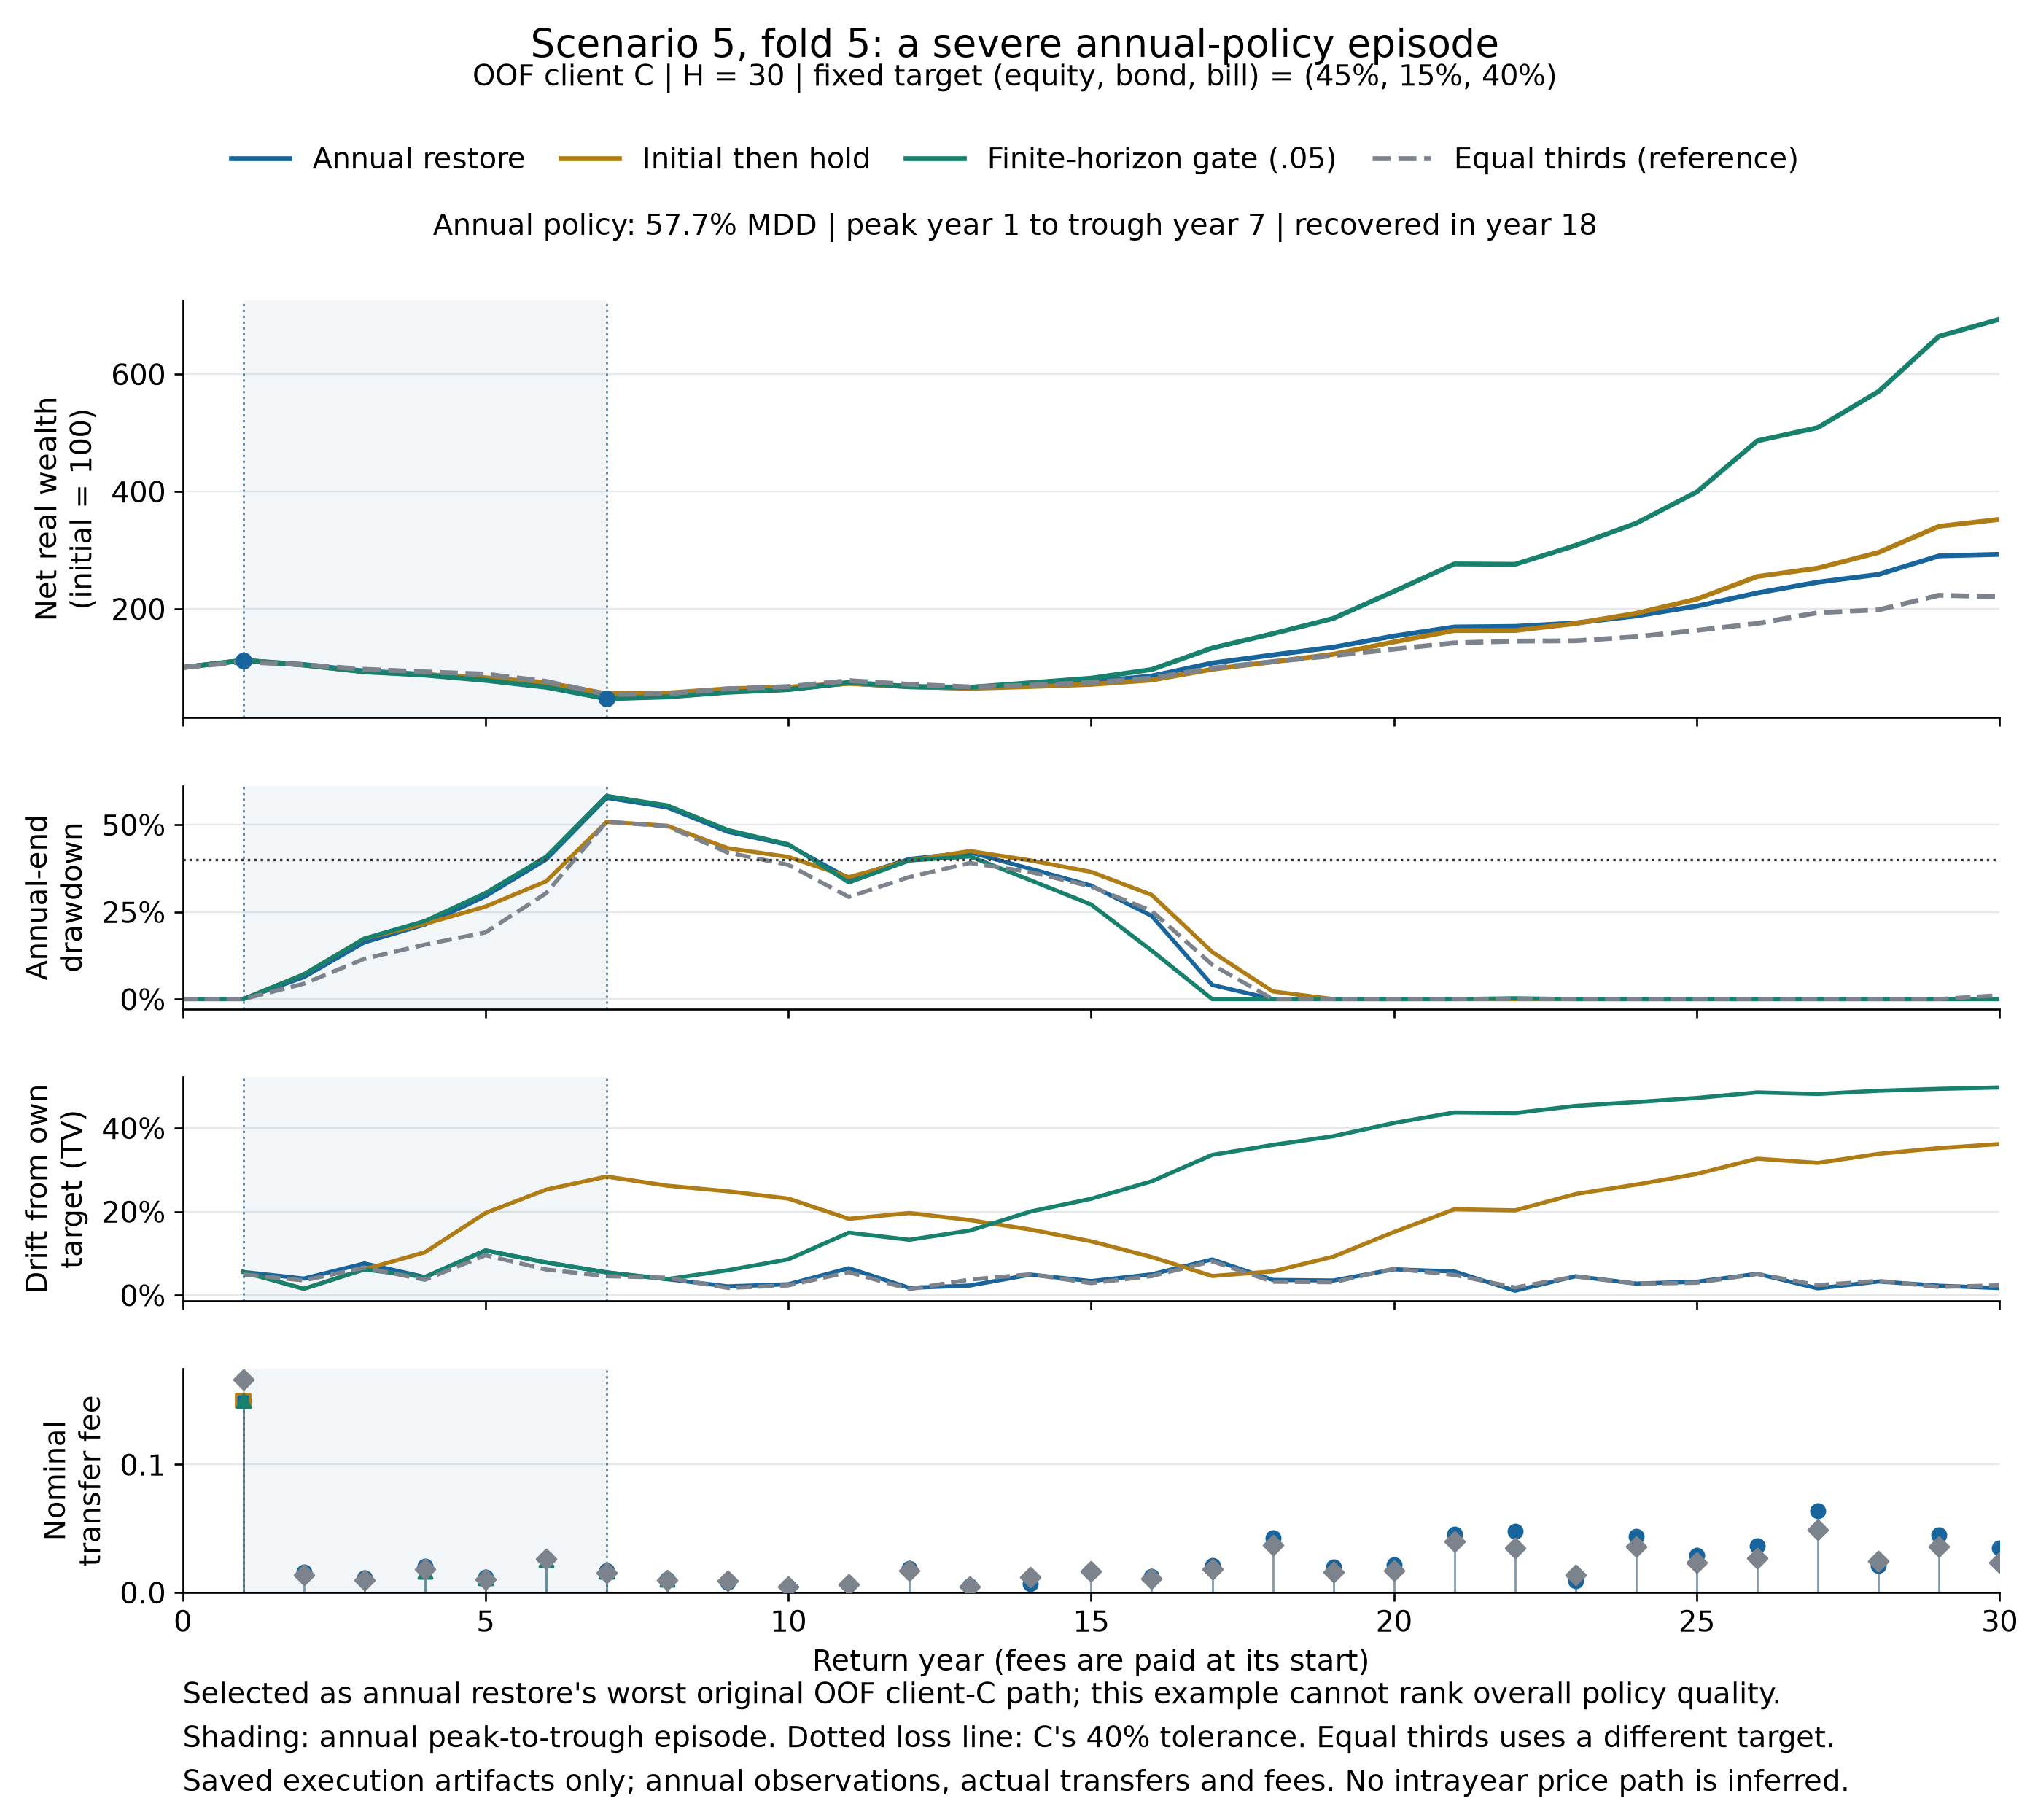

年初支付转移费，随后实现该年回报；图不推断未知的年内市场低谷。


In [20]:
episode_root = ROOT / 'results/model_review/q2_severe_episode_v1'
episode = readj(episode_root / 'episode.json')
assert episode['selected']['scenario_id'] == 5 and episode['selected']['fold'] == 5
figure(episode_root / 'severe_episode.png',
       '原年度策略折外C客户最严重回撤路径：三种同目标执行与不同目标等权参考的实际财富、年度回撤、目标漂移和实际费用。')
print('年初支付转移费，随后实现该年回报；图不推断未知的年内市场低谷。')

### 10.5 超限后等待审核：事件不可撤销，后续严重度仍可变化

本轮不改产品、客户分配或问卷阈值，使用严格172规格的冻结六个情景上下文。原策略与等待策略直到首次年度回撤超限 $\tau$ 完全相同；等待从下一个决策开始，只持有实际资产数量，价格、通胀、财富、历史峰值与回撤继续演化。假设到原期限结束都没有人工回应，是一个可计分情景，不是对真实顾问响应时间的估计。

这带来一个逐路径恒等式：没有超限，两臂始终相同；已经超限，两臂的吸收标记都已为1。因此，两臂的首次超限时间和完整期限“至少一次超限”必相同。B/C/E各为9/120；不能把等待审核说成降低了这个事件的概率。等待可以影响的是后续严重度、终值、费用和恢复。

恢复的参考固定为首次超限时的历史峰值 $P_\tau$，不随以后新高重选。只有以后年度实际财富达到该峰值才记录恢复；到原H尚未恢复的条目右删失，不能填一个虚构未来日期。每个客户触发子群仅9条，已恢复者的中位时长只描述该子群，不代表总体恢复时间。

client,arm,total_profile_paths,auto_n,review_n,breach_count,mean_log_growth,mean_nominal_fees,recovery_risk_set_n,recovered_n,right_censored_n
A,annual,120,0,120,—,—,—,—,—,—
B,annual,120,120,0,9,2.8568%,0.31528,9,2,7
C,annual,120,120,0,9,3.8889%,1.09178,9,2,7
D,annual,120,0,120,—,—,—,—,—,—
E,annual,120,120,0,9,4.5871%,0.24136,9,1,8
A,pending_hold,120,0,120,—,—,—,—,—,—
B,pending_hold,120,120,0,9,2.8508%,0.30937,9,2,7
C,pending_hold,120,120,0,9,3.9080%,1.07153,9,2,7
D,pending_hold,120,0,120,—,—,—,—,—,—
E,pending_hold,120,120,0,9,4.5843%,0.23984,9,1,8



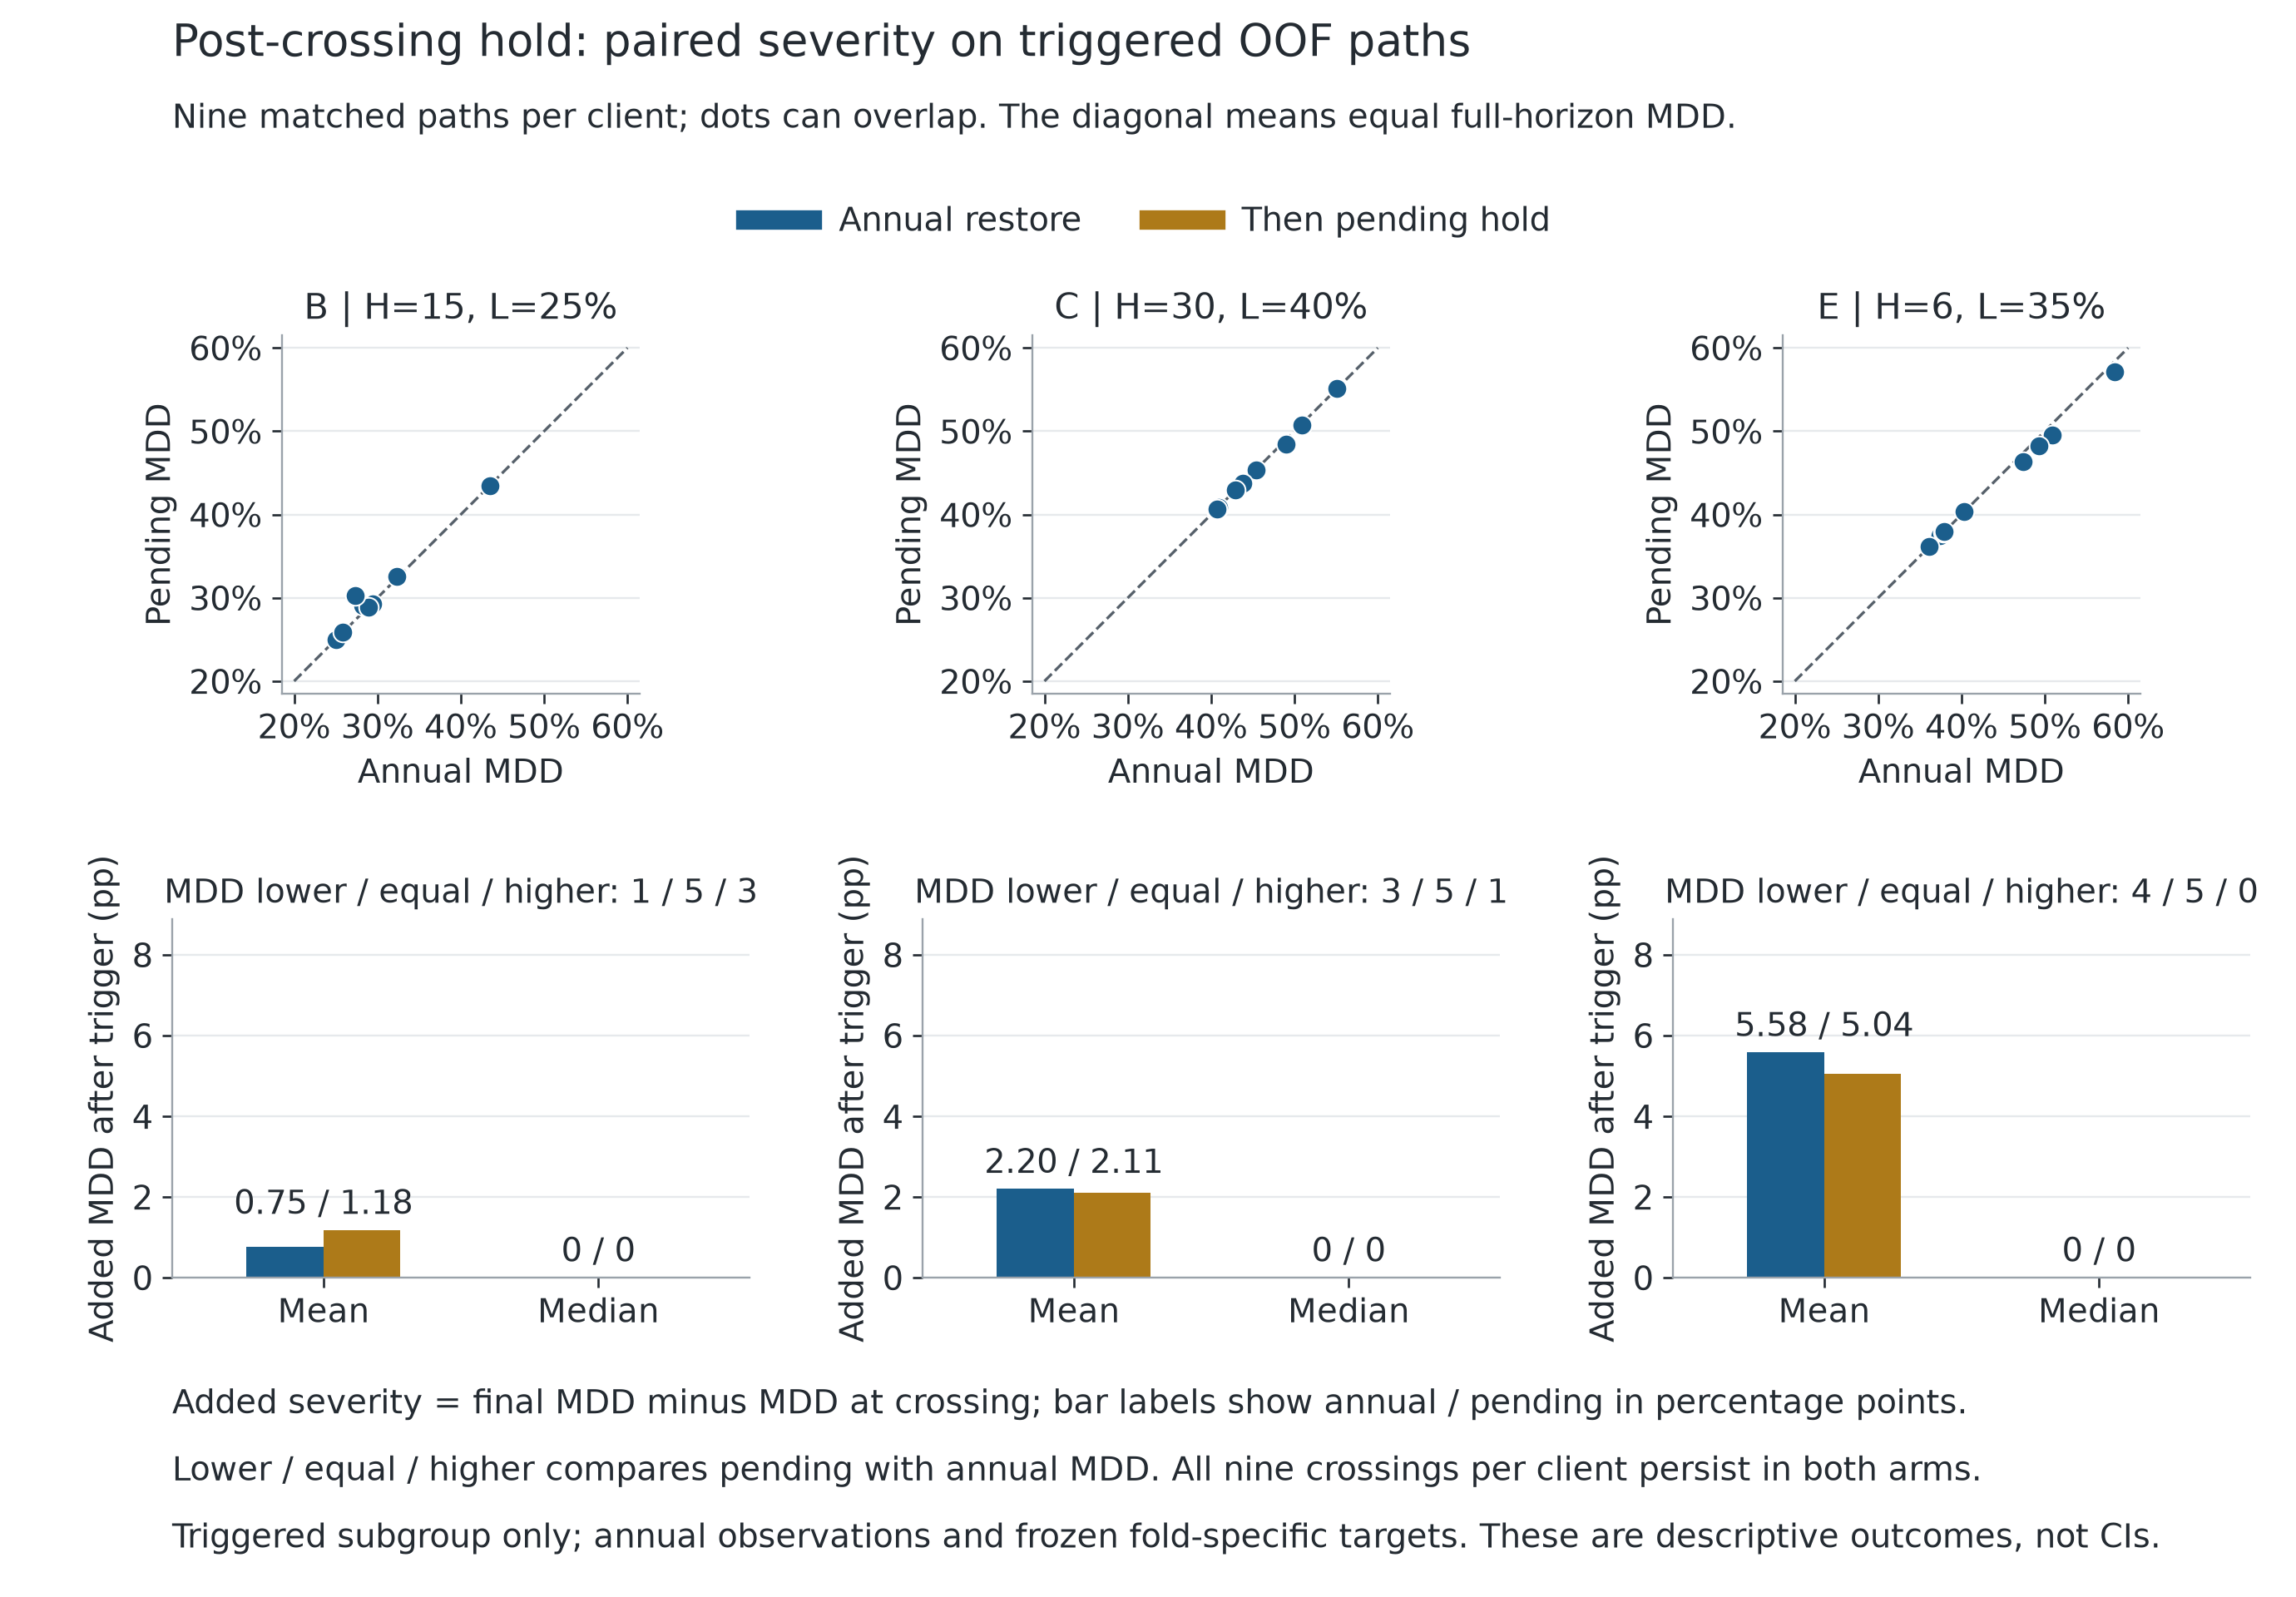


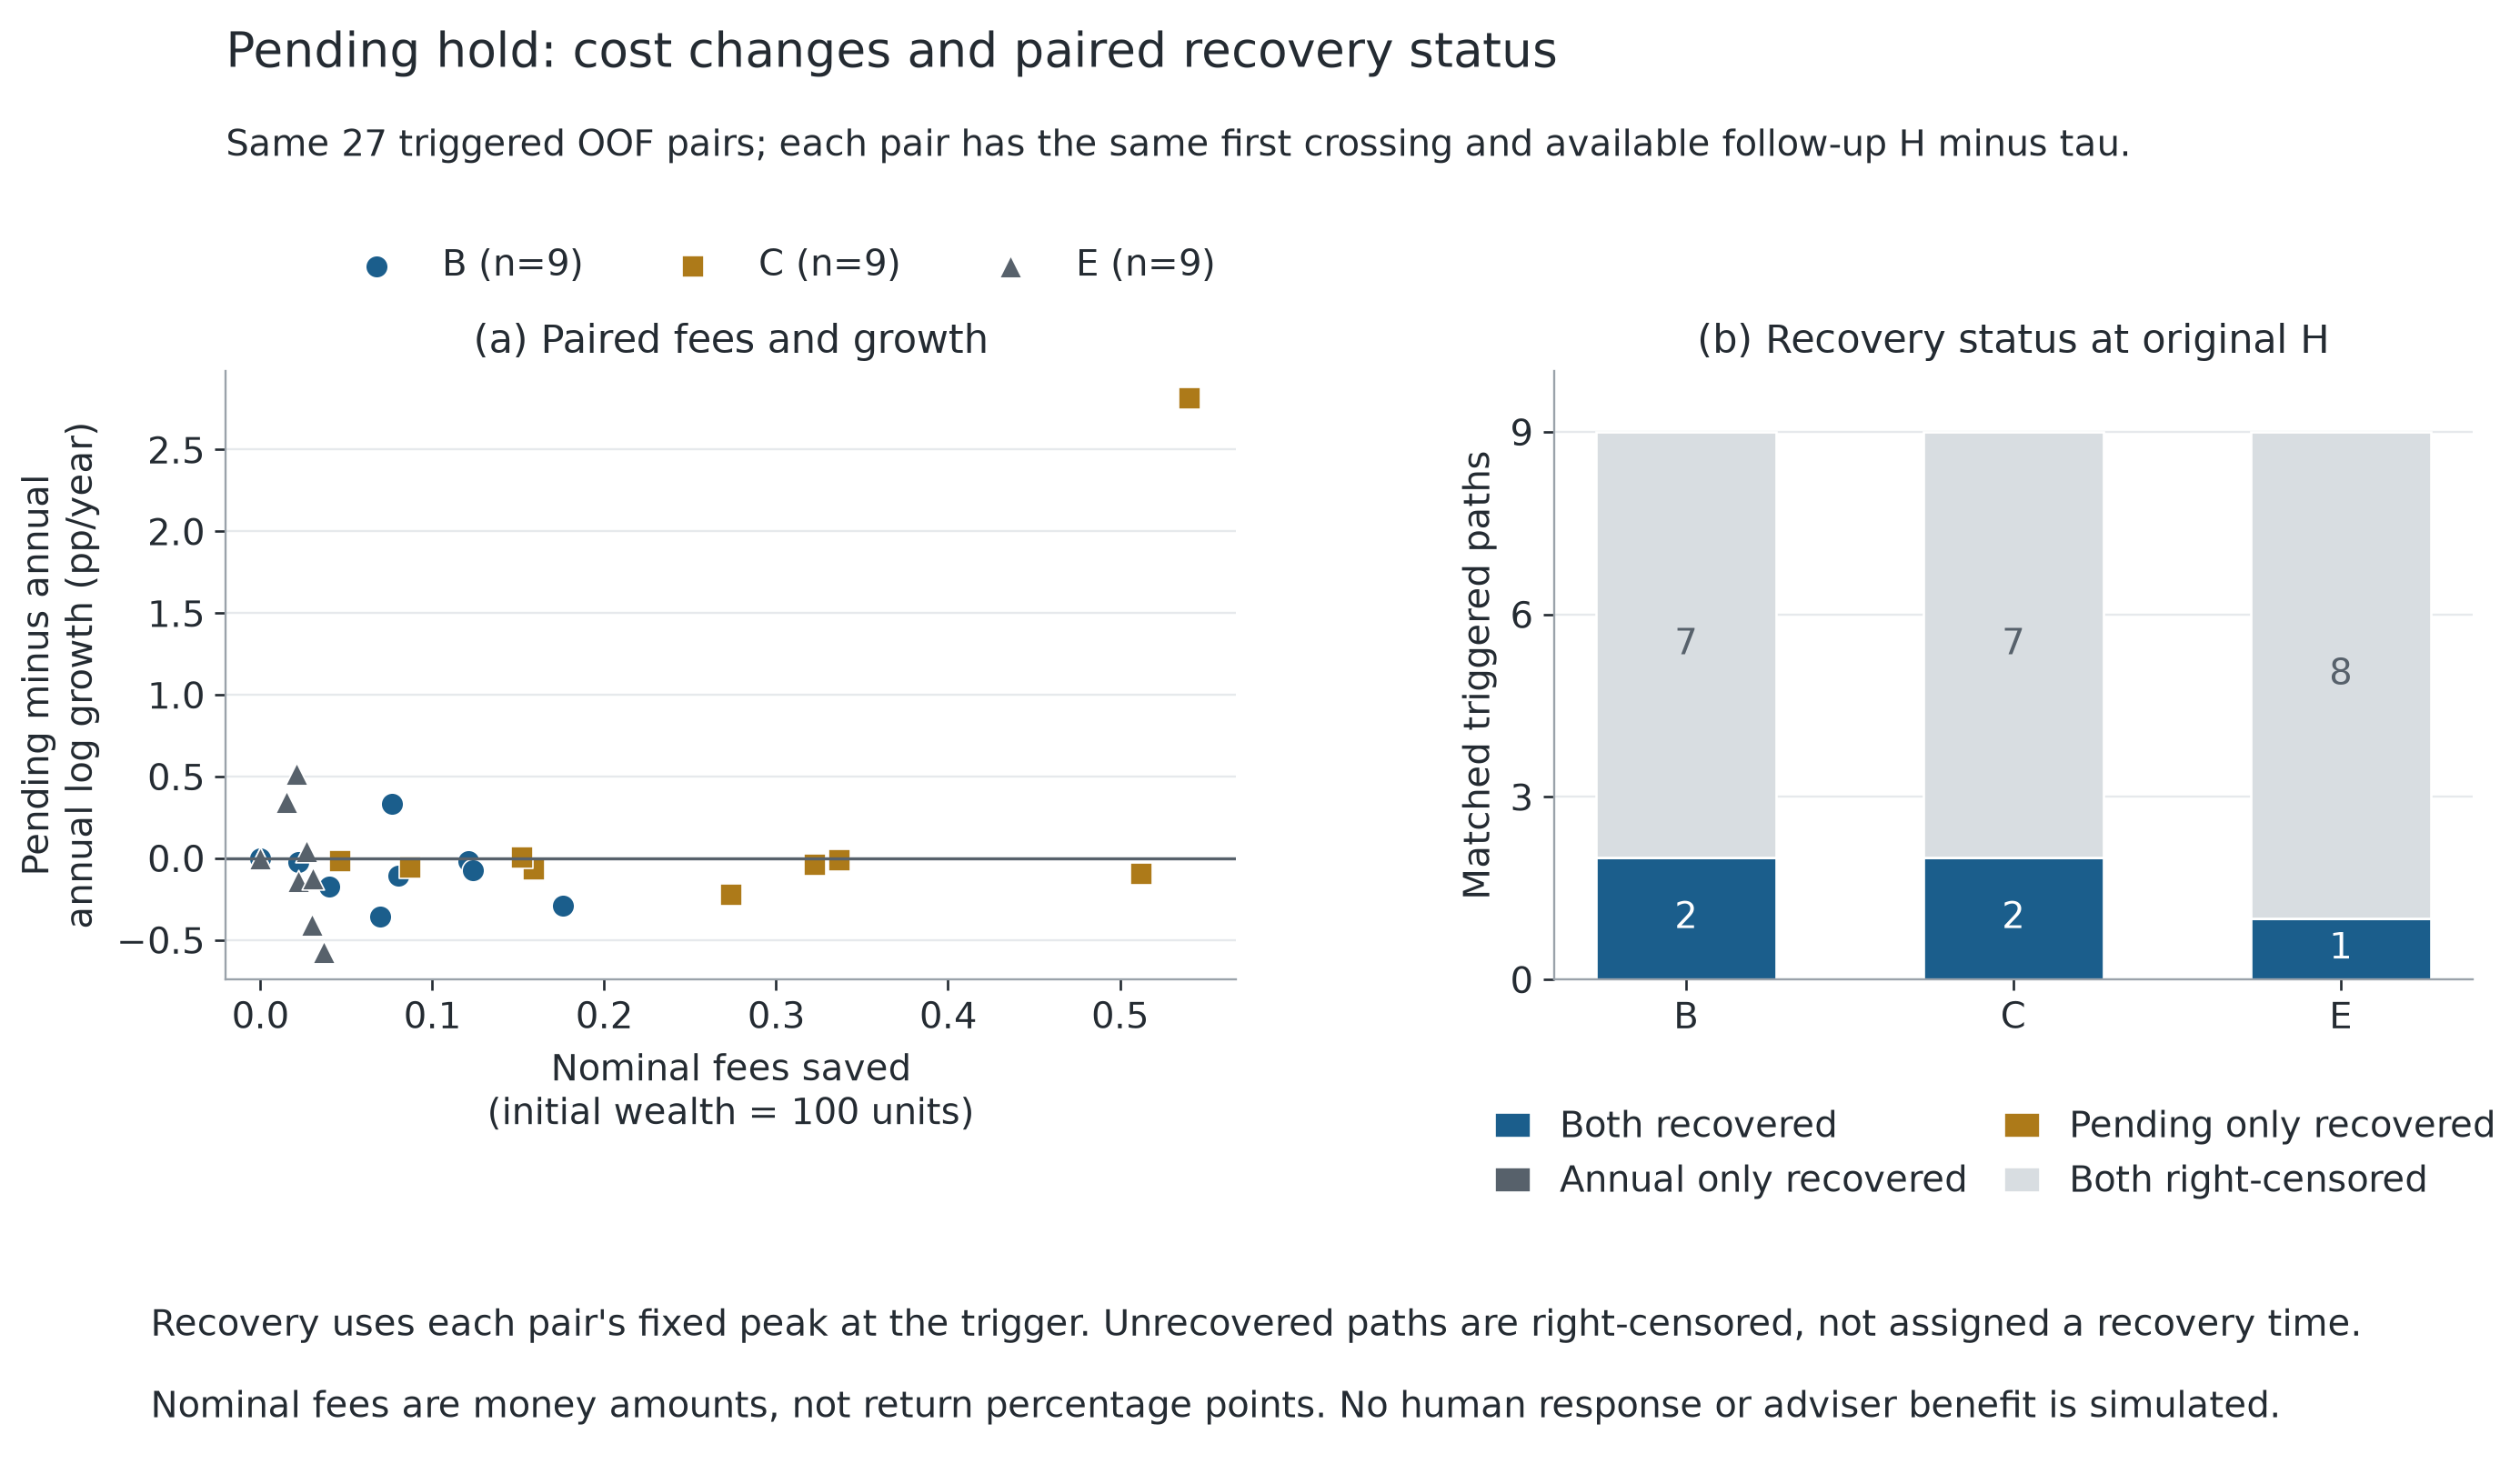

In [21]:
pending_root = ROOT / 'results/model_review/review_pending_execution_v1'
pending_audit = readj(pending_root / 'independent_audit.json')
assert pending_audit['status'] == 'passed'
pending_summary = pd.read_csv(pending_root / 'profile_summary.csv')
pending_oof = pending_summary.query("scope == 'oof' and subset == 'all_assigned'")
show(pending_oof[['client', 'arm', 'total_profile_paths', 'auto_n', 'review_n', 'breach_count',
                  'mean_log_growth', 'mean_nominal_fees', 'recovery_risk_set_n', 'recovered_n', 'right_censored_n']],
     {'mean_log_growth': '{:.4%}', 'mean_nominal_fees': '{:.5f}'})
figure(ROOT / 'research/figures/execution_stage/01_pending_triggered_severity.png',
       '严格172固定组合：同一首次超限后等待持有，对后续最大回撤及新增严重度的逐路径影响。')
figure(ROOT / 'research/figures/execution_stage/02_pending_growth_cost_recovery.png',
       '相同触发与随访窗口下，等待持有的增长、费用和恢复状态；删失未被当作已恢复。')

### 10.6 局部预测更好，为什么整条策略仍可能更差

比较动作 $a$ 时，先执行当前的持有或恢复目标，再假设未来按“每年恢复目标，首次超限后持有”的基准B继续。训练情景从当前日历年到原H的完整联合后缀构成共同预测扇形。每条后缀保留资产、通胀和时间次序；它们是无条件参考，并非已证明正确的“给定当前历史后的未来分布”。每年重新混合这些后缀不自动产生一个动态一致的条件模型。

两种先行对照是：只最大化预测净对数增长；以及只有当持有相对恢复的预测平均增长不低、预测超限条数不高时才省掉交易。后者称局部Pareto持有。它没有新风险系数，但也没有整体风险保障。两条合成路径已给出反例：当前比较中持有的平均增长更高，两个动作预测超限数相同；完整路径实际重放却从1/2超限升为2/2，第一条末财富由135降为130。原因是比较忽略了已观察历史透露的路径信息。精确平均或增加同类后缀，不能自动修复这个条件预测问题。

更保守的逐路径规则要求：对**每一条**训练后缀，持有的未来净增长都不低，终端超限标记都不高，才允许省交易。对同一固定扇形中保留的完整路径，可从任意一致状态反向归纳证明该规则相对B的增长/事件非劣性；换成扇形之外的新路径则没有这个结论。本轮默认费用下，它在全部训练与OOF情景中都退回了B，没有额外省交易。零增长容差是动作门槛；1e-10只用于数值性质核查，不能偷偷作为可牺牲的经济收益。


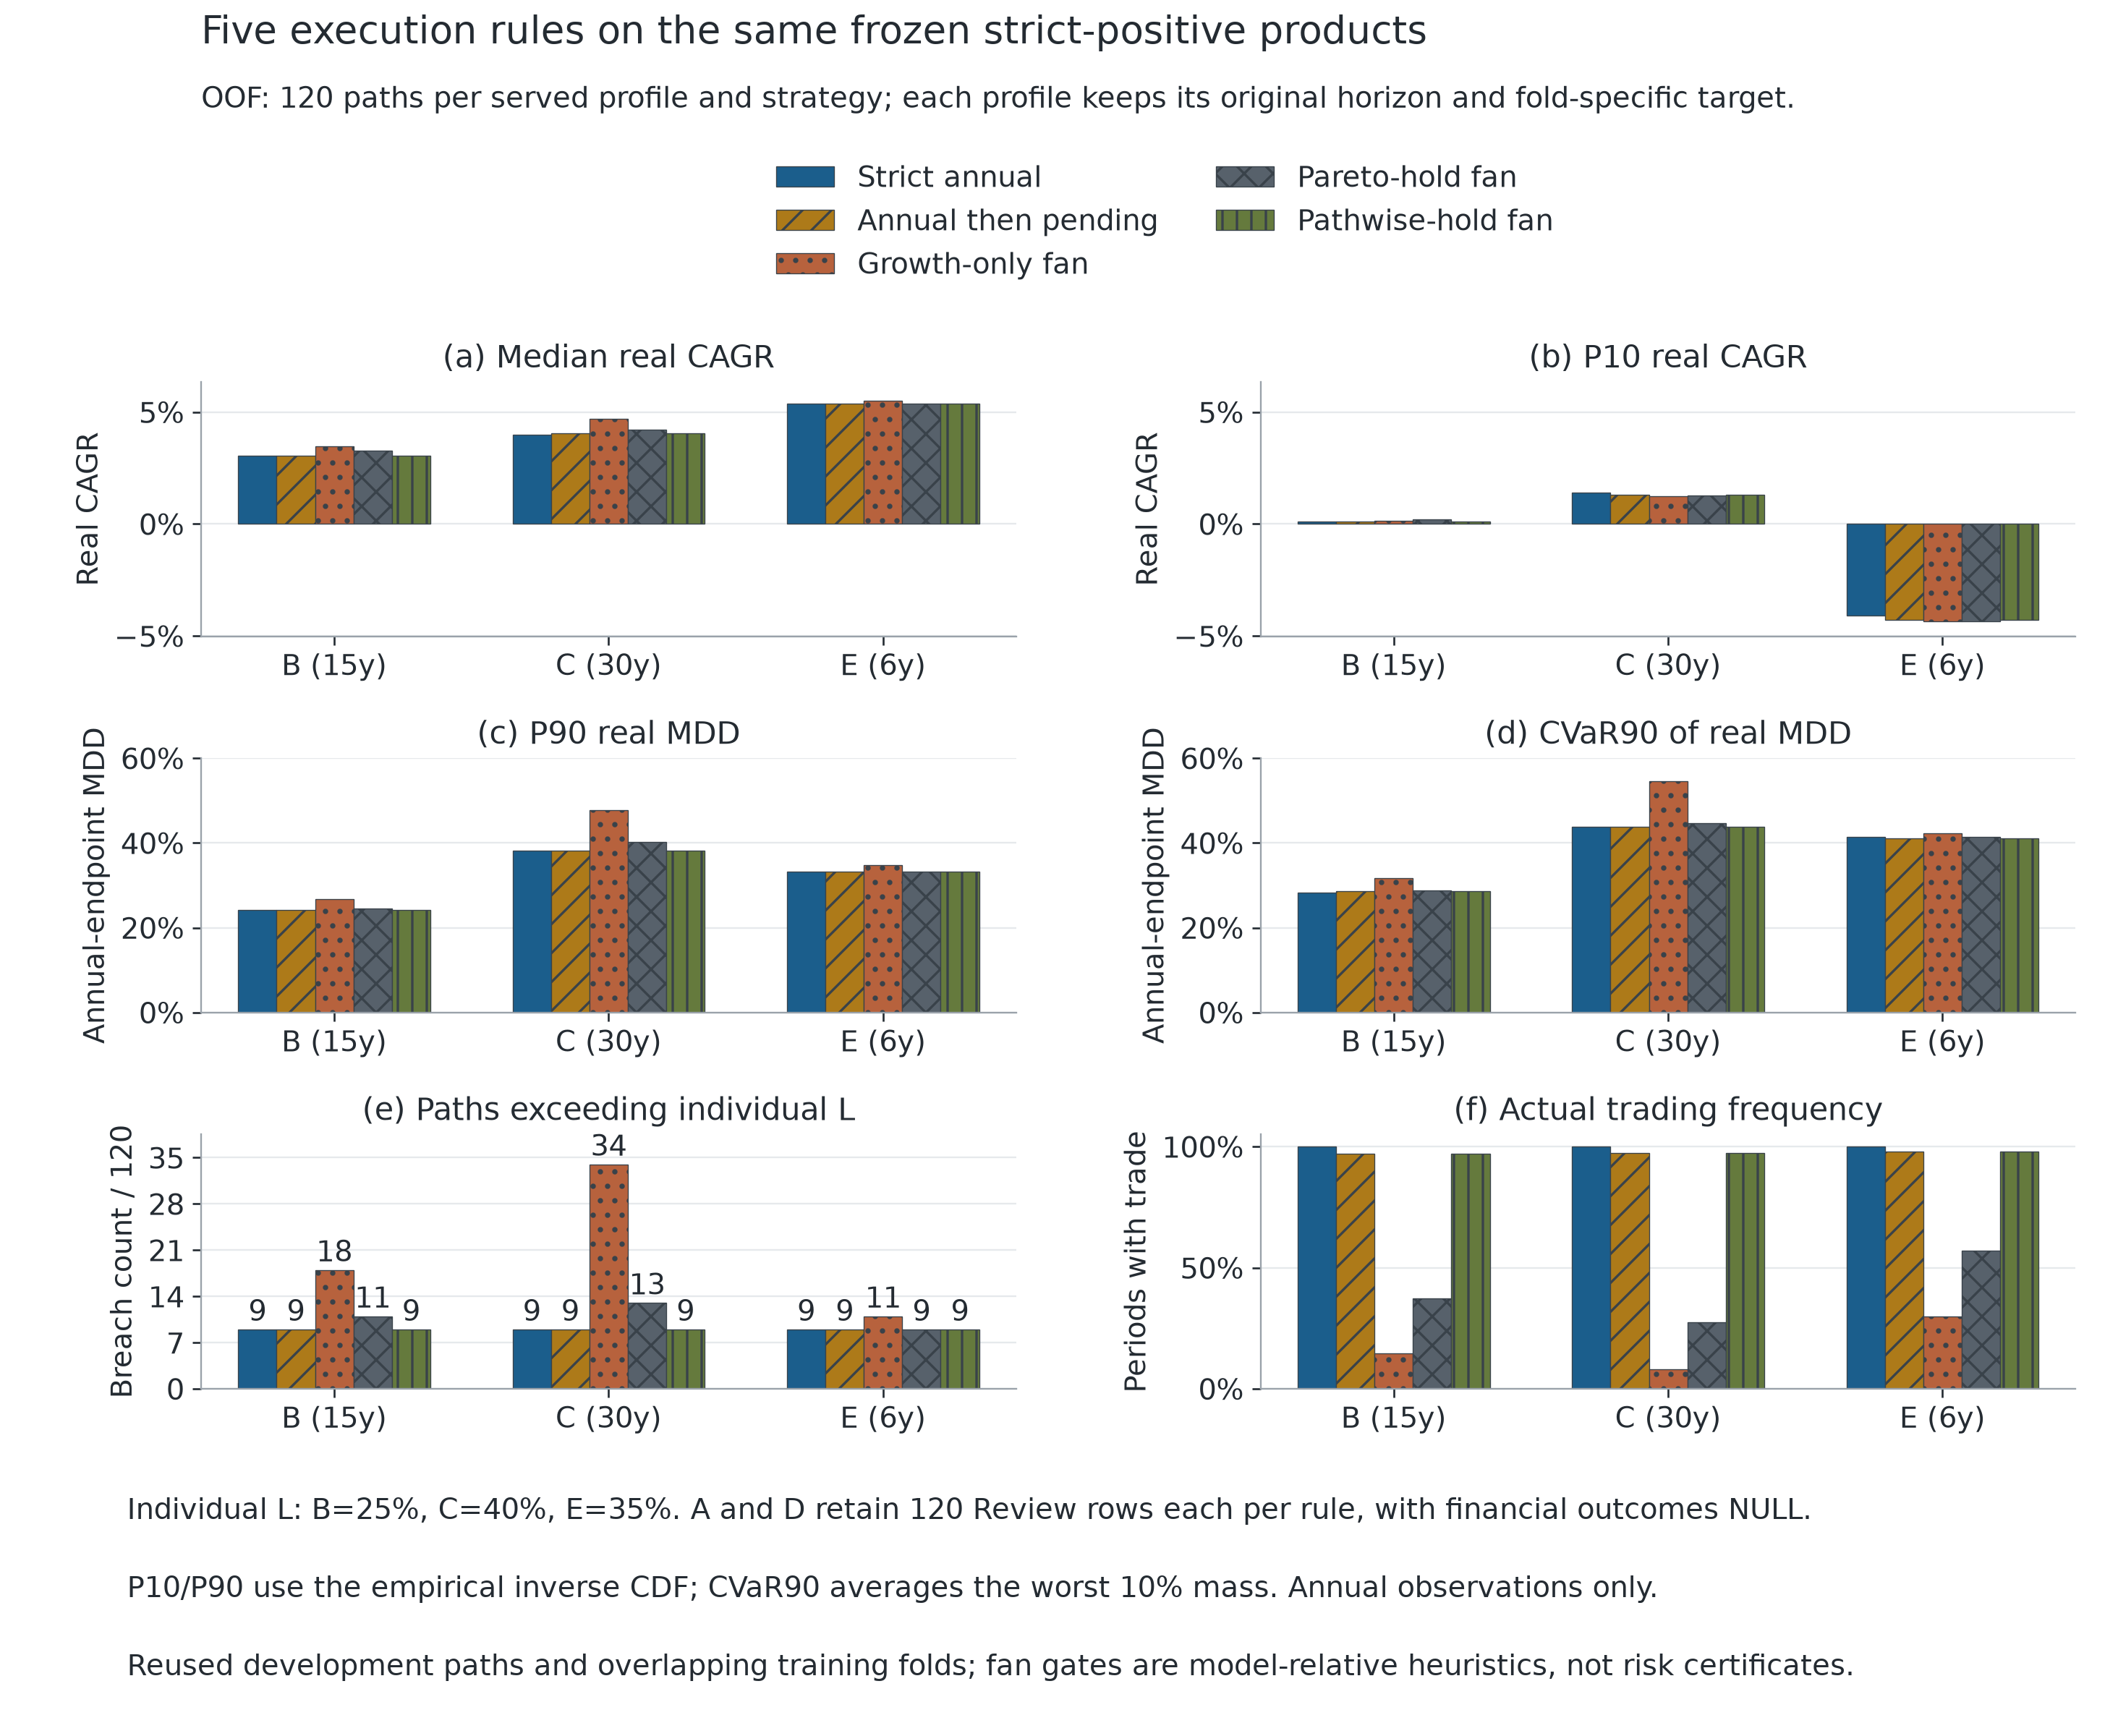

同一固定fan性质检查： 1800 个context/client/path配对；不是独立市场样本数。
每客户full120加五组重叠96=600个训练身份；OOF仍仅原120条完整情景。


In [22]:
figure(ROOT / 'research/figures/execution_stage/04_five_strategy_oof_comparison.png',
       '五种冻结目标执行规则的OOF增长、回撤、事件频率与实际交易比例；逐路径保护规则在本轮等于等待基准。')
support = pd.read_csv(ROOT / 'results/model_review/pathwise_fan_execution_v1/training_support_summary.csv')
served_support = support.query('assigned_paths > 0')
assert served_support.breach_order_violations.eq(0).all()
assert served_support.strictly_negative_computed_growth_delta_count.eq(0).all()
print('同一固定fan性质检查：', int(served_support.assigned_paths.sum()), '个context/client/path配对；不是独立市场样本数。')
print('每客户full120加五组重叠96=600个训练身份；OOF仍仅原120条完整情景。')

### 10.7 用完整路径训练风险调整交易门槛

下一项研究保留相同产品和预测参考，增加一组事先声明的技术参数，而不把它冒充客户风险厌恶。对于当前恢复与持有，计算包含所有当前/未来基准费用的总对数增长差 $\Delta g_t$ 与预测完整历史超限概率差 $\Delta q_t$，有限价门槛为

$$\Delta g_t-H\eta\,\Delta q_t>10^{-12}.$$

H始终是客户原期限，不随剩余年份缩短而重定价。$\eta$ 是每单位超限概率对应的年化对数增长交换价；有限网格为0、.001、.003、.01、.03、.1、.3、1，另有单列的“先最小预测风险，再比较增长”候选。后者不用无穷大乘法。这个有限网格是可检查的技术搜索范围，不是问卷识别出的偏好、真实KKT影子价或条件风险预算。

每个训练上下文、每个已分配客户都完整重放九个候选；只有完整期限超限条数不高于“原年度参照条数”和“10%乘训练条数向下取整”二者较小值的候选才可入选。再最大化训练平均年化净对数增长；数值并列优先较小有限价。这个相对参照上限是额外的保守设计选择。若全不合格，在投资前转介执行审核，不能用年度恢复偷偷填成合格。折外只运行训练选定的一个候选，或保留审核空结果。

题面要求预计收益足以解释成本，并没有要求收益只能是增长。因此，风险下降可以构成交易收益：有限价每笔主动恢复都必须具有严格正的上述净分数，未定价增长可以下降。必须同时披露收益定义、参数选择依据和预测误差，不能把正分数说成实际获利保证。初配与已经等待的账户另列，不伪造预测分数。

In [23]:
price_root = ROOT / 'results/model_review/risk_priced_fan_execution_v1'
assert readj(price_root / 'independent_audit.json')['status'] == 'passed'
price_summary = pd.read_csv(price_root / 'summary.csv')
show(price_summary.query("scope == 'outer_oof'")[[
    'client', 'policy', 'total_paths', 'assigned_paths', 'review_paths', 'breach_count',
    'mean_log_growth', 'median_cagr', 'p10_cagr', 'p90_mdd', 'mean_trade_fraction']],
    {x: '{:.2%}' for x in ['mean_log_growth','median_cagr','p10_cagr','p90_mdd','mean_trade_fraction']})
selections = readj(price_root / 'context_selections.json')
price_choices = []
for context, value in selections.items():
    for client in ['B', 'C', 'E']:
        selection = value['profiles'][client]
        picked = selection.get('selected_candidate')
        price_choices.append({'context': context, 'client': client,
            'selected': picked['execution_candidate_id'] if picked else 'Review',
            'training_n': selection['n_training'], 'training_breach_cap': selection['training_breach_cap']})
show(pd.DataFrame(price_choices))
print('C折外14/120次超限，超过10%参考频率；训练筛选仍未自动传递到折外。它是候选研究，尚非最终采纳。')

client,policy,total_paths,assigned_paths,review_paths,breach_count,mean_log_growth,median_cagr,p10_cagr,p90_mdd,mean_trade_fraction
A,annual_then_pending,120,0,120,—,—,—,—,—,—
A,risk_priced_learner,120,0,120,—,—,—,—,—,—
B,annual_then_pending,120,120,0,9,2.85%,3.06%,0.12%,24.22%,97.00%
B,risk_priced_learner,120,120,0,10,3.08%,3.34%,0.35%,24.51%,33.89%
C,annual_then_pending,120,120,0,9,3.91%,4.05%,1.29%,38.20%,97.31%
C,risk_priced_learner,120,120,0,14,4.29%,4.31%,1.27%,41.22%,24.53%
D,annual_then_pending,120,0,120,—,—,—,—,—,—
D,risk_priced_learner,120,0,120,—,—,—,—,—,—
E,annual_then_pending,120,120,0,9,4.58%,5.39%,-4.30%,33.27%,97.92%
E,risk_priced_learner,120,120,0,10,4.65%,5.38%,-4.22%,33.27%,48.89%


context,client,selected,training_n,training_breach_cap
full_development,B,eta_0.1,120,9
full_development,C,eta_0.03,120,9
full_development,E,eta_0.03,120,9
outer_fold_1,B,eta_0.1,96,7
outer_fold_1,C,eta_0.1,96,7
outer_fold_1,E,eta_0.03,96,7
outer_fold_2,B,eta_0.03,96,6
outer_fold_2,C,eta_0.03,96,6
outer_fold_2,E,eta_0.1,96,7
outer_fold_3,B,eta_0.03,96,7


C折外14/120次超限，超过10%参考频率；训练筛选仍未自动传递到折外。它是候选研究，尚非最终采纳。


### 10.8 自动更新目标权重的增量，而非强迫模型更新

原C客户始终以该折的Balanced目标开始。扩展研究只允许在**已冻结的三个产品目标**之间更新，不拟合第四组权重。每个动作的预测延续必须与其含义一致：持有继续以当前目标作为未来B；切换到目标m则执行m，并以m作为未来B。实际目标身份和漂移持仓分别保留；目标身份变化但没有实际资金转移时，更新计数与交易计数分别记录。

比较两个学习流程：九个固定目标价格候选；以及包含原九个候选加九个允许更新候选的18项扩展族。两者使用同一个完整路径训练风险上限和增长目标，近似并列优先不更新。扩展族包含原方案，使是否更新可以由训练证据决定；只有训练选中的配置进入相应24条折外路径。三产品的名称不保证它们在C的30年期限下按风险排序，切换后的适配必须由完整控制器重新评估。

两流程可以同时选到不同的技术价格，所以差异表示“允许更新加入学习流程”的增量，不是固定同一价格下某一次换仓的因果收益。所有结果和费用都报告，不能看到OOF后再扩大目标或价格网格。

交易比例包含初配，分母为H次决策；初配不算目标更新，更新比例的分母为H−1次机会。下表把核心归档中按H保存的更新比例换算为29次更新机会口径；当前实际更新数全部为零。六个训练环境都选择不允许更新的模式，故两学习流程的折外结果一致。

scope,policy,total_paths,assigned_paths,review_paths,breach_count,mean_log_growth,median_cagr,p10_cagr,p90_mdd,mean_trade_fraction,target_updates_per_29_opportunities
full_development,fixed_target_learner,120,120,0,9,4.36%,4.40%,1.36%,39.84%,28.97%,0.00%
full_development,expanded_target_learner,120,120,0,9,4.36%,4.40%,1.36%,39.84%,28.97%,0.00%
outer_oof,fixed_target_learner,120,120,0,14,4.29%,4.31%,1.27%,41.22%,24.53%,0.00%
outer_oof,expanded_target_learner,120,120,0,14,4.29%,4.31%,1.27%,41.22%,24.53%,0.00%


context,selected,training_breach_cap,parent_fixed_price_order
full_development,fixed__eta_0.03,9,4
outer_fold_1,fixed__eta_0.1,7,5
outer_fold_2,fixed__eta_0.03,6,4
outer_fold_3,fixed__eta_0.03,6,4
outer_fold_4,fixed__eta_0.03,7,4
outer_fold_5,fixed__eta_0.03,6,4



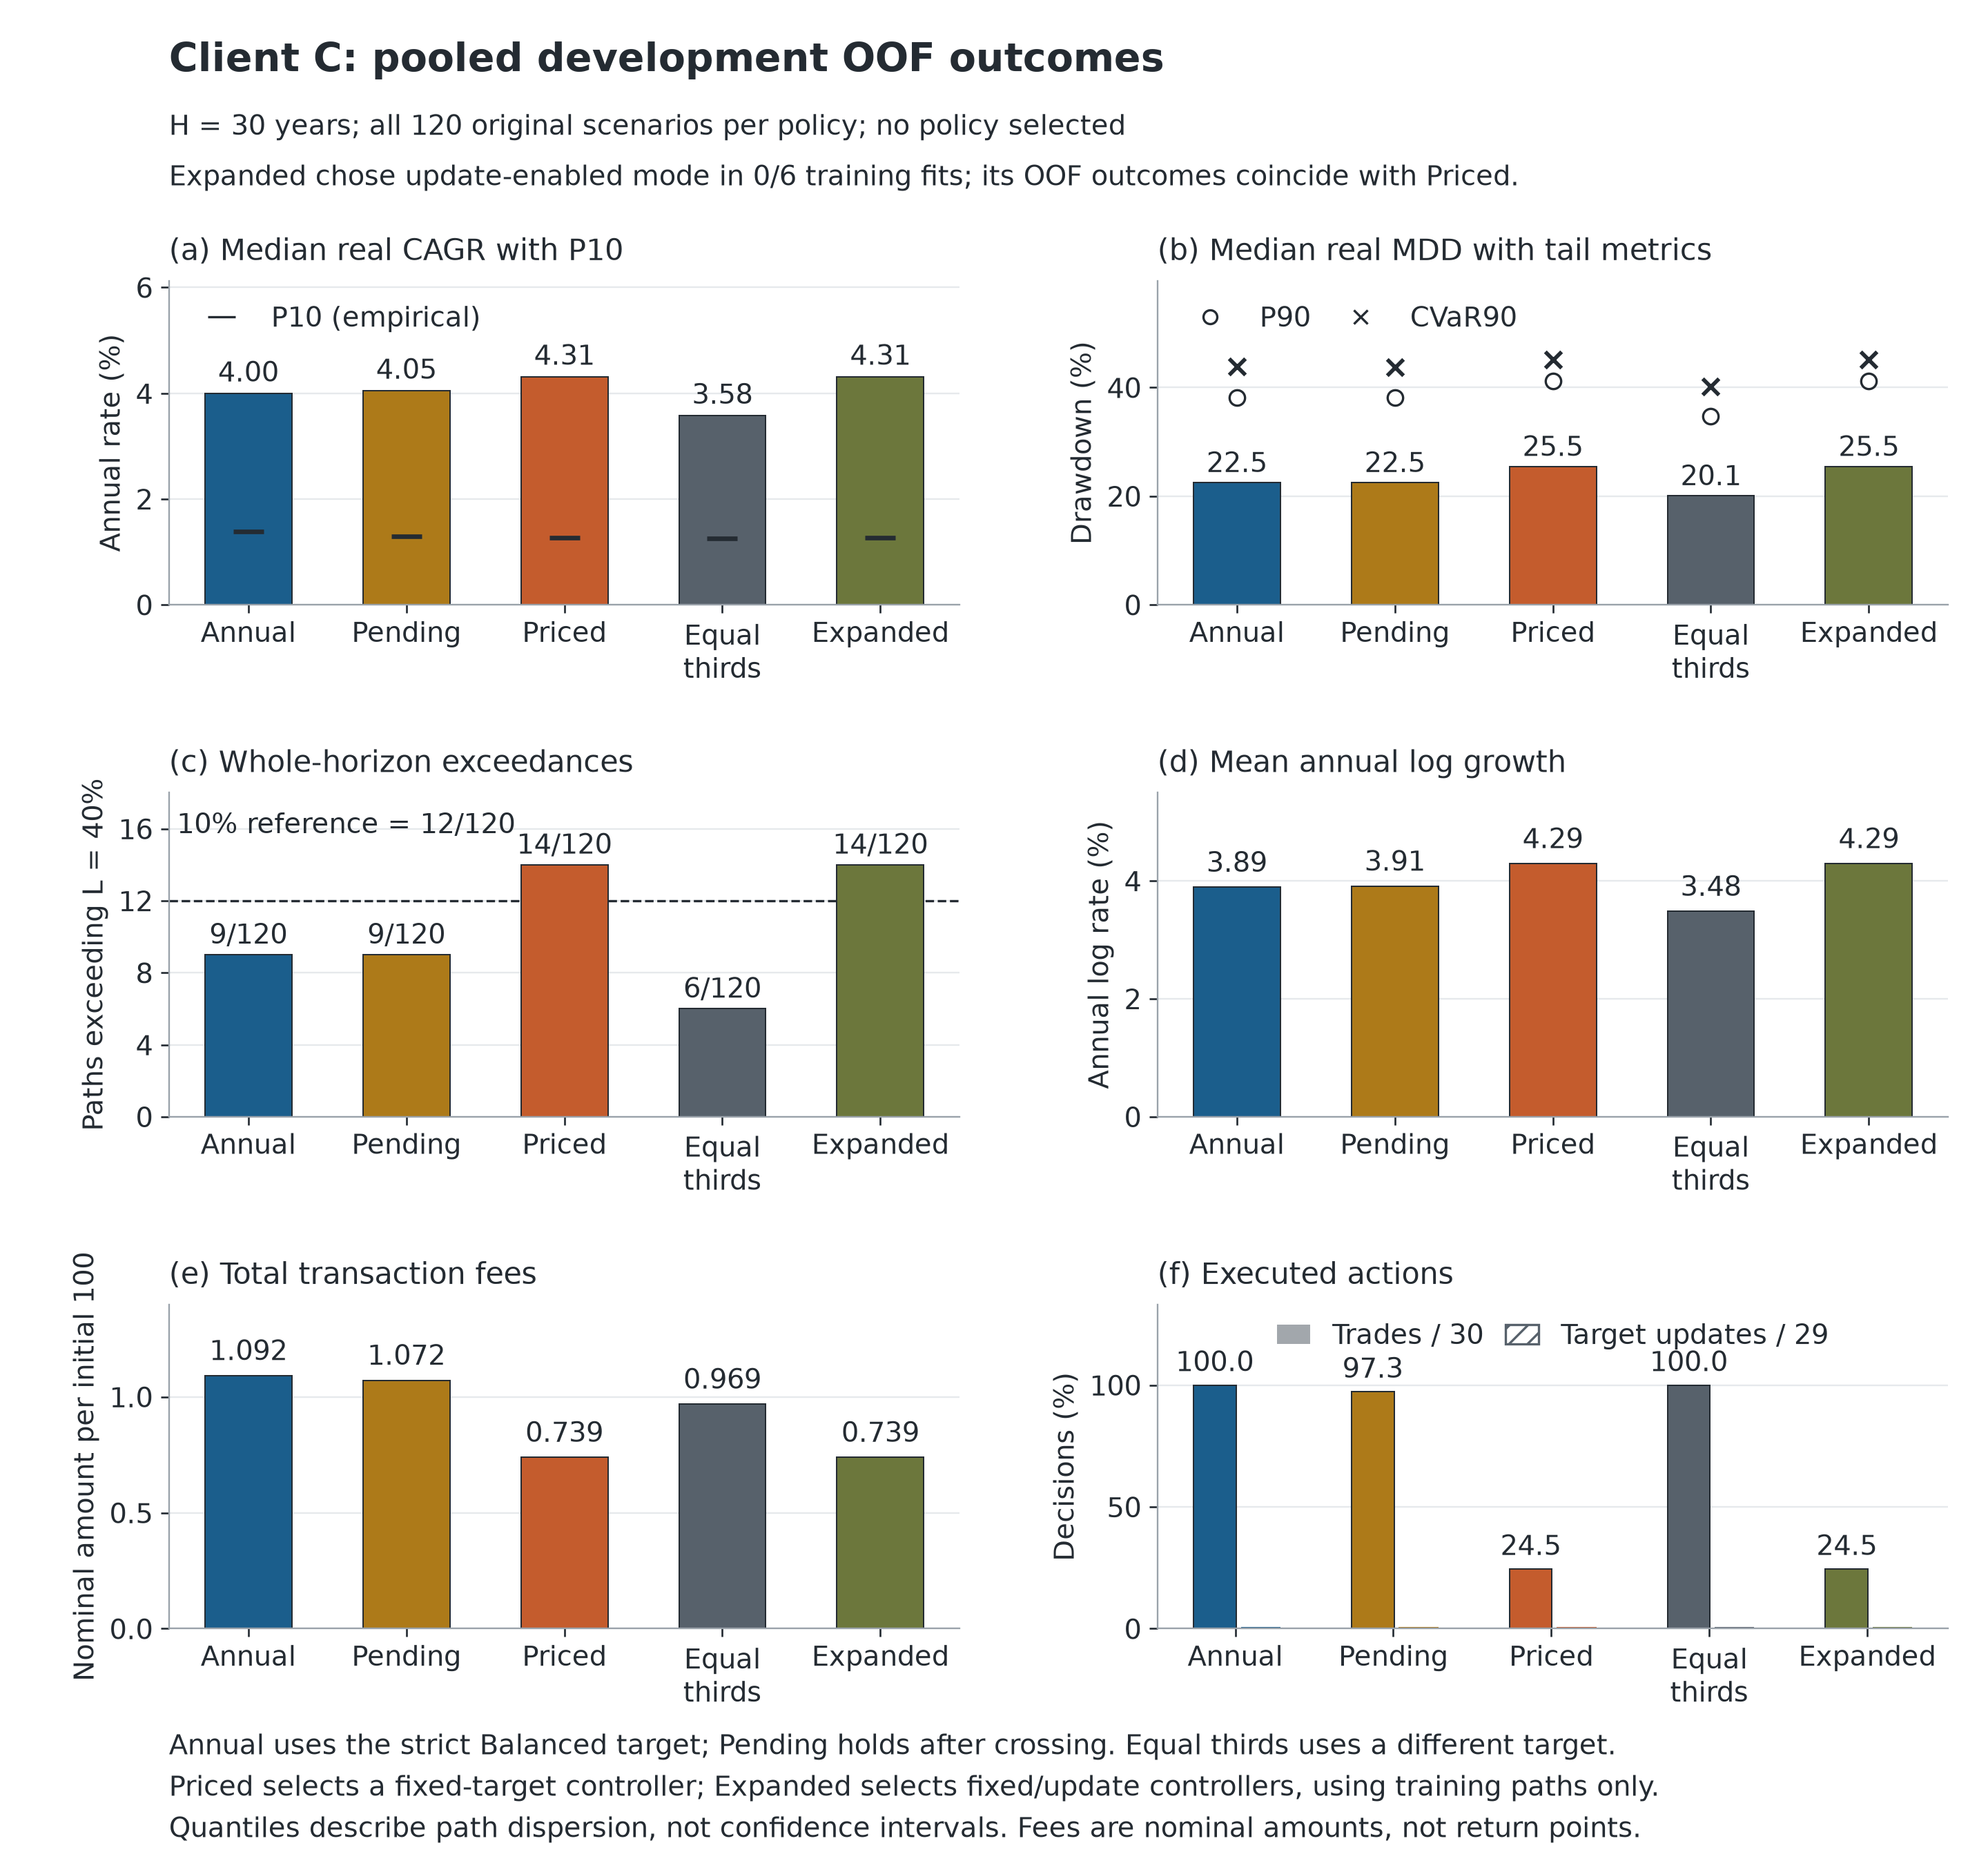


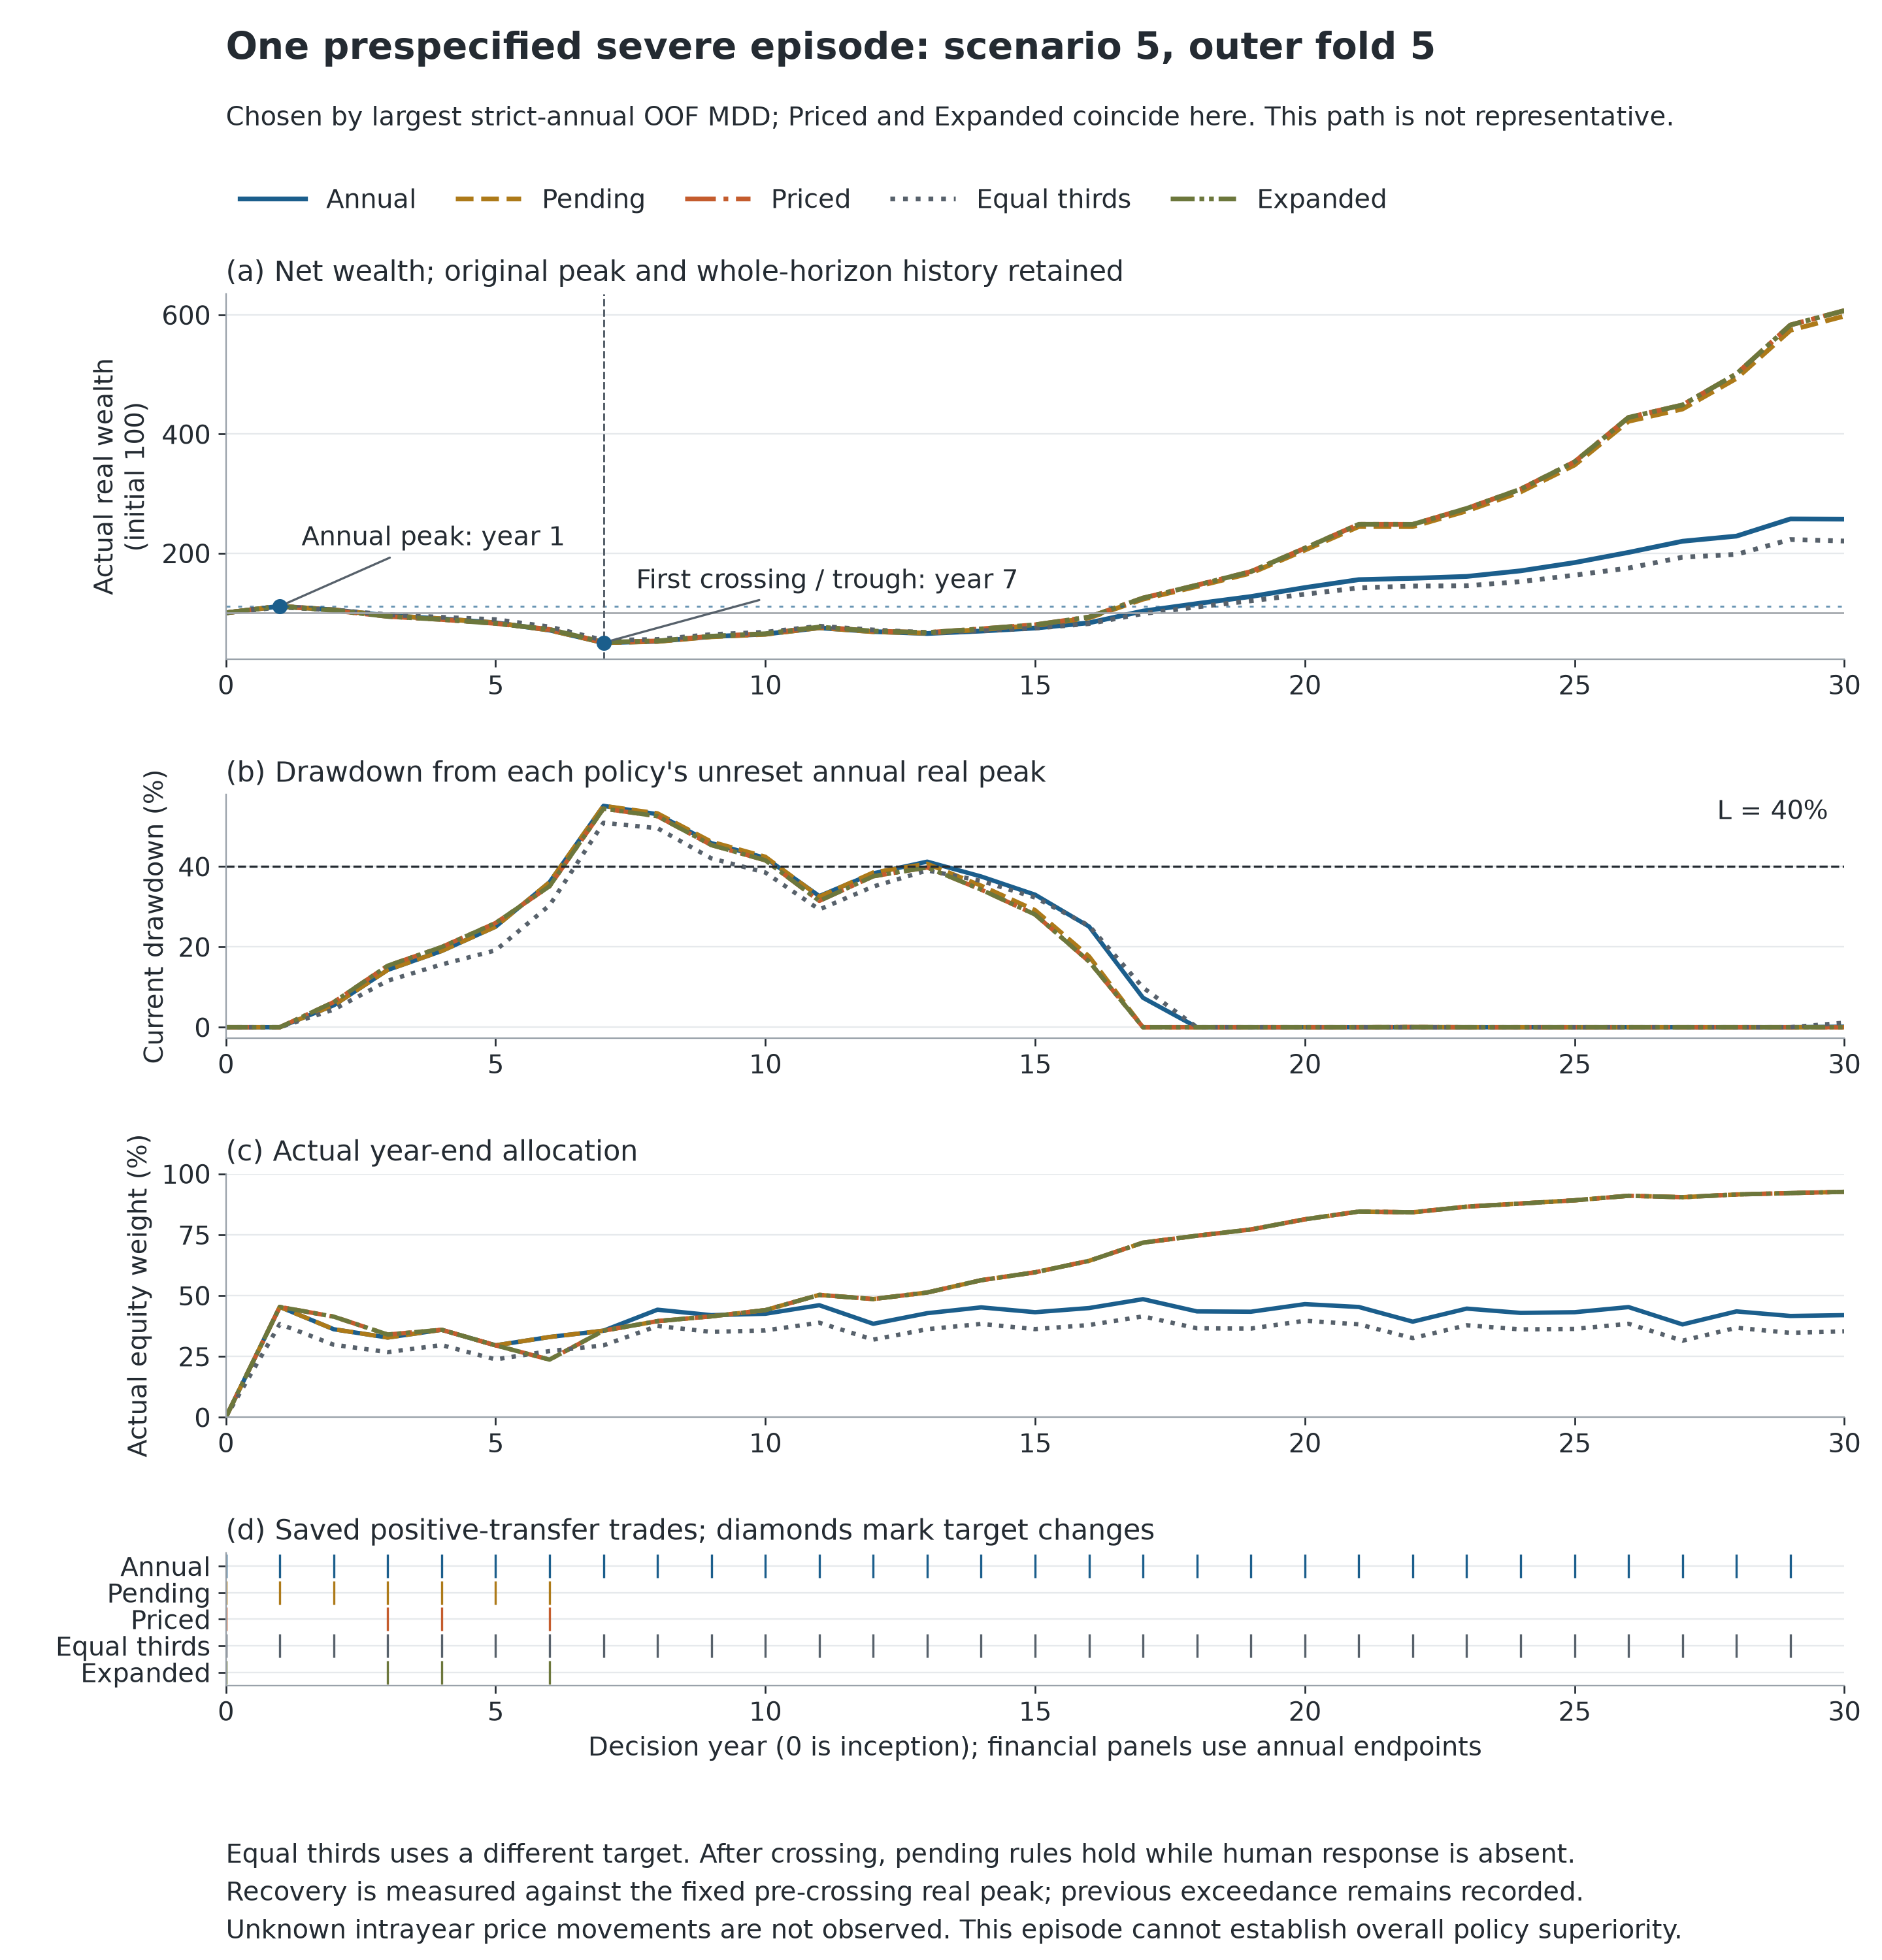

In [24]:
update_root = ROOT / 'results/model_review/bounded_target_updates_v1'
assert readj(update_root / 'independent_audit.json')['status'] == 'passed'
update_summary = pd.read_csv(update_root / 'summary.csv')
update_summary['target_updates_per_29_opportunities'] = update_summary.mean_target_update_fraction * update_summary.horizon / (update_summary.horizon - 1)
show(update_summary[['scope','policy','total_paths','assigned_paths','review_paths',
                     'breach_count','mean_log_growth','median_cagr','p10_cagr','p90_mdd',
                     'mean_trade_fraction','target_updates_per_29_opportunities']],
     {x:'{:.2%}' for x in ['mean_log_growth','median_cagr','p10_cagr','p90_mdd',
                            'mean_trade_fraction','target_updates_per_29_opportunities']})
update_choices = readj(update_root / 'context_selections.json')
show(pd.DataFrame([{'context':context,
    'selected':value['selected_controller']['controller_id'] if value['selected_controller'] else 'Review',
    'training_breach_cap':value['training_breach_cap'],
    'parent_fixed_price_order':value['parent_fixed_selected_candidate_order']}
    for context,value in update_choices.items()]))
q2_current = ROOT / 'results/model_review/q2_execution_development_v2'
assert readj(q2_current / 'manifest.json')['final_scenarios_loaded'] is False
figure(ROOT / 'research/figures/q2_execution_development_v2/01_current_oof_comparison.png',
       'C客户120条OOF路径：严格年度、超限后等待、风险定价、精确三等分及扩展学习流程的共同指标。')
figure(ROOT / 'research/figures/q2_execution_development_v2/02_prespecified_annual_severe_episode.png',
       '按原严格年度规则最大回撤选中的同一严重场景；各策略原始财富、回撤和首次超限后恢复过程。')

### 10.9 费用敏感性也要对准所比较的控制器

逐路径保护规则先在0、0.125%、0.25%、0.5%、1%五档费用下检查；所有档位都没有额外持有，不能据此说减少了交易。对于新选定的固定/可更新控制器，另一项预先声明的压力测试冻结默认费用下训练选中的价格、模式、目标和分配，只改变已知费用输入。预测与真实执行使用同一档费用，不在压力结果上重新学习参数或挑最好费率。

这是已知费用变化下的动作与表现敏感性，不是费用被错误估计时的鲁棒保证；非默认费用下也没有重新获得风险校准证书。固定参数并不意味着固定动作，费用变化会改变预测净收益，进而改变后续整个持仓路径。全轨迹动作变化比例不能解释为保持同一状态时某个动作的因果效果。

所选控制器费用压力结果见： results/model_review/selected_controller_cost_stress_v1


cost_rate,policy,total_paths,assigned_paths,review_paths,breach_count,mean_log_growth,median_cagr,p10_cagr,p90_mdd,mean_nominal_fees,mean_trade_fraction
0.00%,fixed_target_learner,120,120,0,14,4.30%,4.32%,1.28%,41.22%,0.00000,24.86%
0.00%,expanded_target_learner,120,120,0,14,4.30%,4.32%,1.28%,41.22%,0.00000,24.86%
0.00%,annual_then_pending,120,120,0,9,3.92%,4.06%,1.30%,38.14%,0.00000,97.31%
0.00%,equal_thirds_annual,120,120,0,5,3.50%,3.59%,1.27%,34.65%,0.00000,100.00%
0.12%,fixed_target_learner,120,120,0,14,4.30%,4.32%,1.27%,41.22%,0.36853,24.69%
0.12%,expanded_target_learner,120,120,0,14,4.30%,4.32%,1.27%,41.22%,0.36853,24.69%
0.12%,annual_then_pending,120,120,0,9,3.92%,4.06%,1.30%,38.17%,0.53688,97.31%
0.12%,equal_thirds_annual,120,120,0,5,3.49%,3.58%,1.27%,34.67%,0.48527,100.00%
0.25%,fixed_target_learner,120,120,0,14,4.29%,4.31%,1.27%,41.22%,0.73904,24.53%
0.25%,expanded_target_learner,120,120,0,14,4.29%,4.31%,1.27%,41.22%,0.73904,24.53%


五档OOF：两学习器均14/120超限，年度等待均9/120；无法用费用变化消除这一风险差距。



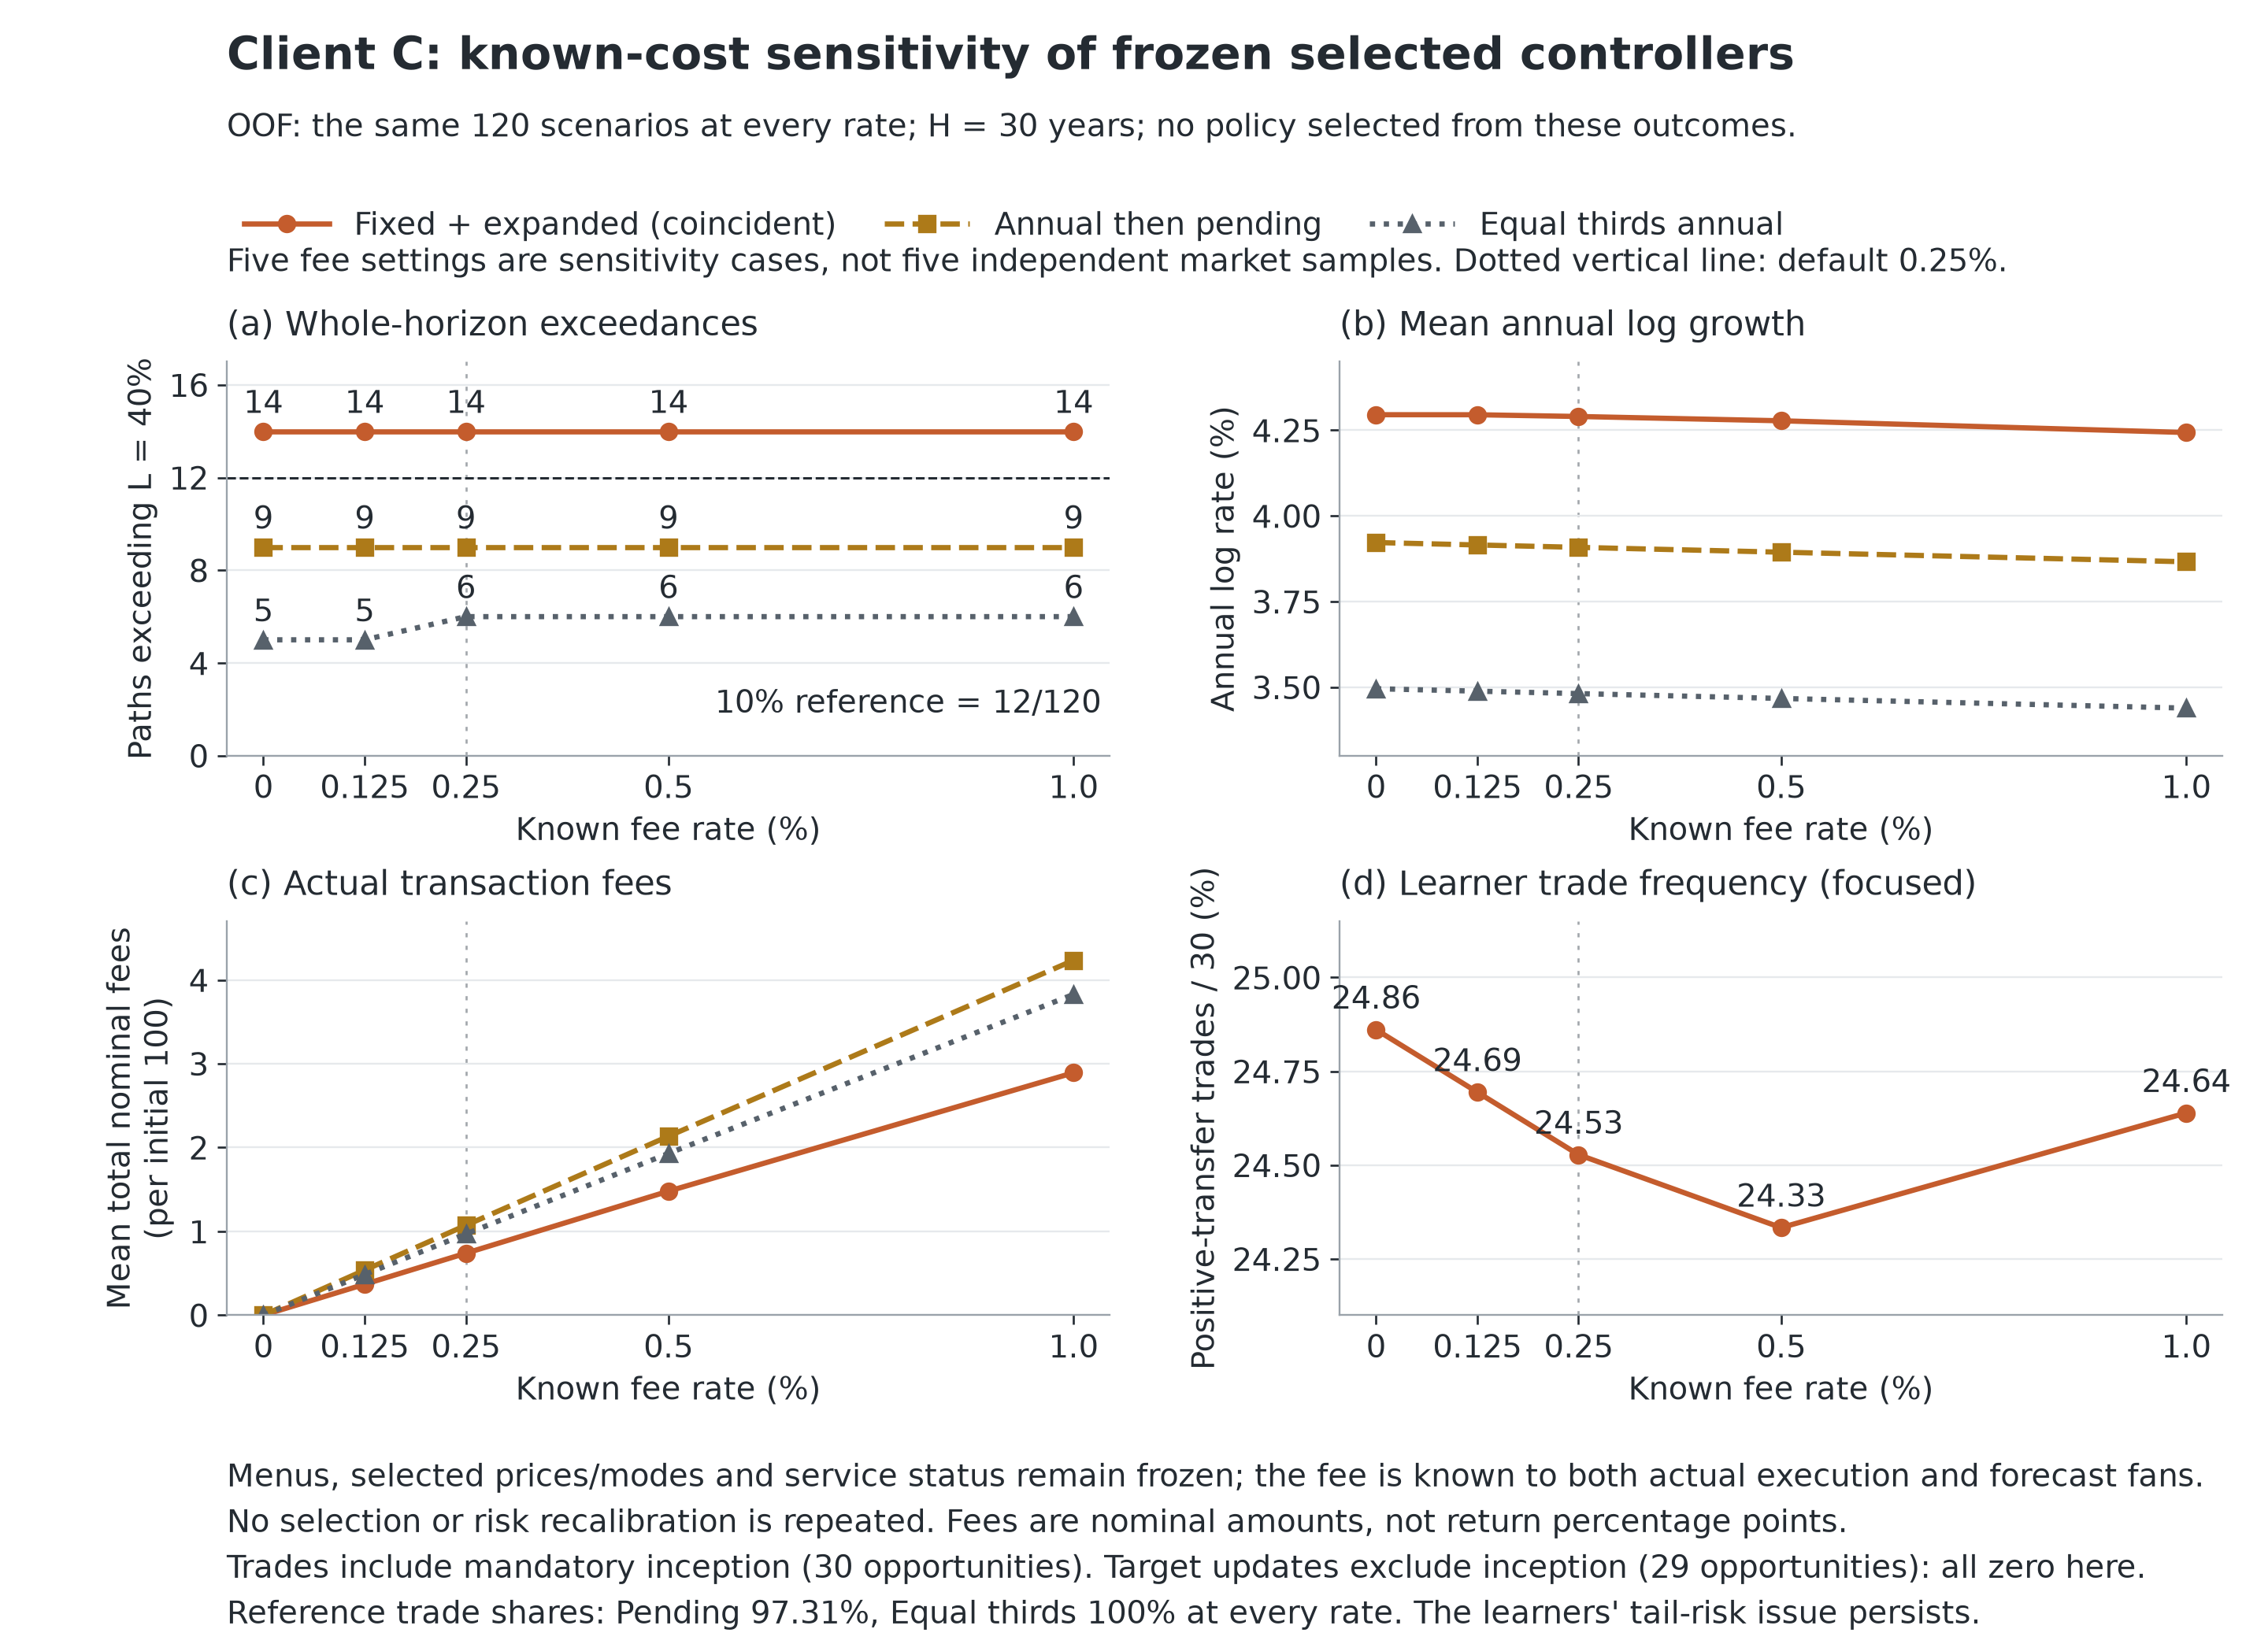

In [25]:
cost_root = ROOT / 'results/model_review/selected_controller_cost_stress_v1'
assert readj(cost_root / 'independent_audit.json')['status'] == 'passed'
cost_summary = pd.read_csv(cost_root / 'summary.csv')
print('所选控制器费用压力结果见：', cost_root.relative_to(ROOT))
show(cost_summary.query("scope == 'outer_oof'")[[
    'cost_rate','policy','total_paths','assigned_paths','review_paths','breach_count',
    'mean_log_growth','median_cagr','p10_cagr','p90_mdd','mean_nominal_fees','mean_trade_fraction']],
    {**{x:'{:.2%}' for x in ['cost_rate','mean_log_growth','median_cagr','p10_cagr','p90_mdd','mean_trade_fraction']},
     'mean_nominal_fees':'{:.5f}'})
print('五档OOF：两学习器均14/120超限，年度等待均9/120；无法用费用变化消除这一风险差距。')
figure(ROOT / 'research/figures/selected_controller_cost_stress/known_cost_oof_sensitivity.png',
       '冻结默认选型的C控制器：已知费用共同改变时的超限、增长、总名义费用和非单调交易比例。')

## 11. 数值核查、复现与结论边界

独立审计不调用原费用执行器，以向量化二分重新解自融资费用，重放232×120条30年路径，独立重算增长、回撤和CVaR，并逐条检查折外冻结分配、Review空结果和120分母。数值正确只能证明计算与规定一致，不能证明目标偏好、同分布假设或未来风险有效。

本次研究已支持：用明确的增长目标和完整期限风险预算替代不明λ；把经验选型、证据强度和人工审核分开；承认精确权重的不稳定性；验证费用一致的有限期限执行原型、完整等待状态、风险调整净收益门槛及目标更新学习流程，并逐项查明其作用和局限。**本次未完成：最终服务菜单和控制器的共同审定、真正人工响应/再入服务资料、最终冻结评估及英文论文。**

转介/等待原设计保存在 `docs/review_pending_design_contract.json`，其独立执行协议和结果另存，保留原设计历史。它分开输入失败、模型失效和客户损失超限；保留原期限、财富历史与超限标记。首次超限后才改变持仓，不能撤销既成事件。人工响应资料缺失时不虚构顾问收益或时延。局部预测、支持内性质、训练筛选、折外结果和未来风险保证必须分别解释；数百万次机械核对也不能增加独立市场样本数。

当前保存结果可用 `scripts/verify_research_checkpoint.py` 做来源指纹与执行证据复核。执行阶段七项实验另提供隔离复现：

```bash
.venv/bin/python scripts/reproduce_execution_stage.py --output results/model_review/execution_stage_reproduction_new
.venv/bin/python scripts/verify_research_checkpoint.py
```

隔离复现逐项在临时副本执行七个冻结runner，比较原始产物的字节或NPZ具名数组的精确值，随后在副本恢复该项的原冻结归档，再运行下一项。这样避免新时间戳改变父manifest/audit指纹，误使下游协议失效；原仓库研究文件前后指纹必须相同。副本只解析1–120开发情景。该工具验证同一实现的可复现性，不是独立算法或新市场证据；新的复现收据必须另选空目录。

更早的静态学习、bootstrap及各项诊断脚本见README的来源索引与每项manifest。**不要在原仓库把全部runner连续重跑并覆盖冻结父归档**：它们的元数据也属于后继协议的一部分。重新设计或重估应建立新研究目录和新协议；不要调用V1的final/reproduce重新选型。笔记本只读取已保存产物，不重新拟合模型。

支持方法定义的主要来源：[NIST精确二项区间](https://www.itl.nist.gov/div898/software/dataplot/refman2/auxillar/exacbino.htm)、[Rockafellar–Uryasev一般损失分布下的CVaR](https://sites.math.washington.edu/~rtr/papers/rtr187-CVaR2.pdf)、[Bengio–Grandvalet交叉验证误差依赖的讨论](https://www.jmlr.org/papers/volume5/grandvalet04a/grandvalet04a.pdf)。具体政策、候选族及本轮数据历史见仓库协议；上述来源不提供我们的客户参数或安全保证。

In [26]:
for key, value in audit['numerical_errors'].items():
    print(key, value)
print('审计：', audit['passed'], '; failures =', len(audit['failures']))
print('本轮源码指纹完整检查：')
manifest = readj(R / 'fit_manifest.json')
for path, expected in manifest['sources'].items():
    assert sha(ROOT / path) == expected, path
print(len(manifest['sources']), '个源/协议文件与拟合时相同。')

synthetic_analytic_fee {'maximum_absolute_error': 1.3877787807814457e-17, 'maximum_error_divided_by_one_plus_abs_reference': 1.2618746047069213e-17, 'compared_values': 3, 'atol': 1e-14, 'rtol': 1e-14}
synthetic_funding {'maximum_absolute_error': 0.0, 'maximum_error_divided_by_one_plus_abs_reference': 0.0, 'compared_values': 3, 'atol': 1e-13, 'rtol': 1e-12}
synthetic_transfer_fee {'maximum_absolute_error': 1.3877787807814457e-17, 'maximum_error_divided_by_one_plus_abs_reference': 1.2618746047069213e-17, 'compared_values': 3, 'atol': 1e-14, 'rtol': 1e-12}
synthetic_zero_cost {'maximum_absolute_error': 0.0, 'maximum_error_divided_by_one_plus_abs_reference': 0.0, 'compared_values': 3, 'atol': 0, 'rtol': 0}
fixed_232_simplex_grid {'maximum_absolute_error': 0.0, 'maximum_error_divided_by_one_plus_abs_reference': 0.0, 'compared_values': 696, 'atol': 1e-15, 'rtol': 0}
self_financing_wealth {'maximum_absolute_error': 1.8189894035458565e-12, 'maximum_error_divided_by_one_plus_abs_reference': 3.9

8 个源/协议文件与拟合时相同。
